In [1]:
from google.colab import drive

drive.mount('/content/drive')



Mounted at /content/drive


In [2]:
zip_path = "/content/drive/MyDrive/real_subset.zip"

import os
import zipfile

extract_dir = "/content/drive/MyDrive/real_subset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Extraction complete.")
print("Top-level contents:", os.listdir(extract_dir))

Extraction complete.
Top-level contents: ['real_subset', 'real_dinov2_features', 'selected_rgb', 'binary_object_crops', 'binary_object_crops_no_margin']


In [3]:

import os
import json

dataset_root = "/content/drive/MyDrive/real_subset/real_subset/train_real"

train_scenes = [
    "000087", "000038", "000040",
    "000011", "000014", "000035"
]

val_scenes = [
    "000028", "000033", "000070",
    "000086", "000026", "000027"
]

for split, scenes in [
    ("TRAIN", train_scenes),
    ("VALIDATION", val_scenes)
]:
    print(f"\n{split}")

    total_images = 0

    for scene in scenes:
        scene_dir = os.path.join(dataset_root, scene)
        rgb_dir = os.path.join(scene_dir, "rgb")

        image_count = len([
            f for f in os.listdir(rgb_dir)
            if f.lower().endswith(".png")
        ])

        with open(os.path.join(scene_dir, "scene_camera.json")) as f:
            camera = json.load(f)

        with open(os.path.join(scene_dir, "scene_gt.json")) as f:
            gt = json.load(f)

        with open(os.path.join(scene_dir, "scene_gt_info.json")) as f:
            info = json.load(f)

        print(
            f"Scene {scene}: "
            f"{image_count} images, "
            f"{len(camera)} camera entries, "
            f"{len(gt)} GT entries, "
            f"{len(info)} GT-info entries"
        )

        assert image_count == 100
        assert len(camera) == 100
        assert len(gt) == 100
        assert len(info) == 100

        total_images += image_count

    print("Total:", total_images)

print("\nDATASET VERIFICATION COMPLETED.")



TRAIN
Scene 000087: 100 images, 100 camera entries, 100 GT entries, 100 GT-info entries
Scene 000038: 100 images, 100 camera entries, 100 GT entries, 100 GT-info entries
Scene 000040: 100 images, 100 camera entries, 100 GT entries, 100 GT-info entries
Scene 000011: 100 images, 100 camera entries, 100 GT entries, 100 GT-info entries
Scene 000014: 100 images, 100 camera entries, 100 GT entries, 100 GT-info entries
Scene 000035: 100 images, 100 camera entries, 100 GT entries, 100 GT-info entries
Total: 600

VALIDATION
Scene 000028: 100 images, 100 camera entries, 100 GT entries, 100 GT-info entries
Scene 000033: 100 images, 100 camera entries, 100 GT entries, 100 GT-info entries
Scene 000070: 100 images, 100 camera entries, 100 GT entries, 100 GT-info entries
Scene 000086: 100 images, 100 camera entries, 100 GT entries, 100 GT-info entries
Scene 000026: 100 images, 100 camera entries, 100 GT entries, 100 GT-info entries
Scene 000027: 100 images, 100 camera entries, 100 GT entries, 100 GT

In [4]:
# Load Dinov2


import torch
import torch.nn.functional as F
import torchvision.transforms as T

from PIL import Image
import numpy as np
import os
import json
from tqdm.auto import tqdm

# Select GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Load frozen DINOv2 ViT-S/14
model = torch.hub.load(
    "facebookresearch/dinov2",
    "dinov2_vits14"
)

model = model.to(device)
model.eval()

# Freeze all model parameters
for parameter in model.parameters():
    parameter.requires_grad = False

print("\nDINOv2 loaded successfully.")
print("Embedding dimension:", model.embed_dim)
print("Patch size:", model.patch_size)


Device: cuda
GPU: Tesla T4
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 224MB/s]



DINOv2 loaded successfully.
Embedding dimension: 384
Patch size: 14


In [5]:
# Preprocessing pipeline


# ImageNet normalization values
IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)

def preprocess_dinov2(image, image_size=518):

    image = image.convert("RGB")

    width, height = image.size

    # Preserve aspect ratio
    scale = image_size / max(width, height)

    new_width = round(width * scale)
    new_height = round(height * scale)

    image = image.resize(
        (new_width, new_height),
        Image.Resampling.BICUBIC
    )

    # Pad to square using ImageNet mean colour
    mean_pixel = tuple(
        int(round(value * 255))
        for value in IMAGENET_MEAN
    )

    canvas = Image.new(
        "RGB",
        (image_size, image_size),
        mean_pixel
    )

    left = (image_size - new_width) // 2
    top = (image_size - new_height) // 2

    canvas.paste(image, (left, top))

    # Convert to normalized tensor
    array = np.asarray(canvas).astype(np.float32) / 255.0

    array = (array - IMAGENET_MEAN) / IMAGENET_STD

    tensor = torch.from_numpy(array).permute(2, 0, 1)

    return canvas, tensor


print("Preprocessing function defined.")


Preprocessing function defined.


In [6]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
# Test preprocessing on one image

# Check the actual directory structure
print("Dataset root exists:", os.path.exists(dataset_root))


Dataset root exists: True


In [8]:

scene = "000087"

scene_dir = os.path.join(dataset_root, scene)

# Load one RGB image
rgb_dir = os.path.join(scene_dir, "rgb")
image_name = sorted(os.listdir(rgb_dir))[0]

image_path = os.path.join(rgb_dir, image_name)

image = Image.open(image_path).convert("RGB")

print("Image:", image_name)
print("Original dimensions:", image.size)

# Preprocess
processed_image, tensor = preprocess_dinov2(image)

print("Processed dimensions:", processed_image.size)
print("Tensor shape:", tensor.shape)

# GPU inference
with torch.inference_mode():
    batch = tensor.unsqueeze(0).to(device)

    features = model.forward_features(batch)["x_norm_clstoken"]

print("\nFeature shape:", features.shape)
print("Feature device:", features.device)
print("NaN values:", torch.isnan(features).sum().item())
print("Infinite values:", torch.isinf(features).sum().item())


Image: 000001.png
Original dimensions: (640, 480)
Processed dimensions: (518, 518)
Tensor shape: torch.Size([3, 518, 518])

Feature shape: torch.Size([1, 384])
Feature device: cuda:0
NaN values: 0
Infinite values: 0


In [9]:
# Feature extraction pipeline

import os
import json
import numpy as np
import torch

from PIL import Image
from tqdm.auto import tqdm
from collections import Counter

# CONFIGURATION

dataset_root = (
    "/content/drive/MyDrive/real_subset/"
    "real_subset/train_real"
)

output_dir = (
    "/content/drive/MyDrive/real_subset/"
    "real_dinov2_features"
)

os.makedirs(output_dir, exist_ok=True)

train_scenes = [
    "000087", "000038", "000040",
    "000011", "000014", "000035"
]

val_scenes = [
    "000028", "000033", "000070",
    "000086", "000026", "000027"
]

MARGIN = 0.35
BATCH_SIZE = 16

# Object ID to category name
object_names = {
    1: "Master Chef Can",
    2: "Cracker Box",
    3: "Sugar Box",
    4: "Tomato Soup Can",
    5: "Mustard Bottle",
    6: "Tuna Fish Can",
    7: "Pudding Box",
    8: "Gelatin Box",
    9: "Potted Meat Can",
    10: "Banana",
    11: "Pitcher Base",
    12: "Bleach Cleanser",
    13: "Bowl",
    14: "Mug",
    15: "Power Drill",
    16: "Wood Block",
    17: "Scissors",
    18: "Large Marker",
    19: "Large Clamp",
    20: "Extra Large Clamp",
    21: "Foam Brick"
}

# COLLECT OBJECT INSTANCE RECORDS

def collect_records(scenes, split):

    records = []

    for scene in tqdm(scenes, desc=f"Reading {split}"):

        scene_dir = os.path.join(dataset_root, scene)

        camera_path = os.path.join(
            scene_dir, "scene_camera.json"
        )

        gt_path = os.path.join(
            scene_dir, "scene_gt.json"
        )

        info_path = os.path.join(
            scene_dir, "scene_gt_info.json"
        )

        with open(camera_path, "r") as f:
            camera_data = json.load(f)

        with open(gt_path, "r") as f:
            gt_data = json.load(f)

        with open(info_path, "r") as f:
            info_data = json.load(f)

        for image_id in sorted(camera_data, key=int):

            if image_id not in gt_data or image_id not in info_data:
                raise ValueError(
                    f"Missing annotations: scene {scene}, "
                    f"image {image_id}"
                )

            gt_objects = gt_data[image_id]
            info_objects = info_data[image_id]

            if len(gt_objects) != len(info_objects):
                raise ValueError(
                    f"Object annotation mismatch: "
                    f"{scene}, image {image_id}"
                )

            image_name = f"{int(image_id):06d}.png"

            image_path = os.path.join(
                scene_dir, "rgb", image_name
            )

            if not os.path.isfile(image_path):
                raise FileNotFoundError(image_path)

            for gt, info in zip(gt_objects, info_objects):

                object_id = int(gt["obj_id"])

                visibility = float(info["visib_fract"])

                # Match the synthetic experiment:
                # Training uses visibility >= 20%.
                # Validation retains every visible instance.
                if split == "train" and visibility < 0.20:
                    continue

                if split == "val" and visibility <= 0:
                    continue

                bbox = info["bbox_obj"]

                x, y, w, h = map(float, bbox)

                if w <= 0 or h <= 0:
                    continue

                records.append({
                    "image_path": image_path,
                    "bbox": [x, y, w, h],
                    "object_id": object_id,
                    "label": object_id - 1,
                    "visibility": visibility,
                    "scene_id": scene,
                    "image_id": image_id
                })

    return records


train_records = collect_records(train_scenes, "train")
val_records = collect_records(val_scenes, "val")

print("\nRECORD SUMMARY")
print("Training instances:", len(train_records))
print("Validation instances:", len(val_records))

print(
    "Training classes:",
    len(set(r["object_id"] for r in train_records))
)

print(
    "Validation classes:",
    len(set(r["object_id"] for r in val_records))
)

# EXTRACT EXPANDED OBJECT CROPS

def extract_object_crop(image, bbox, margin=0.35):

    x, y, w, h = bbox

    x1 = int(x - margin * w)
    y1 = int(y - margin * h)
    x2 = int(x + w + margin * w)
    y2 = int(y + h + margin * h)

    image_width, image_height = image.size

    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(image_width, x2)
    y2 = min(image_height, y2)

    if x2 <= x1 or y2 <= y1:
        raise ValueError("Invalid crop coordinates")

    return image.crop((x1, y1, x2, y2))


# BATCHED GPU FEATURE EXTRACTION

def extract_features(records, split):

    all_features = []

    # Keep track of metadata in the same order as features
    metadata = {
        "labels": [],
        "object_ids": [],
        "visibility": [],
        "scene_ids": [],
        "image_ids": []
    }

    for start in tqdm(
        range(0, len(records), BATCH_SIZE),
        desc=f"Extracting {split} features"
    ):

        batch_records = records[
            start:start + BATCH_SIZE
        ]

        tensors = []

        for record in batch_records:

            with Image.open(record["image_path"]) as source:
                image = source.convert("RGB")

                crop = extract_object_crop(
                    image,
                    record["bbox"],
                    margin=MARGIN
                )

                _, tensor = preprocess_dinov2(crop)

            tensors.append(tensor)

        batch = torch.stack(tensors).to(device)

        with torch.inference_mode():

            features = model.forward_features(batch)[
                "x_norm_clstoken"
            ]

        features = features.float().cpu().numpy()

        all_features.append(features)

        for record in batch_records:

            metadata["labels"].append(record["label"])
            metadata["object_ids"].append(record["object_id"])
            metadata["visibility"].append(record["visibility"])
            metadata["scene_ids"].append(record["scene_id"])
            metadata["image_ids"].append(record["image_id"])

    X = np.concatenate(all_features, axis=0)

    metadata = {
        "y": np.asarray(metadata["labels"], dtype=np.int64),
        "object_ids": np.asarray(metadata["object_ids"], dtype=np.int64),
        "visibility": np.asarray(metadata["visibility"], dtype=np.float32),
        "scene_ids": np.asarray(metadata["scene_ids"], dtype=str),
        "image_ids": np.asarray(metadata["image_ids"], dtype=str)
    }

    return X, metadata


# EXTRACT TRAINING FEATURES

X_train_real, train_meta = extract_features(
    train_records,
    "train"
)

# EXTRACT VALIDATION FEATURES

X_val_real, val_meta = extract_features(
    val_records,
    "val"
)

# VERIFY FEATURES

print("\nFEATURE VERIFICATION")

print("Training features:", X_train_real.shape)
print("Validation features:", X_val_real.shape)

print("Training labels:", train_meta["y"].shape)
print("Validation labels:", val_meta["y"].shape)

print("Training NaN:", np.isnan(X_train_real).sum())
print("Validation NaN:", np.isnan(X_val_real).sum())

print("Training Inf:", np.isinf(X_train_real).sum())
print("Validation Inf:", np.isinf(X_val_real).sum())

assert X_train_real.shape[1] == 384
assert X_val_real.shape[1] == 384

assert len(X_train_real) == len(train_meta["y"])
assert len(X_val_real) == len(val_meta["y"])

assert np.isfinite(X_train_real).all()
assert np.isfinite(X_val_real).all()

assert set(train_meta["y"]).issubset(set(range(21)))
assert set(val_meta["y"]).issubset(set(range(21)))

# SAVE FEATURES AND METADATA

np.savez_compressed(
    os.path.join(output_dir, "train_real_features.npz"),
    X=X_train_real,
    **train_meta
)

np.savez_compressed(
    os.path.join(output_dir, "val_real_features.npz"),
    X=X_val_real,
    **val_meta
)

print("\nSAVING COMPLETED")
print("Output directory:", output_dir)

print(
    "Training file:",
    os.path.getsize(
        os.path.join(output_dir, "train_real_features.npz")
    ) / (1024 ** 2),
    "MB"
)

print(
    "Validation file:",
    os.path.getsize(
        os.path.join(output_dir, "val_real_features.npz")
    ) / (1024 ** 2),
    "MB"
)


Reading train:   0%|          | 0/6 [00:00<?, ?it/s]

Reading val:   0%|          | 0/6 [00:00<?, ?it/s]


RECORD SUMMARY
Training instances: 3689
Validation instances: 2916
Training classes: 21
Validation classes: 21


Extracting train features:   0%|          | 0/231 [00:00<?, ?it/s]

Extracting val features:   0%|          | 0/183 [00:00<?, ?it/s]


FEATURE VERIFICATION
Training features: (3689, 384)
Validation features: (2916, 384)
Training labels: (3689,)
Validation labels: (2916,)
Training NaN: 0
Validation NaN: 0
Training Inf: 0
Validation Inf: 0

SAVING COMPLETED
Output directory: /content/drive/MyDrive/real_subset/real_dinov2_features
Training file: 5.034096717834473 MB
Validation file: 3.978011131286621 MB


In [10]:
# Training and validation pipeline

import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# TRAIN CLASSIFIER

real_classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=1.0,
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    )
)

real_classifier.fit(
    X_train_real,
    train_meta["y"]
)

print("Real-data classifier trained successfully.")

# VALIDATION PREDICTIONS

y_true = val_meta["y"]
y_pred = real_classifier.predict(X_val_real)

y_prob = real_classifier.predict_proba(X_val_real)

# OVERALL METRICS

accuracy = accuracy_score(y_true, y_pred)

balanced_acc = balanced_accuracy_score(
    y_true, y_pred
)

macro_f1 = f1_score(
    y_true, y_pred,
    average="macro"
)

print("\nREAL-DATA VALIDATION")

print(f"Accuracy:          {accuracy:.4f}")
print(f"Balanced accuracy: {balanced_acc:.4f}")
print(f"Macro F1:          {macro_f1:.4f}")

# PER-CLASS PERFORMANCE

class_names = [
    object_names[i]
    for i in range(1, 22)
]

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(21)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

class_results = pd.DataFrame([
    {
        "Object": name,
        "Precision": report[name]["precision"],
        "Recall": report[name]["recall"],
        "F1": report[name]["f1-score"],
        "Support": report[name]["support"]
    }
    for name in class_names
])

print("\nPER-CLASS PERFORMANCE")

display(
    class_results.round(4)
)

# VISIBILITY-BASED PERFORMANCE

visibility = val_meta["visibility"]

bins = [0, 0.2, 0.4, 0.6, 0.8, 1.000001]

bin_labels = [
    "0-20%",
    "20-40%",
    "40-60%",
    "60-80%",
    "80-100%"
]

visibility_results = []

for i in range(len(bins) - 1):

    mask = (
        (visibility >= bins[i]) &
        (visibility < bins[i + 1])
    )

    if mask.sum() == 0:
        continue

    visibility_results.append({
        "Visibility": bin_labels[i],
        "Samples": int(mask.sum()),
        "Accuracy": accuracy_score(
            y_true[mask],
            y_pred[mask]
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_true[mask],
            y_pred[mask]
        ),
        "Macro F1": f1_score(
            y_true[mask],
            y_pred[mask],
            average="macro",
            zero_division=0
        )
    })

visibility_results = pd.DataFrame(
    visibility_results
)

print("\nPERFORMANCE BY VISIBILITY")

display(
    visibility_results.round(4)
)

# CONFUSION MATRIX

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(21))
)

print("\nConfusion matrix shape:", cm.shape)


Real-data classifier trained successfully.

REAL-DATA VALIDATION
Accuracy:          0.3741
Balanced accuracy: 0.3674
Macro F1:          0.3166

PER-CLASS PERFORMANCE


,Object,Precision,Recall,F1,Support
0,Master Chef Can,0.0000,0.0000,0.0000,100.0
1,Cracker Box,0.6452,0.6000,0.6218,100.0
2,Sugar Box,0.0000,0.0000,0.0000,100.0
3,Tomato Soup Can,0.0000,0.0000,0.0000,100.0
4,Mustard Bottle,0.8409,0.4933,0.6218,75.0
5,Tuna Fish Can,0.2763,0.8068,0.4116,88.0
6,Pudding Box,0.0000,0.0000,0.0000,195.0
7,Gelatin Box,0.0000,0.0000,0.0000,100.0
8,Potted Meat Can,0.5507,0.9157,0.6878,83.0
9,Banana,0.3000,0.4500,0.3600,100.0



PERFORMANCE BY VISIBILITY


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,Visibility,Samples,Accuracy,Balanced accuracy,Macro F1
0,0-20%,31,0.0000,0.0000,0.0000
1,20-40%,40,0.0500,0.0333,0.0357
2,40-60%,186,0.0591,0.2126,0.1704
3,60-80%,436,0.1743,0.2809,0.1817
4,80-100%,2223,0.4507,0.3934,0.3573



Confusion matrix shape: (21, 21)


In [11]:

from collections import Counter
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# CLASS DISTRIBUTION

class_names = [
    object_names[i] for i in range(1, 22)
]

train_counts = Counter(train_meta["y"])
val_counts = Counter(val_meta["y"])

pred_counts = Counter(y_pred)

distribution = pd.DataFrame({
    "Object": class_names,
    "Training": [
        train_counts.get(i, 0) for i in range(21)
    ],
    "Validation": [
        val_counts.get(i, 0) for i in range(21)
    ],
    "Predicted": [
        pred_counts.get(i, 0) for i in range(21)
    ]
})

print("CLASS DISTRIBUTIONS")
display(distribution)

# TRAINING PERFORMANCE

train_predictions = real_classifier.predict(X_train_real)

print("\nTRAINING PERFORMANCE")

print(
    "Training accuracy:",
    round(
        accuracy_score(
            train_meta["y"],
            train_predictions
        ), 4
    )
)

print(
    "Training balanced accuracy:",
    round(
        balanced_accuracy_score(
            train_meta["y"],
            train_predictions
        ), 4
    )
)

print(
    "Training macro F1:",
    round(
        f1_score(
            train_meta["y"],
            train_predictions,
            labels=np.arange(21),
            average="macro",
            zero_division=0
        ), 4
    )
)

# VALIDATION METRICS WITH ALL 21 CLASSES

print("\nVALIDATION METRICS")

print(
    "Accuracy:",
    round(accuracy_score(y_true, y_pred), 4)
)

print(
    "Balanced accuracy:",
    round(balanced_accuracy_score(y_true, y_pred), 4)
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_true,
            y_pred,
            labels=np.arange(21),
            average="macro",
            zero_division=0
        ), 4
    )
)

# MOST COMMON CONFUSIONS

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(21)
)

confusions = []

for true_id in range(21):
    for predicted_id in range(21):

        if true_id == predicted_id:
            continue

        count = cm[true_id, predicted_id]

        if count > 0:
            confusions.append({
                "Actual object": class_names[true_id],
                "Predicted as": class_names[predicted_id],
                "Count": int(count)
            })

confusion_table = pd.DataFrame(confusions)

confusion_table = confusion_table.sort_values(
    "Count",
    ascending=False
).head(20)

print("\nTOP 20 CONFUSIONS")
display(confusion_table)

# PREDICTION CONCENTRATION

print("\nPREDICTION DISTRIBUTION")

for class_id, count in sorted(pred_counts.items()):
    print(
        f"{class_names[class_id]}: "
        f"{count} predictions "
        f"({100 * count / len(y_pred):.1f}%)"
    )


CLASS DISTRIBUTIONS


,Object,Training,Validation,Predicted
0,Master Chef Can,200,100,37
1,Cracker Box,100,100,93
2,Sugar Box,100,100,41
3,Tomato Soup Can,100,100,0
4,Mustard Bottle,200,75,44
5,Tuna Fish Can,100,88,257
6,Pudding Box,100,195,4
7,Gelatin Box,299,100,136
8,Potted Meat Can,200,83,138
9,Banana,300,100,150



TRAINING PERFORMANCE
Training accuracy: 1.0
Training balanced accuracy: 1.0
Training macro F1: 1.0

VALIDATION METRICS
Accuracy: 0.3741
Balanced accuracy: 0.3674
Macro F1: 0.3166

TOP 20 CONFUSIONS


,Actual object,Predicted as,Count
101,Large Clamp,Extra Large Clamp,127
67,Mug,Scissors,99
63,Bowl,Mug,86
33,Pudding Box,Tuna Fish Can,76
46,Gelatin Box,Foam Brick,72
91,Large Marker,Gelatin Box,62
92,Large Marker,Bowl,60
77,Wood Block,Tuna Fish Can,59
88,Scissors,Extra Large Clamp,58
37,Pudding Box,Mug,55



PREDICTION DISTRIBUTION
Master Chef Can: 37 predictions (1.3%)
Cracker Box: 93 predictions (3.2%)
Sugar Box: 41 predictions (1.4%)
Mustard Bottle: 44 predictions (1.5%)
Tuna Fish Can: 257 predictions (8.8%)
Pudding Box: 4 predictions (0.1%)
Gelatin Box: 136 predictions (4.7%)
Potted Meat Can: 138 predictions (4.7%)
Banana: 150 predictions (5.1%)
Pitcher Base: 92 predictions (3.2%)
Bleach Cleanser: 164 predictions (5.6%)
Bowl: 101 predictions (3.5%)
Mug: 473 predictions (16.2%)
Power Drill: 87 predictions (3.0%)
Wood Block: 2 predictions (0.1%)
Scissors: 356 predictions (12.2%)
Large Marker: 134 predictions (4.6%)
Large Clamp: 134 predictions (4.6%)
Extra Large Clamp: 312 predictions (10.7%)
Foam Brick: 161 predictions (5.5%)


In [12]:

import pandas as pd
import numpy as np

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

C_values = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0]

results = []

for C in C_values:

    print(f"Testing C = {C}")

    classifier = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=C,
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        )
    )

    classifier.fit(
        X_train_real,
        train_meta["y"]
    )

    # Training predictions
    train_pred = classifier.predict(X_train_real)

    # Validation predictions
    val_pred = classifier.predict(X_val_real)

    results.append({
        "C": C,

        "Train accuracy": accuracy_score(
            train_meta["y"], train_pred
        ),

        "Validation accuracy": accuracy_score(
            val_meta["y"], val_pred
        ),

        "Validation balanced accuracy": balanced_accuracy_score(
            val_meta["y"], val_pred
        ),

        "Validation macro F1": f1_score(
            val_meta["y"],
            val_pred,
            labels=np.arange(21),
            average="macro",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("\nREGULARISATION EXPERIMENT")

display(results_df.round(4))


Testing C = 0.0001
Testing C = 0.001
Testing C = 0.01
Testing C = 0.1
Testing C = 1.0
Testing C = 10.0

REGULARISATION EXPERIMENT


,C,Train accuracy,Validation accuracy,Validation balanced accuracy,Validation macro F1
0,0.0001,0.7360,0.3844,0.3708,0.3094
1,0.0010,0.9282,0.4256,0.4193,0.3476
2,0.0100,0.9962,0.4201,0.4156,0.3636
3,0.1000,1.0000,0.4019,0.3966,0.3418
4,1.0000,1.0000,0.3741,0.3674,0.3166
5,10.0000,1.0000,0.4005,0.3896,0.3451


In [13]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

candidate_models = {}

for C in [0.001, 0.01]:

    clf = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=C,
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        )
    )

    clf.fit(X_train_real, train_meta["y"])

    candidate_models[C] = clf

    print(f"\n C = {C}")

    predictions = clf.predict(X_val_real)

    print(classification_report(
        val_meta["y"],
        predictions,
        labels=np.arange(21),
        target_names=class_names,
        zero_division=0
    ))



 C = 0.001
                   precision    recall  f1-score   support

  Master Chef Can       0.00      0.00      0.00       100
      Cracker Box       0.57      0.52      0.54       100
        Sugar Box       0.00      0.00      0.00       100
  Tomato Soup Can       0.00      0.00      0.00       100
   Mustard Bottle       0.83      0.07      0.12        75
    Tuna Fish Can       0.30      0.88      0.45        88
      Pudding Box       0.00      0.00      0.00       195
      Gelatin Box       0.00      0.00      0.00       100
  Potted Meat Can       0.76      0.88      0.82        83
           Banana       0.67      0.80      0.73       100
     Pitcher Base       0.59      0.94      0.73       100
  Bleach Cleanser       0.22      0.62      0.32       100
             Bowl       0.14      0.26      0.18       100
              Mug       0.47      0.63      0.54       300
      Power Drill       0.49      0.91      0.64       100
       Wood Block       0.00      0.00     

In [14]:

visibility = val_meta["visibility"]
y_true = val_meta["y"]

visibility_bins = [
    (0.0, 0.2),
    (0.2, 0.4),
    (0.4, 0.6),
    (0.6, 0.8),
    (0.8, 1.01)
]

visibility_results = []

for C, clf in candidate_models.items():

    predictions = clf.predict(X_val_real)

    for lower, upper in visibility_bins:

        mask = (
            (visibility >= lower) &
            (visibility < upper)
        )

        if mask.sum() == 0:
            continue

        visibility_results.append({
            "C": C,
            "Visibility": f"{lower:.0%}-{min(upper, 1.0):.0%}",
            "Samples": int(mask.sum()),
            "Accuracy": accuracy_score(
                y_true[mask],
                predictions[mask]
            ),
            "Balanced accuracy": balanced_accuracy_score(
                y_true[mask],
                predictions[mask]
            ),
            "Macro F1": f1_score(
                y_true[mask],
                predictions[mask],
                labels=np.arange(21),
                average="macro",
                zero_division=0
            )
        })

visibility_df = pd.DataFrame(visibility_results)

display(
    visibility_df.round(4)
)


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics

,C,Visibility,Samples,Accuracy,Balanced accuracy,Macro F1
0,0.001,0%-20%,31,0.0323,0.0250,0.0159
1,0.001,20%-40%,40,0.0750,0.0667,0.0429
2,0.001,40%-60%,186,0.0806,0.1861,0.0923
3,0.001,60%-80%,436,0.2362,0.5001,0.2295
4,0.001,80%-100%,2223,0.5034,0.4545,0.4054
5,0.010,0%-20%,31,0.0000,0.0000,0.0000
6,0.010,20%-40%,40,0.0750,0.0667,0.0429
7,0.010,40%-60%,186,0.0753,0.1837,0.0885
8,0.010,60%-80%,436,0.2179,0.4325,0.2389
9,0.010,80%-100%,2223,0.5007,0.4487,0.4165


In [15]:
# Train the binary classifier using onlty the dinov2 features
# of the two objects of interest

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Target BOP object IDs
target_ids = [20, 21]

# Select only the two target objects
train_mask = np.isin(train_meta["object_ids"], target_ids)
val_mask = np.isin(val_meta["object_ids"], target_ids)

X_train_binary = X_train_real[train_mask]
X_val_binary = X_val_real[val_mask]

# 0 = Extra Large Clamp
# 1 = Foam Brick
y_train_binary = (
    train_meta["object_ids"][train_mask] == 21
).astype(int)

y_val_binary = (
    val_meta["object_ids"][val_mask] == 21
).astype(int)

print("Training samples:", len(y_train_binary))
print("Validation samples:", len(y_val_binary))

print("\nTraining distribution:")
print(pd.Series(y_train_binary).value_counts().sort_index())

print("\nValidation distribution:")
print(pd.Series(y_val_binary).value_counts().sort_index())


# Compare regularisation strengths
binary_results = []
binary_models = {}

for C in [0.001, 0.01, 0.1, 1.0]:

    clf = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=C,
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        )
    )

    clf.fit(X_train_binary, y_train_binary)

    train_pred = clf.predict(X_train_binary)
    val_pred = clf.predict(X_val_binary)

    binary_models[C] = clf

    binary_results.append({
        "C": C,
        "Train accuracy": accuracy_score(
            y_train_binary, train_pred
        ),
        "Validation accuracy": accuracy_score(
            y_val_binary, val_pred
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_val_binary, val_pred
        ),
        "Macro F1": f1_score(
            y_val_binary,
            val_pred,
            average="macro",
            zero_division=0
        )
    })

binary_results_df = pd.DataFrame(binary_results)

print("\nBINARY CLASSIFICATION RESULTS")
display(binary_results_df.round(4))


Training samples: 290
Validation samples: 200

Training distribution:
0     91
1    199
Name: count, dtype: int64

Validation distribution:
0    100
1    100
Name: count, dtype: int64

BINARY CLASSIFICATION RESULTS


,C,Train accuracy,Validation accuracy,Balanced accuracy,Macro F1
0,0.001,1.0,1.0,1.0,1.0
1,0.010,1.0,1.0,1.0,1.0
2,0.100,1.0,1.0,1.0,1.0
3,1.000,1.0,1.0,1.0,1.0


In [16]:
# Inspect its predictions


# Select the configuration with the highest validation macro F1
best_row = binary_results_df.loc[
    binary_results_df["Macro F1"].idxmax()
]

best_C = best_row["C"]
best_binary_model = binary_models[best_C]

binary_predictions = best_binary_model.predict(X_val_binary)

print("Selected C:", best_C)

print("\nClassification report:")

print(classification_report(
    y_val_binary,
    binary_predictions,
    labels=[0, 1],
    target_names=["Extra Large Clamp", "Foam Brick"],
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(
    y_val_binary,
    binary_predictions,
    labels=[0, 1]
))


Selected C: 0.001

Classification report:
                   precision    recall  f1-score   support

Extra Large Clamp       1.00      1.00      1.00       100
       Foam Brick       1.00      1.00      1.00       100

         accuracy                           1.00       200
        macro avg       1.00      1.00      1.00       200
     weighted avg       1.00      1.00      1.00       200


Confusion matrix:
[[100   0]
 [  0 100]]


In [17]:
# Test performance at different visibility levels


# Use the selected binary classifier
predictions = best_binary_model.predict(X_val_binary)
probabilities = best_binary_model.predict_proba(X_val_binary)

# Validation metadata for the two target objects
binary_visibility = val_meta["visibility"][val_mask]
binary_scene_ids = val_meta["scene_ids"][val_mask]

visibility_bins = [
    (0.0, 0.2),
    (0.2, 0.4),
    (0.4, 0.6),
    (0.6, 0.8),
    (0.8, 1.01)
]

rows = []

for lower, upper in visibility_bins:

    mask = (
        (binary_visibility >= lower) &
        (binary_visibility < upper)
    )

    if mask.sum() == 0:
        continue

    for class_id, class_name in [
        (0, "Extra Large Clamp"),
        (1, "Foam Brick")
    ]:

        class_mask = mask & (y_val_binary == class_id)

        if class_mask.sum() == 0:
            continue

        rows.append({
            "Visibility": f"{lower:.0%}-{min(upper, 1.0):.0%}",
            "Object": class_name,
            "Samples": int(class_mask.sum()),
            "Correct": int(
                (predictions[class_mask] == y_val_binary[class_mask]).sum()
            ),
            "Accuracy": accuracy_score(
                y_val_binary[class_mask],
                predictions[class_mask]
            ),
            "Mean confidence": probabilities[class_mask].max(axis=1).mean()
        })

visibility_binary_df = pd.DataFrame(rows)

display(visibility_binary_df.round(4))


,Visibility,Object,Samples,Correct,Accuracy,Mean confidence
0,0%-20%,Foam Brick,7,7,1.0,0.8165
1,20%-40%,Foam Brick,11,11,1.0,0.7851
2,40%-60%,Foam Brick,18,18,1.0,0.7913
3,60%-80%,Foam Brick,5,5,1.0,0.8154
4,80%-100%,Extra Large Clamp,100,100,1.0,0.7136
5,80%-100%,Foam Brick,59,59,1.0,0.8851


In [18]:
# Check whether performace is consistent across scenes

scene_results = []

for scene_id in np.unique(binary_scene_ids):

    mask = binary_scene_ids == scene_id

    scene_results.append({
        "Scene": str(scene_id),
        "Samples": int(mask.sum()),
        "Extra Large Clamp": int((y_val_binary[mask] == 0).sum()),
        "Foam Brick": int((y_val_binary[mask] == 1).sum()),
        "Accuracy": accuracy_score(
            y_val_binary[mask],
            predictions[mask]
        )
    })

scene_results_df = pd.DataFrame(scene_results)

display(scene_results_df.round(4))


,Scene,Samples,Extra Large Clamp,Foam Brick,Accuracy
0,000028,100,0,100,1.0
1,000033,100,100,0,1.0


In [19]:
# Examine target object occurrence by scene

target_ids = [20, 21]

for split_name, metadata in [
    ("TRAIN", train_meta),
    ("VALIDATION", val_meta)
]:

    print(f"\n{split_name} SCENES")

    scene_ids = np.unique(metadata["scene_ids"])

    for scene_id in scene_ids:

        scene_mask = metadata["scene_ids"] == scene_id
        scene_objects = metadata["object_ids"][scene_mask]

        clamp_count = np.sum(scene_objects == 20)
        foam_count = np.sum(scene_objects == 21)

        if clamp_count > 0 or foam_count > 0:

            print(
                f"Scene {scene_id}: "
                f"Extra Large Clamp={clamp_count}, "
                f"Foam Brick={foam_count}"
            )



TRAIN SCENES
Scene 000011: Extra Large Clamp=91, Foam Brick=0
Scene 000040: Extra Large Clamp=0, Foam Brick=100
Scene 000087: Extra Large Clamp=0, Foam Brick=99

VALIDATION SCENES
Scene 000028: Extra Large Clamp=0, Foam Brick=100
Scene 000033: Extra Large Clamp=100, Foam Brick=0


In [20]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:

import os
import json
import pandas as pd

annotation_root = "/content/drive/MyDrive/real_annotations/train_real"

target_ids = [20, 21]

scene_records = []

for scene_id in sorted(os.listdir(annotation_root)):

    scene_path = os.path.join(annotation_root, scene_id)

    gt_path = os.path.join(scene_path, "scene_gt.json")

    if not os.path.isfile(gt_path):
        continue

    with open(gt_path, "r") as f:
        annotations = json.load(f)

    clamp_count = 0
    foam_count = 0

    for image_annotations in annotations.values():

        for obj in image_annotations:

            object_id = obj["obj_id"]

            if object_id == 20:
                clamp_count += 1

            elif object_id == 21:
                foam_count += 1

    if clamp_count > 0 or foam_count > 0:

        scene_records.append({
            "Scene": scene_id,
            "Extra Large Clamp": clamp_count,
            "Foam Brick": foam_count,
            "Both present": (
                clamp_count > 0 and foam_count > 0
            )
        })

scene_df = pd.DataFrame(scene_records)

print("Scenes containing either target object:",
      len(scene_df))

print("\nScenes containing both objects:",
      scene_df["Both present"].sum())

display(scene_df)


Scenes containing either target object: 29

Scenes containing both objects: 6


,Scene,Extra Large Clamp,Foam Brick,Both present
0,000000,0,761,False
1,000003,2298,0,False
2,000011,1106,0,False
3,000012,0,1103,False
4,000015,2304,0,False
5,000019,2217,2217,True
6,000022,0,1152,False
7,000025,1443,0,False
8,000028,0,1557,False
9,000032,1253,0,False


In [22]:
candidate_scenes = [
    "000019", "000036", "000064",
    "000066", "000073", "000081"
]

cooccurrence_results = []
shared_image_records = []

for scene_id in candidate_scenes:

    scene_path = os.path.join(annotation_root, scene_id)

    with open(os.path.join(scene_path, "scene_gt.json")) as f:
        gt = json.load(f)

    with open(os.path.join(scene_path, "scene_gt_info.json")) as f:
        gt_info = json.load(f)

    both_count = 0
    clamp_only = 0
    foam_only = 0
    neither = 0

    clamp_visibility = []
    foam_visibility = []

    for image_id, objects in gt.items():

        info = gt_info[image_id]

        object_ids = [obj["obj_id"] for obj in objects]

        has_clamp = 20 in object_ids
        has_foam = 21 in object_ids

        if has_clamp and has_foam:
            both_count += 1
            shared_image_records.append({
                "Scene": scene_id,
                "Image ID": int(image_id)
            })

        elif has_clamp:
            clamp_only += 1

        elif has_foam:
            foam_only += 1

        else:
            neither += 1

        for obj, obj_info in zip(objects, info):

            if obj["obj_id"] == 20:
                clamp_visibility.append(
                    obj_info["visib_fract"]
                )

            elif obj["obj_id"] == 21:
                foam_visibility.append(
                    obj_info["visib_fract"]
                )

    cooccurrence_results.append({
        "Scene": scene_id,
        "Images": len(gt),
        "Both objects": both_count,
        "Clamp only": clamp_only,
        "Foam only": foam_only,
        "Neither": neither,
        "Clamp mean visibility": np.mean(clamp_visibility),
        "Foam mean visibility": np.mean(foam_visibility)
    })

cooccurrence_df = pd.DataFrame(cooccurrence_results)

print("IMAGE-LEVEL CO-OCCURRENCE")
display(cooccurrence_df.round(4))

shared_images_df = pd.DataFrame(shared_image_records)

print("\nImages containing both objects:",
      len(shared_images_df))

display(shared_images_df.head(20))


IMAGE-LEVEL CO-OCCURRENCE


,Scene,Images,Both objects,Clamp only,Foam only,Neither,Clamp mean visibility,Foam mean visibility
0,000019,2217,2217,0,0,0,0.8733,0.9971
1,000036,2511,2511,0,0,0,0.9962,0.7639
2,000064,667,667,0,0,0,0.8974,0.9395
3,000066,800,800,0,0,0,0.9588,0.9588
4,000073,718,718,0,0,0,0.9625,0.8146
5,000081,984,984,0,0,0,0.9485,0.9627



Images containing both objects: 7897


,Scene,Image ID
0,000019,1
1,000019,2
2,000019,3
3,000019,4
4,000019,5
5,000019,6
6,000019,7
7,000019,8
8,000019,9
9,000019,10


In [23]:

import os
import json
import numpy as np

annotation_root = "/content/drive/MyDrive/real_annotations/train_real"

candidate_scenes = [
    "000019",
    "000036",
    "000064",
    "000066",
    "000073",
    "000081"
]

images_per_scene = 100

image_paths = []

for scene_id in candidate_scenes:

    gt_path = os.path.join(
        annotation_root,
        scene_id,
        "scene_gt.json"
    )

    with open(gt_path, "r") as f:
        gt = json.load(f)

    image_ids = sorted(
        [int(image_id) for image_id in gt.keys()]
    )

    # Select evenly spaced images across the scene
    selected_indices = np.linspace(
        0,
        len(image_ids) - 1,
        images_per_scene,
        dtype=int
    )

    selected_ids = [
        image_ids[i] for i in selected_indices
    ]

    for image_id in selected_ids:

        relative_path = (
            f"train_real/{scene_id}/rgb/{image_id:06d}.png"
        )

        image_paths.append(relative_path)

    print(
        f"Scene {scene_id}: "
        f"{len(selected_ids)} images selected"
    )

output_path = r"/content/drive/MyDrive/real_annotations/image_list_both_objects.txt"

with open(output_path, "w") as f:
    f.write("\n".join(image_paths))

print("\nTotal selected images:", len(image_paths))
print("Saved:", output_path)

print("\nFirst 10 paths:")
for path in image_paths[:10]:
    print(path)


Scene 000019: 100 images selected
Scene 000036: 100 images selected
Scene 000064: 100 images selected
Scene 000066: 100 images selected
Scene 000073: 100 images selected
Scene 000081: 100 images selected

Total selected images: 600
Saved: /content/drive/MyDrive/real_annotations/image_list_both_objects.txt

First 10 paths:
train_real/000019/rgb/000001.png
train_real/000019/rgb/000023.png
train_real/000019/rgb/000045.png
train_real/000019/rgb/000068.png
train_real/000019/rgb/000090.png
train_real/000019/rgb/000112.png
train_real/000019/rgb/000135.png
train_real/000019/rgb/000157.png
train_real/000019/rgb/000180.png
train_real/000019/rgb/000202.png


In [24]:

import os

# Root directory containing train_real
data_root = "/content/drive/MyDrive/real_subset/real_subset/train_real"

# Generated image list
list_path = (
    "/content/drive/MyDrive/real_annotations/"
    "image_list_both_objects.txt"
)

with open(list_path, "r") as f:
    image_paths = [
        line.strip()
        for line in f
        if line.strip()
    ]

existing = []
missing = []

for relative_path in image_paths:
    full_path = os.path.join(data_root, relative_path)

    if os.path.isfile(full_path):
        existing.append(full_path)
    else:
        missing.append(full_path)

print("Images requested:", len(image_paths))
print("Images found:", len(existing))
print("Images missing:", len(missing))

print("\nAvailability by scene:")

for scene_id in [
    "000019", "000036", "000064",
    "000066", "000073", "000081"
]:
    count = sum(
        scene_id in path
        for path in existing
    )
    print(f"{scene_id}: {count}/100")

if existing:
    print("\nExample image:", existing[0])


Images requested: 600
Images found: 0
Images missing: 600

Availability by scene:
000019: 0/100
000036: 0/100
000064: 0/100
000066: 0/100
000073: 0/100
000081: 0/100


In [25]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/real_annotations/"
    "image_list_both_objects.txt"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
# Extract six scenes

import zipfile
import os

zip_path = (
    "/content/drive/MyDrive/"
    "selected_rgb_600.zip"
)

extract_root = (
    "/content/drive/MyDrive/real_subset/"
    "selected_rgb"
)

os.makedirs(extract_root, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_root)

print("Extraction complete.")

Extraction complete.


In [27]:
# Verify the six scenes

import os

rgb_root = os.path.join(
    extract_root,
    "train_real"
)

for scene_id in [
    "000019", "000036", "000064",
    "000066", "000073", "000081"
]:
    scene_rgb = os.path.join(
        rgb_root, scene_id, "rgb"
    )

    images = [
        f for f in os.listdir(scene_rgb)
        if f.lower().endswith(".png")
    ]

    print(f"Scene {scene_id}: {len(images)} images")

Scene 000019: 100 images
Scene 000036: 100 images
Scene 000064: 100 images
Scene 000066: 100 images
Scene 000073: 100 images
Scene 000081: 100 images


In [28]:
# Extract the two object crops

# Paths

rgb_root = (
    "/content/drive/MyDrive/real_subset/"
    "selected_rgb/train_real"
)

annotation_root = (
    "/content/drive/MyDrive/real_annotations/train_real"
)

output_root = (
    "/content/drive/MyDrive/real_subset/"
    "binary_object_crops"
)

os.makedirs(output_root, exist_ok=True)

# Configuration

target_objects = {
    20: "Extra_Large_Clamp",
    21: "Foam_Brick"
}

margin = 0.35

candidate_scenes = [
    "000019",
    "000036",
    "000064",
    "000066",
    "000073",
    "000081"
]

# Crop function

def expanded_bbox_crop(image, bbox, margin=0.35):

    x, y, width, height = bbox

    pad_x = width * margin
    pad_y = height * margin

    x1 = max(0, int(np.floor(x - pad_x)))
    y1 = max(0, int(np.floor(y - pad_y)))

    x2 = min(
        image.width,
        int(np.ceil(x + width + pad_x))
    )

    y2 = min(
        image.height,
        int(np.ceil(y + height + pad_y))
    )

    if x2 <= x1 or y2 <= y1:
        raise ValueError("Invalid bounding box")

    return image.crop((x1, y1, x2, y2))


# Extract crops

records = []

for scene_id in candidate_scenes:

    print(f"\nProcessing scene {scene_id}")

    scene_rgb = os.path.join(
        rgb_root, scene_id, "rgb"
    )

    scene_annotations = os.path.join(
        annotation_root, scene_id
    )

    with open(
        os.path.join(scene_annotations, "scene_gt.json")
    ) as f:
        gt = json.load(f)

    with open(
        os.path.join(scene_annotations, "scene_gt_info.json")
    ) as f:
        gt_info = json.load(f)

    scene_crop_dir = os.path.join(
        output_root, scene_id
    )

    os.makedirs(scene_crop_dir, exist_ok=True)

    scene_count = 0

    for filename in sorted(os.listdir(scene_rgb)):

        if not filename.lower().endswith(".png"):
            continue

        image_id = int(
            os.path.splitext(filename)[0]
        )

        image_key = str(image_id)

        if image_key not in gt:
            raise ValueError(
                f"Missing GT for {scene_id}, image {image_id}"
            )

        image_path = os.path.join(
            scene_rgb, filename
        )

        image = Image.open(image_path).convert("RGB")

        annotations = gt[image_key]
        infos = gt_info[image_key]

        # Check annotation alignment
        if len(annotations) != len(infos):
            raise ValueError(
                f"GT/GT-info mismatch: {scene_id}/{image_id}"
            )

        counts = {20: 0, 21: 0}

        for obj, info in zip(annotations, infos):

            object_id = obj["obj_id"]

            if object_id not in target_objects:
                continue

            counts[object_id] += 1

            bbox = info["bbox_obj"]

            crop = expanded_bbox_crop(
                image,
                bbox,
                margin=margin
            )

            object_name = target_objects[object_id]

            crop_filename = (
                f"{image_id:06d}_{object_id}.jpg"
            )

            crop_path = os.path.join(
                scene_crop_dir,
                crop_filename
            )

            crop.save(
                crop_path,
                quality=95
            )

            records.append({
                "crop_path": crop_path,
                "object_id": object_id,
                "object_name": object_name,
                "visibility": float(info["visib_fract"]),
                "scene_id": scene_id,
                "image_id": image_id,
                "bbox_obj": bbox
            })

        # Each image must contain exactly one of each target
        if counts[20] != 1 or counts[21] != 1:
            raise ValueError(
                f"Unexpected target count in "
                f"{scene_id}/{image_id}: {counts}"
            )

        scene_count += 1

    print("Images processed:", scene_count)

# Save metadata

crop_df = pd.DataFrame(records)

metadata_path = os.path.join(
    output_root,
    "binary_crop_metadata.csv"
)

crop_df.to_csv(metadata_path, index=False)

print("\nEXTRACTION SUMMARY")

print("Total crops:", len(crop_df))
print("\nClass distribution:")
print(crop_df["object_name"].value_counts())

print("\nScene distribution:")
print(crop_df.groupby("scene_id").size())

print("\nVisibility summary:")
print(
    crop_df.groupby("object_name")["visibility"]
    .describe()
    .round(4)
)

print("\nMetadata saved:", metadata_path)



Processing scene 000019
Images processed: 100

Processing scene 000036
Images processed: 100

Processing scene 000064
Images processed: 100

Processing scene 000066
Images processed: 100

Processing scene 000073
Images processed: 100

Processing scene 000081
Images processed: 100

EXTRACTION SUMMARY
Total crops: 1200

Class distribution:
object_name
Extra_Large_Clamp    600
Foam_Brick           600
Name: count, dtype: int64

Scene distribution:
scene_id
000019    200
000036    200
000064    200
000066    200
000073    200
000081    200
dtype: int64

Visibility summary:
                   count    mean     std     min     25%     50%     75%  max
object_name                                                                  
Extra_Large_Clamp  600.0  0.9390  0.0777  0.2529  0.8925  0.9689  0.9883  1.0
Foam_Brick         600.0  0.9048  0.1172  0.0174  0.8149  0.9741  0.9974  1.0

Metadata saved: /content/drive/MyDrive/real_subset/binary_object_crops/binary_crop_metadata.csv


In [29]:
# Extract Dinov2 features


import os
import numpy as np
import pandas as pd
import torch
from PIL import Image

# Paths

crop_root = (
    "/content/drive/MyDrive/real_subset/"
    "binary_object_crops"
)

metadata_path = os.path.join(
    crop_root,
    "binary_crop_metadata.csv"
)

output_path = os.path.join(
    crop_root,
    "dinov2_binary_features.npz"
)

# Load metadata

df = pd.read_csv(metadata_path)

print("Total crops:", len(df))

# Load DinoV2

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

model = torch.hub.load(
    "facebookresearch/dinov2",
    "dinov2_vits14"
)

model = model.to(device)
model.eval()

for parameter in model.parameters():
    parameter.requires_grad = False

print("DINOv2 loaded.")
print("Embedding dimension:", model.embed_dim)

# 4. Preprocessing

IMAGE_SIZE = 518
BATCH_SIZE = 8

IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)


def preprocess_dinov2(image, image_size=518):

    image = image.convert("RGB")

    width, height = image.size

    scale = image_size / max(width, height)

    new_width = round(width * scale)
    new_height = round(height * scale)

    image = image.resize(
        (new_width, new_height),
        Image.Resampling.BICUBIC
    )

    mean_pixel = tuple(
        int(round(v * 255))
        for v in IMAGENET_MEAN
    )

    canvas = Image.new(
        "RGB",
        (image_size, image_size),
        mean_pixel
    )

    left = (image_size - new_width) // 2
    top = (image_size - new_height) // 2

    canvas.paste(image, (left, top))

    array = (
        np.asarray(canvas).astype(np.float32) / 255.0
    )

    array = (
        array - IMAGENET_MEAN
    ) / IMAGENET_STD

    tensor = torch.from_numpy(
        array
    ).permute(2, 0, 1)

    return tensor

# Extract features in batches

all_features = []

crop_paths = df["crop_path"].tolist()

for start in range(0, len(crop_paths), BATCH_SIZE):

    batch_paths = crop_paths[
        start:start + BATCH_SIZE
    ]

    batch_tensors = []

    for path in batch_paths:

        image = Image.open(path).convert("RGB")

        tensor = preprocess_dinov2(
            image,
            IMAGE_SIZE
        )

        batch_tensors.append(tensor)

    batch = torch.stack(
        batch_tensors
    ).to(device)

    with torch.inference_mode():

        outputs = model.forward_features(batch)

        features = outputs[
            "x_norm_clstoken"
        ]

    features = features.cpu().numpy()

    all_features.append(features)

    completed = min(
        start + BATCH_SIZE,
        len(crop_paths)
    )

    if completed % 100 < BATCH_SIZE:
        print(
            f"Processed {completed}/{len(crop_paths)}"
        )

# Combine features

X = np.concatenate(
    all_features,
    axis=0
)

# Labels: 20 = Clamp, 21 = Foam Brick
y = df["object_id"].to_numpy(dtype=np.int64)

object_ids = df["object_id"].to_numpy()
visibility = df["visibility"].to_numpy(dtype=np.float32)
scene_ids = df["scene_id"].astype(str).to_numpy()
image_ids = df["image_id"].to_numpy(dtype=np.int64)

# Quality checks

print("\nFEATURE SUMMARY")

print("Feature shape:", X.shape)
print("Label shape:", y.shape)

print("NaN values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())

print("Feature mean:", X.mean())
print("Feature standard deviation:", X.std())

print("\nClass counts:")
print(pd.Series(y).value_counts().sort_index())

print("\nScene counts:")
print(pd.Series(scene_ids).value_counts().sort_index())

assert X.shape == (1200, 384)
assert len(y) == 1200
assert np.isfinite(X).all()

# Save features and metadata

np.savez_compressed(
    output_path,
    X=X,
    y=y,
    object_ids=object_ids,
    visibility=visibility,
    scene_ids=scene_ids,
    image_ids=image_ids
)

print("\nSaved features to:")
print(output_path)


Total crops: 1200
Device: cuda


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


DINOv2 loaded.
Embedding dimension: 384
Processed 104/1200
Processed 200/1200
Processed 304/1200
Processed 400/1200
Processed 504/1200
Processed 600/1200
Processed 704/1200
Processed 800/1200
Processed 904/1200
Processed 1000/1200
Processed 1104/1200
Processed 1200/1200

FEATURE SUMMARY
Feature shape: (1200, 384)
Label shape: (1200,)
NaN values: 0
Infinite values: 0
Feature mean: -0.02781568
Feature standard deviation: 2.395734

Class counts:
20    600
21    600
Name: count, dtype: int64

Scene counts:
19    200
36    200
64    200
66    200
73    200
81    200
Name: count, dtype: int64

Saved features to:
/content/drive/MyDrive/real_subset/binary_object_crops/dinov2_binary_features.npz


In [30]:
# First scene independent classification

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load features

feature_path = (
    "/content/drive/MyDrive/real_subset/"
    "binary_object_crops/dinov2_binary_features.npz"
)

data = np.load(feature_path, allow_pickle=True)

X = data["X"]
y = data["y"]
visibility = data["visibility"]
scene_ids = data["scene_ids"].astype(str)
image_ids = data["image_ids"]

print("Features:", X.shape)
print("Labels:", y.shape)
print("Scenes:", np.unique(scene_ids))

# Define classifier

classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=0.001,
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    )
)

# Leave one-scene-out cross validation

logo = LeaveOneGroupOut()

oof_predictions = np.full(
    len(y), -1, dtype=np.int64
)

fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    logo.split(X, y, groups=scene_ids),
    start=1
):

    train_scenes = np.unique(scene_ids[train_idx])
    test_scenes = np.unique(scene_ids[test_idx])

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    classifier.fit(X_train, y_train)

    predictions = classifier.predict(X_test)

    oof_predictions[test_idx] = predictions

    fold_accuracy = accuracy_score(
        y_test, predictions
    )

    fold_balanced = balanced_accuracy_score(
        y_test, predictions
    )

    fold_f1 = f1_score(
        y_test,
        predictions,
        average="macro"
    )

    fold_results.append({
        "Fold": fold,
        "Held-out scene": test_scenes[0],
        "Training scenes": len(train_scenes),
        "Test samples": len(test_idx),
        "Accuracy": fold_accuracy,
        "Balanced accuracy": fold_balanced,
        "Macro F1": fold_f1
    })

    print(
        f"Fold {fold}/6 | "
        f"Test scene: {test_scenes[0]} | "
        f"Accuracy: {fold_accuracy:.4f} | "
        f"Balanced accuracy: {fold_balanced:.4f} | "
        f"Macro F1: {fold_f1:.4f}"
    )

# Aggregate results

assert np.all(oof_predictions != -1)

results_df = pd.DataFrame(fold_results)

print("\nPER-SCENE RESULTS")
display(results_df.round(4))

print("\nMEAN FOLD PERFORMANCE")

print(
    results_df[
        ["Accuracy", "Balanced accuracy", "Macro F1"]
    ].mean().round(4)
)

print("\nPOOLED OUT-OF-FOLD PERFORMANCE")

print(
    "Accuracy:",
    round(accuracy_score(y, oof_predictions), 4)
)

print(
    "Balanced accuracy:",
    round(balanced_accuracy_score(y, oof_predictions), 4)
)

print(
    "Macro F1:",
    round(
        f1_score(y, oof_predictions, average="macro"),
        4
    )
)

# Confusion matrix

cm = confusion_matrix(
    y,
    oof_predictions,
    labels=[20, 21]
)

cm_df = pd.DataFrame(
    cm,
    index=["Actual Clamp", "Actual Foam Brick"],
    columns=["Predicted Clamp", "Predicted Foam Brick"]
)

print("\nPOOLED CONFUSION MATRIX")
display(cm_df)

# Classification report

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[20, 21],
        target_names=[
            "Extra Large Clamp",
            "Foam Brick"
        ],
        digits=4
    )
)

# Save out-of-fold predictions

prediction_df = pd.DataFrame({
    "scene_id": scene_ids,
    "image_id": image_ids,
    "actual": y,
    "predicted": oof_predictions,
    "visibility": visibility,
    "correct": (y == oof_predictions)
})

prediction_path = (
    "/content/drive/MyDrive/real_subset/"
    "binary_object_crops/loso_predictions.csv"
)

prediction_df.to_csv(
    prediction_path,
    index=False
)

print("\nPredictions saved to:")
print(prediction_path)


Features: (1200, 384)
Labels: (1200,)
Scenes: ['19' '36' '64' '66' '73' '81']
Fold 1/6 | Test scene: 19 | Accuracy: 1.0000 | Balanced accuracy: 1.0000 | Macro F1: 1.0000
Fold 2/6 | Test scene: 36 | Accuracy: 0.9300 | Balanced accuracy: 0.9300 | Macro F1: 0.9299
Fold 3/6 | Test scene: 64 | Accuracy: 0.8850 | Balanced accuracy: 0.8850 | Macro F1: 0.8835
Fold 4/6 | Test scene: 66 | Accuracy: 1.0000 | Balanced accuracy: 1.0000 | Macro F1: 1.0000
Fold 5/6 | Test scene: 73 | Accuracy: 0.5300 | Balanced accuracy: 0.5300 | Macro F1: 0.3967
Fold 6/6 | Test scene: 81 | Accuracy: 1.0000 | Balanced accuracy: 1.0000 | Macro F1: 1.0000

PER-SCENE RESULTS


,Fold,Held-out scene,Training scenes,Test samples,Accuracy,Balanced accuracy,Macro F1
0,1,19,5,200,1.000,1.000,1.0000
1,2,36,5,200,0.930,0.930,0.9299
2,3,64,5,200,0.885,0.885,0.8835
3,4,66,5,200,1.000,1.000,1.0000
4,5,73,5,200,0.530,0.530,0.3967
5,6,81,5,200,1.000,1.000,1.0000



MEAN FOLD PERFORMANCE
Accuracy             0.8908
Balanced accuracy    0.8908
Macro F1             0.8683
dtype: float64

POOLED OUT-OF-FOLD PERFORMANCE
Accuracy: 0.8908
Balanced accuracy: 0.8908
Macro F1: 0.8904

POOLED CONFUSION MATRIX


,Predicted Clamp,Predicted Foam Brick
Actual Clamp,574,26
Actual Foam Brick,105,495



CLASSIFICATION REPORT
                   precision    recall  f1-score   support

Extra Large Clamp     0.8454    0.9567    0.8976       600
       Foam Brick     0.9501    0.8250    0.8831       600

         accuracy                         0.8908      1200
        macro avg     0.8977    0.8908    0.8904      1200
     weighted avg     0.8977    0.8908    0.8904      1200


Predictions saved to:
/content/drive/MyDrive/real_subset/binary_object_crops/loso_predictions.csv


In [31]:
# Diagnose failed scene (73)

prediction_path = (
    "/content/drive/MyDrive/real_subset/"
    "binary_object_crops/loso_predictions.csv"
)

pred = pd.read_csv(prediction_path)

object_names = {
    20: "Extra Large Clamp",
    21: "Foam Brick"
}

# Per-scene, per-class performance

pred["object_name"] = pred["actual"].map(object_names)
pred["predicted_name"] = pred["predicted"].map(object_names)

scene_class_results = (
    pred.groupby(["scene_id", "object_name"])
    .agg(
        samples=("correct", "size"),
        correct=("correct", "sum"),
        accuracy=("correct", "mean"),
        mean_visibility=("visibility", "mean")
    )
    .reset_index()
)

print("PER-SCENE, PER-CLASS RESULTS")
display(scene_class_results.round(4))

# Confusion matrix for scene 000073

problem_scene = pred[
    pred["scene_id"].astype(str).str.zfill(6) == "000073"
]

cm = confusion_matrix(
    problem_scene["actual"],
    problem_scene["predicted"],
    labels=[20, 21]
)

cm_df = pd.DataFrame(
    cm,
    index=["Actual Clamp", "Actual Foam Brick"],
    columns=["Predicted Clamp", "Predicted Foam Brick"]
)

print("\nSCENE 000073 CONFUSION MATRIX")
display(cm_df)

# Visibility-group performance

visibility_bins = [0, 0.2, 0.4, 0.6, 0.8, 1.000001]

visibility_labels = [
    "0-20%",
    "20-40%",
    "40-60%",
    "60-80%",
    "80-100%"
]

pred["visibility_group"] = pd.cut(
    pred["visibility"],
    bins=visibility_bins,
    labels=visibility_labels,
    right=False
)

visibility_results = (
    pred.groupby(
        ["object_name", "visibility_group"],
        observed=False
    )
    .agg(
        samples=("correct", "size"),
        accuracy=("correct", "mean")
    )
    .reset_index()
)

print("\nPERFORMANCE BY OBJECT AND VISIBILITY")
display(visibility_results.round(4))

# Compare scene 000073 with other scenes

print("\nSCENE 000073 VISIBILITY DISTRIBUTION")

display(
    problem_scene.groupby("object_name")["visibility"]
    .describe()
    .round(4)
)

print("\nSCENE 000073 PREDICTION DISTRIBUTION")

display(
    problem_scene.groupby(
        ["object_name", "predicted_name"]
    ).size().unstack(fill_value=0)
)


PER-SCENE, PER-CLASS RESULTS


,scene_id,object_name,samples,correct,accuracy,mean_visibility
0,19,Extra Large Clamp,100,100,1.00,0.8732
1,19,Foam Brick,100,100,1.00,0.9970
2,36,Extra Large Clamp,100,97,0.97,0.9955
3,36,Foam Brick,100,89,0.89,0.7643
4,64,Extra Large Clamp,100,77,0.77,0.8976
5,64,Foam Brick,100,100,1.00,0.9401
6,66,Extra Large Clamp,100,100,1.00,0.9588
7,66,Foam Brick,100,100,1.00,0.9572
8,73,Extra Large Clamp,100,100,1.00,0.9626
9,73,Foam Brick,100,6,0.06,0.8142



SCENE 000073 CONFUSION MATRIX


,Predicted Clamp,Predicted Foam Brick
Actual Clamp,100,0
Actual Foam Brick,94,6



PERFORMANCE BY OBJECT AND VISIBILITY


,object_name,visibility_group,samples,accuracy
0,Extra Large Clamp,0-20%,0,NaN
1,Extra Large Clamp,20-40%,3,0.0000
2,Extra Large Clamp,40-60%,1,0.0000
3,Extra Large Clamp,60-80%,15,0.9333
4,Extra Large Clamp,80-100%,581,0.9639
5,Foam Brick,0-20%,1,1.0000
6,Foam Brick,20-40%,0,NaN
7,Foam Brick,40-60%,4,1.0000
8,Foam Brick,60-80%,108,0.6296
9,Foam Brick,80-100%,487,0.8665



SCENE 000073 VISIBILITY DISTRIBUTION


,count,mean,std,min,25%,50%,75%,max
object_name,,,,,,,,
Extra Large Clamp,100.0,0.9626,0.0342,0.8244,0.9465,0.9750,0.9888,0.9954
Foam Brick,100.0,0.8142,0.0255,0.7510,0.7963,0.8159,0.8323,0.8680



SCENE 000073 PREDICTION DISTRIBUTION


predicted_name,Extra Large Clamp,Foam Brick
object_name,,
Extra Large Clamp,100,0
Foam Brick,94,6


Total predictions: 1200
Matched crops: 1200
Missing crops: 0

Merged columns:
['scene_id', 'image_id', 'actual', 'predicted', 'correct', 'object_id', 'object_name', 'crop_path', 'crop_visibility']

Scene 000073 Foam Brick
Correct: 6
Incorrect: 94


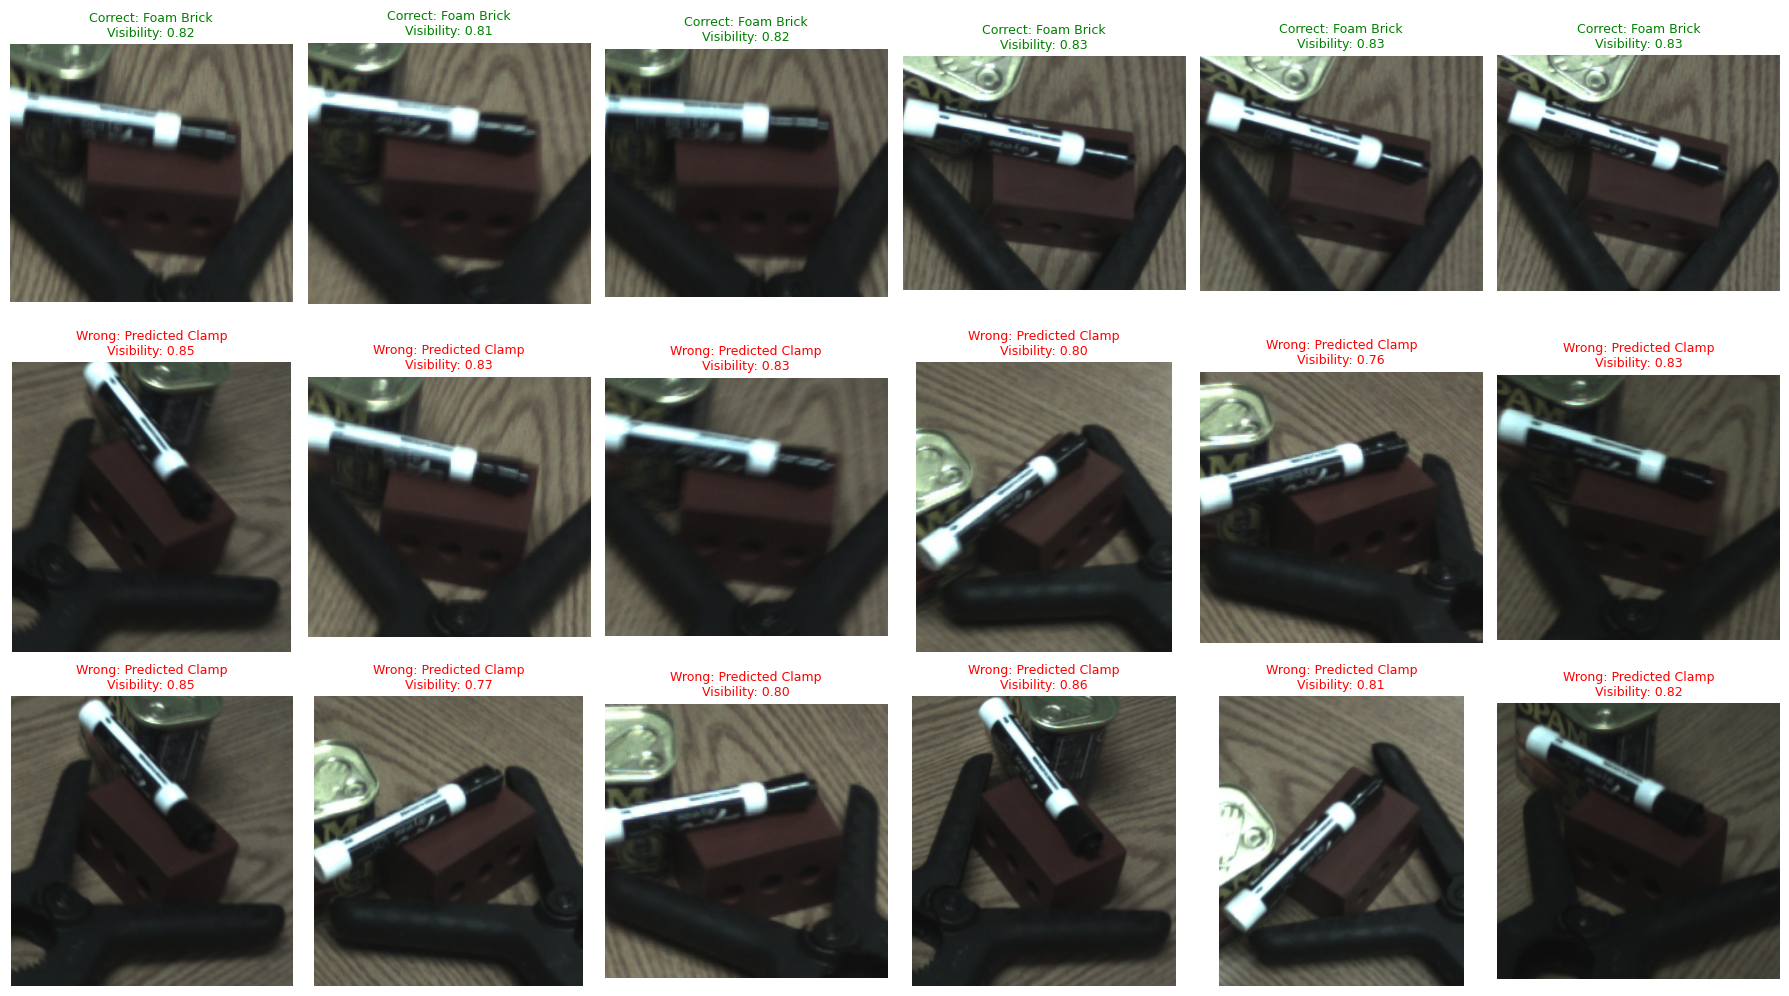

In [32]:
import matplotlib.pyplot as plt

base_path = "/content/drive/MyDrive/real_subset/binary_object_crops/"

# Load files
predictions = pd.read_csv(base_path + "loso_predictions.csv")
metadata = pd.read_csv(base_path + "binary_crop_metadata.csv")

# Standardise ID types
for df in [predictions, metadata]:
    df["scene_id"] = df["scene_id"].astype(int)
    df["image_id"] = df["image_id"].astype(int)

predictions["actual"] = predictions["actual"].astype(int)
metadata["object_id"] = metadata["object_id"].astype(int)

# Remove visibility from predictions.
# We will use the original crop metadata visibility instead.
predictions = predictions.drop(columns=["visibility"])

# Rename metadata visibility to avoid any column collision
metadata = metadata.rename(
    columns={"visibility": "crop_visibility"}
)

# Keep only the required metadata columns
metadata = metadata[
    [
        "scene_id",
        "image_id",
        "object_id",
        "object_name",
        "crop_path",
        "crop_visibility"
    ]
]

# Match predictions to their original image crops
merged = predictions.merge(
    metadata,
    left_on=["scene_id", "image_id", "actual"],
    right_on=["scene_id", "image_id", "object_id"],
    how="left",
    validate="one_to_one"
)

print("Total predictions:", len(merged))
print("Matched crops:", merged["crop_path"].notna().sum())
print("Missing crops:", merged["crop_path"].isna().sum())
print("\nMerged columns:")
print(merged.columns.tolist())

# Select Foam Brick predictions from scene 73
foam_73 = merged[
    (merged["scene_id"] == 73) &
    (merged["actual"] == 21)
].copy()

correct = foam_73[foam_73["correct"] == True]
incorrect = foam_73[foam_73["correct"] == False]

print("\nScene 000073 Foam Brick")
print("Correct:", len(correct))
print("Incorrect:", len(incorrect))

# Select six correct and twelve incorrect examples
sample_correct = correct.head(6)

sample_incorrect = incorrect.sample(
    n=min(12, len(incorrect)),
    random_state=42
)

samples = pd.concat([sample_correct, sample_incorrect])

# Display the actual crops
fig, axes = plt.subplots(3, 6, figsize=(18, 10))
axes = axes.flatten()

for ax, (_, row) in zip(axes, samples.iterrows()):

    image = Image.open(row["crop_path"]).convert("RGB")
    ax.imshow(image)

    if row["correct"]:
        title = "Correct: Foam Brick"
        color = "green"
    else:
        title = "Wrong: Predicted Clamp"
        color = "red"

    ax.set_title(
        f"{title}\nVisibility: {row['crop_visibility']:.2f}",
        color=color,
        fontsize=9
    )

    ax.axis("off")

for ax in axes[len(samples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [33]:
from pathlib import Path

# Selected RGB images
rgb_root = Path(
    "/content/drive/MyDrive/real_subset/selected_rgb/train_real"
)

# Check whether annotation_root already exists in the notebook
try:
    annotation_root = Path(annotation_root)
    print("Using existing annotation_root:", annotation_root)
except NameError:
    print("annotation_root is not defined.")
    print("Please locate the directory containing scene_gt.json files.")

print("\nRGB directory exists:", rgb_root.exists())
print("Annotation directory exists:", annotation_root.exists())

# Inspect scene 000073
scene_id = "000073"

rgb_scene = rgb_root / scene_id
annotation_scene = annotation_root / scene_id

print("\nRGB scene:", rgb_scene)
print("Annotation scene:", annotation_scene)

print("RGB images:", len(list((rgb_scene / "rgb").glob("*.png")))
      if (rgb_scene / "rgb").exists() else "Not found")

for filename in ["scene_gt.json", "scene_gt_info.json"]:
    path = annotation_scene / filename
    print(filename, "exists:", path.exists())

# Inspect one annotation entry
gt_path = annotation_scene / "scene_gt.json"

if gt_path.exists():
    with open(gt_path, "r") as f:
        gt = json.load(f)

    first_image_id = sorted(gt.keys(), key=int)[0]

    print("\nFirst image ID:", first_image_id)
    print("First annotation:", gt[first_image_id][0])

Using existing annotation_root: /content/drive/MyDrive/real_annotations/train_real

RGB directory exists: True
Annotation directory exists: True

RGB scene: /content/drive/MyDrive/real_subset/selected_rgb/train_real/000073
Annotation scene: /content/drive/MyDrive/real_annotations/train_real/000073
RGB images: 100
scene_gt.json exists: True
scene_gt_info.json exists: True

First image ID: 1
First annotation: {'cam_R_m2c': [-0.9781810776378563, 0.2039571660087705, 0.03953738738866893, 0.11060415647490392, 0.6723440290413204, -0.7319290741275214, -0.17586511946477135, -0.7115863526164047, -0.680232484964847], 'cam_t_m2c': [-90.50772104639468, -107.72138262355003, 734.0417200549748], 'obj_id': 9}


In [34]:
# Extract object-focused crops

import json
import pandas as pd
from pathlib import Path
from PIL import Image

# Directories
rgb_root = Path(
    "/content/drive/MyDrive/real_subset/selected_rgb/train_real"
)

annotation_root = Path(
    "/content/drive/MyDrive/real_annotations/train_real"
)

output_root = Path(
    "/content/drive/MyDrive/real_subset/binary_object_crops_no_margin"
)

output_root.mkdir(parents=True, exist_ok=True)

# Target objects
object_names = {
    20: "Extra Large Clamp",
    21: "Foam Brick"
}

scene_ids = [
    "000019", "000036", "000064",
    "000066", "000073", "000081"
]

metadata_records = []
missing_images = 0
missing_annotations = 0
skipped_instances = 0

for scene_id in scene_ids:

    print(f"\nProcessing scene {scene_id}...")

    rgb_dir = rgb_root / scene_id / "rgb"
    annotation_dir = annotation_root / scene_id

    with open(annotation_dir / "scene_gt.json", "r") as f:
        scene_gt = json.load(f)

    with open(annotation_dir / "scene_gt_info.json", "r") as f:
        scene_gt_info = json.load(f)

    scene_output = output_root / scene_id
    scene_output.mkdir(parents=True, exist_ok=True)

    scene_count = {20: 0, 21: 0}

    for image_id in scene_gt:

        image_path = rgb_dir / f"{int(image_id):06d}.png"

        if not image_path.exists():
            missing_images += 1
            continue

        gt_entries = scene_gt[image_id]
        info_entries = scene_gt_info[image_id]

        if len(gt_entries) != len(info_entries):
            missing_annotations += 1
            continue

        image = Image.open(image_path).convert("RGB")
        image_width, image_height = image.size

        for annotation, info in zip(gt_entries, info_entries):

            object_id = annotation["obj_id"]

            if object_id not in object_names:
                continue

            # Original projected object bounding box
            bbox = info.get("bbox_obj")

            if bbox is None:
                skipped_instances += 1
                continue

            x, y, w, h = map(float, bbox)

            # No additional margin
            x1 = max(0, int(round(x)))
            y1 = max(0, int(round(y)))
            x2 = min(image_width, int(round(x + w)))
            y2 = min(image_height, int(round(y + h)))

            if x2 <= x1 or y2 <= y1:
                skipped_instances += 1
                continue

            crop = image.crop((x1, y1, x2, y2))

            crop_filename = f"{int(image_id):06d}_{object_id}.jpg"
            crop_path = scene_output / crop_filename

            crop.save(crop_path, quality=95)

            metadata_records.append({
                "crop_path": str(crop_path),
                "scene_id": int(scene_id),
                "image_id": int(image_id),
                "object_id": object_id,
                "object_name": object_names[object_id],
                "visibility": info["visib_fract"],
                "bbox_obj": bbox,
                "crop_width": crop.width,
                "crop_height": crop.height
            })

            scene_count[object_id] += 1

        image.close()

    print(
        f"Clamp: {scene_count[20]}, "
        f"Foam Brick: {scene_count[21]}"
    )

# Save metadata
metadata_df = pd.DataFrame(metadata_records)

metadata_path = output_root / "binary_crop_metadata_no_margin.csv"
metadata_df.to_csv(metadata_path, index=False)

print("\nEXTRACTION SUMMARY")
print("Total crops:", len(metadata_df))
print("Extra Large Clamp:", (metadata_df["object_id"] == 20).sum())
print("Foam Brick:", (metadata_df["object_id"] == 21).sum())
print("Missing images:", missing_images)
print("Missing annotation entries:", missing_annotations)
print("Skipped instances:", skipped_instances)

print("\nCrops per scene:")
print(
    metadata_df.groupby(
        ["scene_id", "object_name"]
    ).size().unstack(fill_value=0)
)

print("\nSaved metadata:", metadata_path)


Processing scene 000019...
Clamp: 100, Foam Brick: 100

Processing scene 000036...
Clamp: 100, Foam Brick: 100

Processing scene 000064...
Clamp: 100, Foam Brick: 100

Processing scene 000066...
Clamp: 100, Foam Brick: 100

Processing scene 000073...
Clamp: 100, Foam Brick: 100

Processing scene 000081...
Clamp: 100, Foam Brick: 100

EXTRACTION SUMMARY
Total crops: 1200
Extra Large Clamp: 600
Foam Brick: 600
Missing images: 7297
Missing annotation entries: 0
Skipped instances: 0

Crops per scene:
object_name  Extra Large Clamp  Foam Brick
scene_id                                  
19                         100         100
36                         100         100
64                         100         100
66                         100         100
73                         100         100
81                         100         100

Saved metadata: /content/drive/MyDrive/real_subset/binary_object_crops_no_margin/binary_crop_metadata_no_margin.csv


In [35]:
import pandas as pd
from pathlib import Path

base_path = Path(
    "/content/drive/MyDrive/real_subset"
)

old_metadata = pd.read_csv(
    base_path / "binary_object_crops" /
    "binary_crop_metadata.csv"
)

new_metadata = pd.read_csv(
    base_path / "binary_object_crops_no_margin" /
    "binary_crop_metadata_no_margin.csv"
)

keys = ["scene_id", "image_id", "object_id"]

# Check observation counts
print("Original crops:", len(old_metadata))
print("New crops:", len(new_metadata))

# Check for duplicate observations
print("\nOriginal duplicate keys:",
      old_metadata.duplicated(keys).sum())

print("New duplicate keys:",
      new_metadata.duplicated(keys).sum())

# Compare observation identities
old_keys = set(map(tuple, old_metadata[keys].values))
new_keys = set(map(tuple, new_metadata[keys].values))

print("\nObservations in original only:", len(old_keys - new_keys))
print("Observations in new only:", len(new_keys - old_keys))

# Compare visibility annotations
comparison = old_metadata.merge(
    new_metadata,
    on=keys,
    suffixes=("_old", "_new"),
    validate="one_to_one"
)

print("\nMaximum visibility difference:",
      (comparison["visibility_old"] -
       comparison["visibility_new"]).abs().max())

print("\nObservation counts by scene and class:")
print(
    comparison.groupby(
        ["scene_id", "object_name_old"]
    ).size().unstack(fill_value=0)
)

Original crops: 1200
New crops: 1200

Original duplicate keys: 0
New duplicate keys: 0

Observations in original only: 0
Observations in new only: 0

Maximum visibility difference: 0.0

Observation counts by scene and class:
object_name_old  Extra_Large_Clamp  Foam_Brick
scene_id                                      
19                             100         100
36                             100         100
64                             100         100
66                             100         100
73                             100         100
81                             100         100


In [36]:
# Extract DinoV2 features from the new crops

# Paths
base_path = Path("/content/drive/MyDrive/real_subset")

metadata_path = (
    base_path / "binary_object_crops_no_margin" /
    "binary_crop_metadata_no_margin.csv"
)

feature_path = (
    base_path / "binary_object_crops_no_margin" /
    "dinov2_binary_features_no_margin.npz"
)

metadata = pd.read_csv(metadata_path)

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# Load the same DINOv2 model
model = torch.hub.load(
    "facebookresearch/dinov2",
    "dinov2_vits14"
)

model = model.to(device)
model.eval()

for parameter in model.parameters():
    parameter.requires_grad = False

# Same preprocessing as the original experiment
IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)

def preprocess_dinov2(image, image_size=518):

    image = image.convert("RGB")

    width, height = image.size

    scale = image_size / max(width, height)

    new_width = round(width * scale)
    new_height = round(height * scale)

    image = image.resize(
        (new_width, new_height),
        Image.Resampling.BICUBIC
    )

    mean_pixel = tuple(
        int(round(v * 255))
        for v in IMAGENET_MEAN
    )

    canvas = Image.new(
        "RGB",
        (image_size, image_size),
        mean_pixel
    )

    left = (image_size - new_width) // 2
    top = (image_size - new_height) // 2

    canvas.paste(image, (left, top))

    array = np.asarray(canvas).astype(np.float32) / 255.0

    array = (array - IMAGENET_MEAN) / IMAGENET_STD

    tensor = torch.from_numpy(array).permute(2, 0, 1)

    return tensor


# Extract features in batches
batch_size = 8
all_features = []

for start in tqdm(
    range(0, len(metadata), batch_size),
    desc="Extracting DINOv2 features"
):

    batch_metadata = metadata.iloc[
        start:start + batch_size
    ]

    batch_images = []

    for image_path in batch_metadata["crop_path"]:

        image = Image.open(image_path).convert("RGB")

        tensor = preprocess_dinov2(image)

        batch_images.append(tensor)

        image.close()

    batch_tensor = torch.stack(batch_images).to(device)

    with torch.no_grad():

        outputs = model.forward_features(batch_tensor)

        features = outputs["x_norm_clstoken"]

    all_features.append(
        features.cpu().numpy()
    )

# Combine features
X = np.concatenate(all_features, axis=0)

# Labels and metadata
y = metadata["object_id"].to_numpy()

visibility = metadata["visibility"].to_numpy()

scene_ids = metadata["scene_id"].astype(str).to_numpy()

image_ids = metadata["image_id"].to_numpy()

# Verify feature dimensions
print("\nFeature shape:", X.shape)
print("Label shape:", y.shape)

print("NaN values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())

print("\nClass distribution:")
print(pd.Series(y).value_counts().sort_index())

print("\nScene distribution:")
print(pd.Series(scene_ids).value_counts().sort_index())

# Save features
np.savez_compressed(
    feature_path,
    X=X,
    y=y,
    visibility=visibility,
    scene_ids=scene_ids,
    image_ids=image_ids
)

print("\nFeatures saved to:")
print(feature_path)

Device: cuda


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Extracting DINOv2 features:   0%|          | 0/150 [00:00<?, ?it/s]


Feature shape: (1200, 384)
Label shape: (1200,)
NaN values: 0
Infinite values: 0

Class distribution:
20    600
21    600
Name: count, dtype: int64

Scene distribution:
19    200
36    200
64    200
66    200
73    200
81    200
Name: count, dtype: int64

Features saved to:
/content/drive/MyDrive/real_subset/binary_object_crops_no_margin/dinov2_binary_features_no_margin.npz


In [37]:
# Run leave-one-scene-out evaluation

# Load new features
feature_path = (
    "/content/drive/MyDrive/real_subset/"
    "binary_object_crops_no_margin/"
    "dinov2_binary_features_no_margin.npz"
)

data = np.load(feature_path, allow_pickle=True)

X = data["X"]
y = data["y"]
scene_ids = data["scene_ids"].astype(str)

# Same classifier as the baseline
classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=0.001,
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    )
)

# Leave-One-Scene-Out evaluation
logo = LeaveOneGroupOut()

oof_predictions = np.zeros_like(y)

scene_results = []

for train_idx, test_idx in logo.split(
    X, y, groups=scene_ids
):

    held_out_scene = scene_ids[test_idx][0]

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    classifier.fit(X_train, y_train)

    predictions = classifier.predict(X_test)

    oof_predictions[test_idx] = predictions

    scene_results.append({
        "scene_id": held_out_scene,
        "samples": len(test_idx),
        "accuracy": accuracy_score(y_test, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "macro_f1": f1_score(
            y_test, predictions, average="macro"
        )
    })

# Per-scene results
results_df = pd.DataFrame(scene_results)

print("PER-SCENE RESULTS")
display(results_df.round(4))

# Overall metrics
print("\nOVERALL RESULTS")

print(
    "Mean scene accuracy:",
    round(results_df["accuracy"].mean(), 4)
)

print(
    "Mean scene balanced accuracy:",
    round(results_df["balanced_accuracy"].mean(), 4)
)

print(
    "Mean scene macro F1:",
    round(results_df["macro_f1"].mean(), 4)
)

print(
    "\nPooled accuracy:",
    round(accuracy_score(y, oof_predictions), 4)
)

print(
    "Pooled balanced accuracy:",
    round(balanced_accuracy_score(y, oof_predictions), 4)
)

print(
    "Pooled macro F1:",
    round(f1_score(y, oof_predictions, average="macro"), 4)
)

# Confusion matrix
print("\nCONFUSION MATRIX")

cm = confusion_matrix(
    y,
    oof_predictions,
    labels=[20, 21]
)

print(pd.DataFrame(
    cm,
    index=["Actual Clamp", "Actual Foam Brick"],
    columns=["Predicted Clamp", "Predicted Foam Brick"]
))

# Classification report
print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[20, 21],
        target_names=[
            "Extra Large Clamp",
            "Foam Brick"
        ],
        digits=4
    )
)

# Scene 73 class-specific performance
print("\nSCENE 000073")

scene_73_mask = scene_ids == "73"

for object_id, object_name in [
    (20, "Extra Large Clamp"),
    (21, "Foam Brick")
]:

    mask = scene_73_mask & (y == object_id)

    print(
        f"{object_name}:",
        accuracy_score(
            y[mask],
            oof_predictions[mask]
        )
    )

# Save predictions
prediction_df = pd.DataFrame({
    "scene_id": scene_ids,
    "actual": y,
    "predicted": oof_predictions,
    "correct": y == oof_predictions
})

prediction_df.to_csv(
    "/content/drive/MyDrive/real_subset/"
    "binary_object_crops_no_margin/"
    "loso_predictions_no_margin.csv",
    index=False
)

print("\nPredictions saved successfully.")

PER-SCENE RESULTS


,scene_id,samples,accuracy,balanced_accuracy,macro_f1
0,19,200,1.00,1.00,1.000
1,36,200,1.00,1.00,1.000
2,64,200,0.98,0.98,0.980
3,66,200,1.00,1.00,1.000
4,73,200,0.69,0.69,0.657
5,81,200,1.00,1.00,1.000



OVERALL RESULTS
Mean scene accuracy: 0.945
Mean scene balanced accuracy: 0.945
Mean scene macro F1: 0.9395

Pooled accuracy: 0.945
Pooled balanced accuracy: 0.945
Pooled macro F1: 0.9449

CONFUSION MATRIX
                   Predicted Clamp  Predicted Foam Brick
Actual Clamp                   596                     4
Actual Foam Brick               62                   538

CLASSIFICATION REPORT
                   precision    recall  f1-score   support

Extra Large Clamp     0.9058    0.9933    0.9475       600
       Foam Brick     0.9926    0.8967    0.9422       600

         accuracy                         0.9450      1200
        macro avg     0.9492    0.9450    0.9449      1200
     weighted avg     0.9492    0.9450    0.9449      1200


SCENE 000073
Extra Large Clamp: 1.0
Foam Brick: 0.38

Predictions saved successfully.


In [38]:
# Inspect 62 misclassified foam bricks

base_path = "/content/drive/MyDrive/real_subset/binary_object_crops_no_margin/"

# Load predictions, crop metadata, and extracted features
predictions = pd.read_csv(
    base_path + "loso_predictions_no_margin.csv"
)

metadata = pd.read_csv(
    base_path + "binary_crop_metadata_no_margin.csv"
)

features = np.load(
    base_path + "dinov2_binary_features_no_margin.npz",
    allow_pickle=True
)

# Recover image IDs from the feature file
image_ids = features["image_ids"]
feature_labels = features["y"]
feature_scenes = features["scene_ids"]

# Validate alignment before joining
assert len(predictions) == len(metadata) == len(image_ids)
assert np.array_equal(
    predictions["actual"].to_numpy(),
    feature_labels
)

assert np.array_equal(
    predictions["scene_id"].astype(int).to_numpy(),
    feature_scenes.astype(int)
)

# Add image IDs to predictions using their original feature order
predictions["image_id"] = image_ids

# Normalize scene IDs for a reliable merge
predictions["scene_id"] = predictions["scene_id"].astype(int)
metadata["scene_id"] = metadata["scene_id"].astype(int)

# Merge predictions with crop metadata
data = predictions.merge(
    metadata,
    left_on=["scene_id", "image_id", "actual"],
    right_on=["scene_id", "image_id", "object_id"],
    how="inner",
    validate="one_to_one"
)

print("Merged observations:", len(data))

# Inspect Foam Brick predictions in scene 000073
foam_scene = data[
    (data["scene_id"] == 73) &
    (data["actual"] == 21)
].copy()

print("\nFoam Brick predictions in scene 000073")
print(foam_scene["correct"].value_counts())

print("\nCorrectly classified examples:")
print(
    foam_scene[foam_scene["correct"]][
        ["image_id", "visibility", "crop_path"]
    ].head(10).to_string(index=False)
)

print("\nIncorrectly classified examples:")
print(
    foam_scene[~foam_scene["correct"]][
        ["image_id", "visibility", "crop_path"]
    ].head(10).to_string(index=False)
)

Merged observations: 1200

Foam Brick predictions in scene 000073
correct
False    62
True     38
Name: count, dtype: int64

Correctly classified examples:
 image_id  visibility                                                                             crop_path
       73    0.802043 /content/drive/MyDrive/real_subset/binary_object_crops_no_margin/000073/000073_21.jpg
       80    0.806949 /content/drive/MyDrive/real_subset/binary_object_crops_no_margin/000073/000080_21.jpg
      116    0.853308 /content/drive/MyDrive/real_subset/binary_object_crops_no_margin/000073/000116_21.jpg
      124    0.867998 /content/drive/MyDrive/real_subset/binary_object_crops_no_margin/000073/000124_21.jpg
      138    0.819369 /content/drive/MyDrive/real_subset/binary_object_crops_no_margin/000073/000138_21.jpg
      145    0.829893 /content/drive/MyDrive/real_subset/binary_object_crops_no_margin/000073/000145_21.jpg
      160    0.844890 /content/drive/MyDrive/real_subset/binary_object_crops_no_margin/0

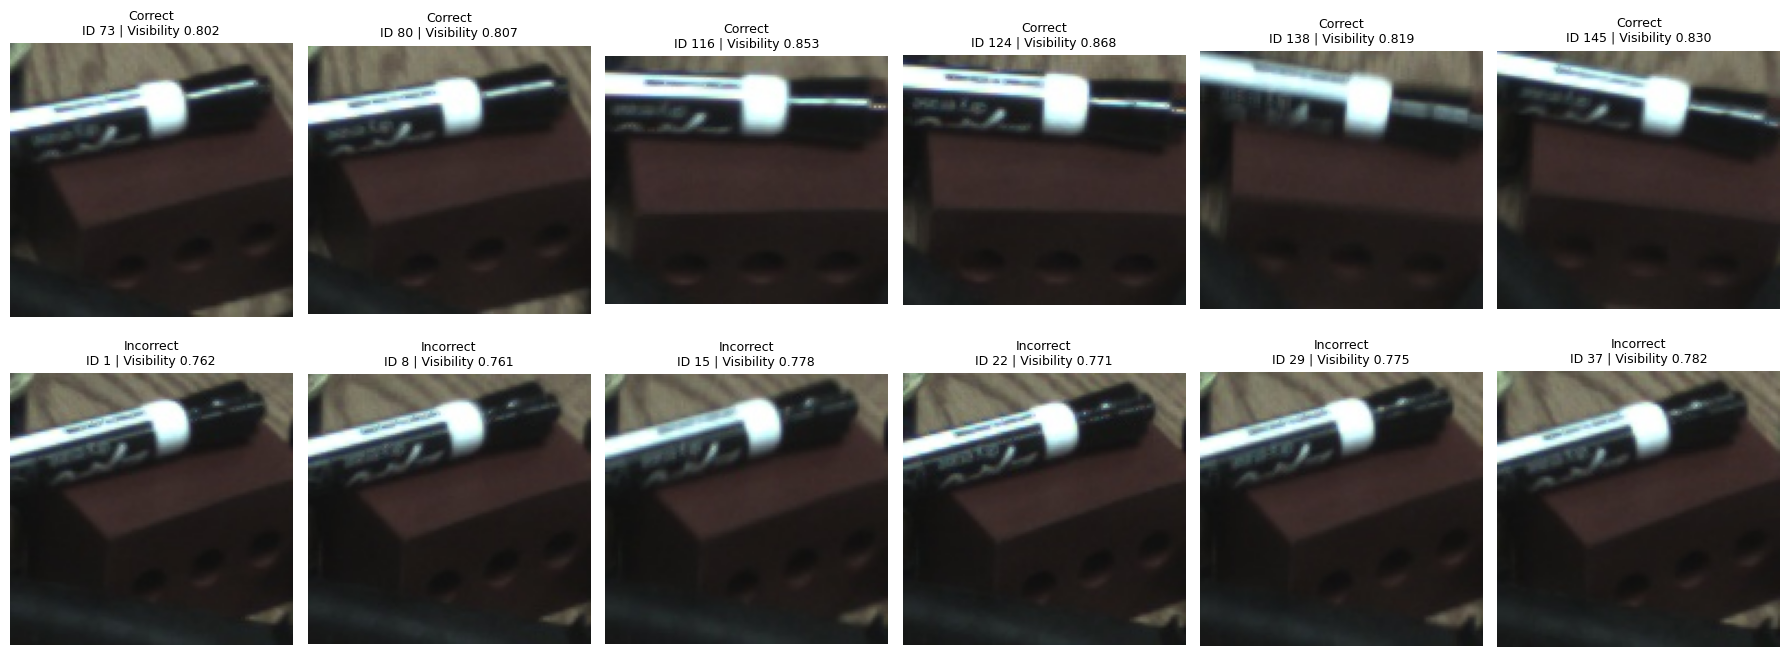

In [39]:
# Compare the crops

base_path = "/content/drive/MyDrive/real_subset/binary_object_crops_no_margin/"

predictions = pd.read_csv(
    base_path + "loso_predictions_no_margin.csv"
)
metadata = pd.read_csv(
    base_path + "binary_crop_metadata_no_margin.csv"
)
features = np.load(
    base_path + "dinov2_binary_features_no_margin.npz",
    allow_pickle=True
)

# Restore image IDs and verify row alignment
predictions["image_id"] = features["image_ids"]

assert len(predictions) == len(metadata) == len(features["y"])
assert np.array_equal(predictions["actual"], features["y"])

# Match predictions to crop files
data = predictions.merge(
    metadata,
    left_on=["scene_id", "image_id", "actual"],
    right_on=["scene_id", "image_id", "object_id"],
    validate="one_to_one"
)

foam_scene = data[
    (data["scene_id"].astype(int) == 73) &
    (data["actual"] == 21)
]

correct = foam_scene[foam_scene["correct"]].sort_values("image_id").head(6)
incorrect = foam_scene[~foam_scene["correct"]].sort_values("image_id").head(6)

fig, axes = plt.subplots(2, 6, figsize=(18, 7))

for row, subset, label in [
    (0, correct, "Correct"),
    (1, incorrect, "Incorrect")
]:
    for ax, (_, item) in zip(axes[row], subset.iterrows()):
        img = Image.open(item["crop_path"]).convert("RGB")
        ax.imshow(img)
        ax.set_title(
            f"{label}\nID {int(item['image_id'])} | "
            f"Visibility {item['visibility']:.3f}",
            fontsize=9
        )
        ax.axis("off")

plt.tight_layout()
plt.show()

In [40]:
# Quantify the pattern

# Focus on Foam Brick in scene 000073
foam_scene = data[
    (data["scene_id"] == 73) &
    (data["actual"] == 21)
].copy()

# Extract crop dimensions
def get_crop_dimensions(path):
    with Image.open(path) as img:
        return img.width, img.height

dimensions = foam_scene["crop_path"].apply(get_crop_dimensions)

foam_scene["crop_width"] = dimensions.apply(lambda x: x[0])
foam_scene["crop_height"] = dimensions.apply(lambda x: x[1])

# Summary statistics
summary = foam_scene.groupby("correct").agg(
    count=("image_id", "count"),
    mean_visibility=("visibility", "mean"),
    std_visibility=("visibility", "std"),
    min_visibility=("visibility", "min"),
    max_visibility=("visibility", "max"),
    mean_image_id=("image_id", "mean"),
    mean_crop_width=("crop_width", "mean"),
    mean_crop_height=("crop_height", "mean")
)

summary.index = ["Incorrect", "Correct"]

print("COMPARISON OF CORRECT AND INCORRECT PREDICTIONS")
display(summary.round(3))

# Examine predictions over image ID intervals
foam_scene["image_interval"] = pd.cut(
    foam_scene["image_id"],
    bins=[0, 25, 50, 75, 100, 125, 150, 175, 200, 225, 250, 275, 300, 325, 350, 375, 400, 1000],
    include_lowest=True
)

interval_summary = foam_scene.groupby(
    "image_interval",
    observed=True
).agg(
    observations=("correct", "count"),
    correct=("correct", "sum"),
    accuracy=("correct", "mean"),
    mean_visibility=("visibility", "mean")
)

print("\nPREDICTION ACCURACY OVER IMAGE ID INTERVALS")
display(interval_summary.round(3))

COMPARISON OF CORRECT AND INCORRECT PREDICTIONS


,count,mean_visibility,std_visibility,min_visibility,max_visibility,mean_image_id,mean_crop_width,mean_crop_height
Incorrect,62,0.807,0.024,0.751,0.855,398.387,139.419,141.194
Correct,38,0.826,0.023,0.765,0.868,294.789,136.553,131.684



PREDICTION ACCURACY OVER IMAGE ID INTERVALS


,observations,correct,accuracy,mean_visibility
image_interval,,,,
"(-0.001, 25.0]",4,0,0.000,0.768
"(25.0, 50.0]",3,0,0.000,0.782
"(50.0, 75.0]",4,1,0.250,0.796
"(75.0, 100.0]",3,1,0.333,0.808
"(100.0, 125.0]",4,2,0.500,0.838
"(125.0, 150.0]",3,2,0.667,0.828
"(150.0, 175.0]",4,3,0.750,0.833
"(175.0, 200.0]",3,3,1.000,0.834
"(200.0, 225.0]",4,1,0.250,0.830


Camera frames available: 718

Matched observations: 100

CAMERA MOVEMENT BY PREDICTION OUTCOME


,observations,mean_displacement_mm,std_displacement_mm,mean_rotation_deg,std_rotation_deg,mean_visibility
Incorrect,62,287.10,170.09,30.25,23.71,0.81
Correct,38,394.14,179.66,46.35,24.79,0.83



OBSERVATIONS WITH LARGEST CAMERA DISPLACEMENT


,image_id,correct,visibility,displacement_mm,rotation_change_deg
47,341,True,0.84,653.31,84.79
48,348,True,0.85,649.10,79.69
45,326,True,0.84,646.22,93.29
44,319,False,0.85,644.98,94.62
43,312,False,0.84,642.32,92.26
46,334,True,0.86,641.81,88.85
42,305,True,0.85,630.49,90.11
41,297,False,0.85,629.06,87.05
49,355,True,0.83,623.93,70.17
40,290,False,0.85,619.95,84.14


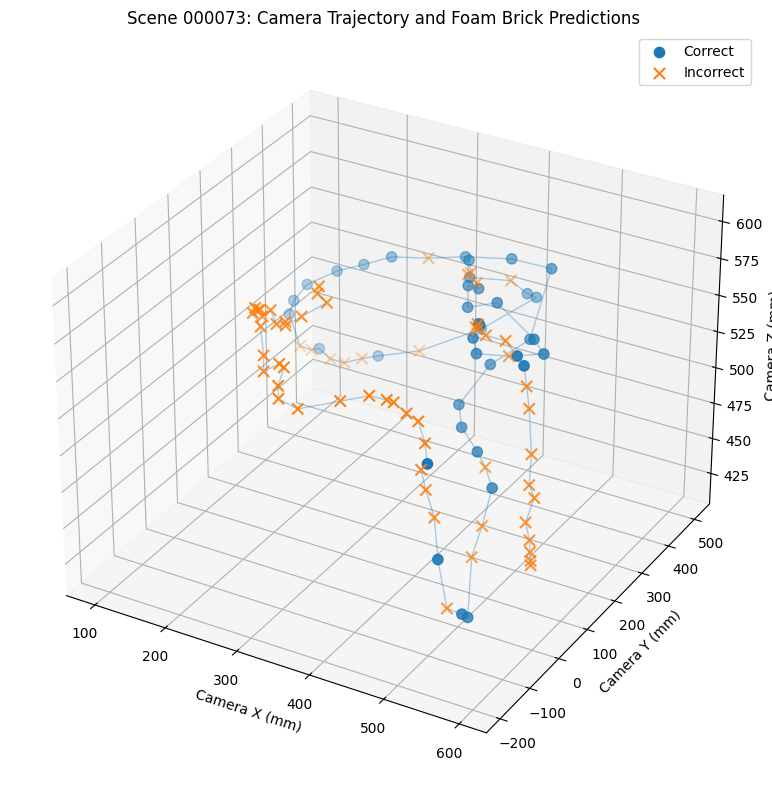

In [41]:
# Examine camera poses

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load camera annotations

scene_camera_path = os.path.join(
    annotation_root,
    "000073",
    "scene_camera.json"
)

with open(scene_camera_path, "r") as f:
    camera_data = json.load(f)

print("Camera frames available:", len(camera_data))

# Extract camera positions and orientations

camera_records = []

for image_id, camera_info in camera_data.items():

    R_w2c = np.array(
        camera_info["cam_R_w2c"]
    ).reshape(3, 3)

    t_w2c = np.array(
        camera_info["cam_t_w2c"]
    ).reshape(3)

    # Camera position in world coordinates
    camera_position = -R_w2c.T @ t_w2c

    # Camera orientation in world coordinates
    R_c2w = R_w2c.T

    camera_records.append({
        "image_id": int(image_id),
        "camera_x": camera_position[0],
        "camera_y": camera_position[1],
        "camera_z": camera_position[2],
        "R_c2w": R_c2w
    })

camera_df = pd.DataFrame(camera_records)

camera_df = camera_df.sort_values(
    "image_id"
).reset_index(drop=True)

# Use the first available camera pose as reference
reference_position = camera_df.loc[
    0, ["camera_x", "camera_y", "camera_z"]
].to_numpy(dtype=float)

reference_rotation = camera_df.loc[0, "R_c2w"]

# Calculate displacement and orientation change

displacements = []
rotation_changes = []

for _, row in camera_df.iterrows():

    position = row[
        ["camera_x", "camera_y", "camera_z"]
    ].to_numpy(dtype=float)

    rotation = row["R_c2w"]

    displacement = np.linalg.norm(
        position - reference_position
    )

    relative_rotation = (
        reference_rotation.T @ rotation
    )

    cos_angle = (
        np.trace(relative_rotation) - 1
    ) / 2

    cos_angle = np.clip(cos_angle, -1.0, 1.0)

    angle = np.degrees(
        np.arccos(cos_angle)
    )

    displacements.append(displacement)
    rotation_changes.append(angle)

camera_df["displacement_mm"] = displacements
camera_df["rotation_change_deg"] = rotation_changes

# Match camera poses with predictions

analysis_df = foam_scene.merge(
    camera_df,
    on="image_id",
    how="left",
    validate="one_to_one"
)

assert analysis_df["displacement_mm"].notna().all()

print("\nMatched observations:", len(analysis_df))

# Compare camera movement by prediction outcome

pose_summary = analysis_df.groupby("correct").agg(
    observations=("image_id", "count"),
    mean_displacement_mm=("displacement_mm", "mean"),
    std_displacement_mm=("displacement_mm", "std"),
    mean_rotation_deg=("rotation_change_deg", "mean"),
    std_rotation_deg=("rotation_change_deg", "std"),
    mean_visibility=("visibility", "mean")
)

pose_summary.index = ["Incorrect", "Correct"]

print("\nCAMERA MOVEMENT BY PREDICTION OUTCOME")
display(pose_summary.round(2))

# Show individual observations

print("\nOBSERVATIONS WITH LARGEST CAMERA DISPLACEMENT")

display(
    analysis_df.sort_values(
        "displacement_mm",
        ascending=False
    )[
        [
            "image_id",
            "correct",
            "visibility",
            "displacement_mm",
            "rotation_change_deg"
        ]
    ].head(15).round(2)
)

# Visualise camera trajectory in 3D

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

correct = analysis_df[analysis_df["correct"]]
incorrect = analysis_df[~analysis_df["correct"]]

# Show the trajectory
trajectory = analysis_df.sort_values("image_id")

ax.plot(
    trajectory["camera_x"],
    trajectory["camera_y"],
    trajectory["camera_z"],
    alpha=0.35,
    linewidth=1
)

ax.scatter(
    correct["camera_x"],
    correct["camera_y"],
    correct["camera_z"],
    label="Correct",
    marker="o",
    s=55
)

ax.scatter(
    incorrect["camera_x"],
    incorrect["camera_y"],
    incorrect["camera_z"],
    label="Incorrect",
    marker="x",
    s=65
)

ax.set_xlabel("Camera X (mm)")
ax.set_ylabel("Camera Y (mm)")
ax.set_zlabel("Camera Z (mm)")

ax.set_title(
    "Scene 000073: Camera Trajectory and Foam Brick Predictions"
)

ax.legend()
plt.tight_layout()
plt.show()

SPEARMAN CORRELATIONS WITH CLASSIFICATION CORRECTNESS
displacement_mm           rho =  0.273, p-value = 0.0059
rotation_change_deg       rho =  0.348, p-value = 0.0004
visibility                rho =  0.383, p-value = 0.0001
image_id                  rho = -0.241, p-value = 0.0159

ACCURACY BY CAMERA DISPLACEMENT


,observations,correct,accuracy,mean_rotation,mean_visibility
displacement_group,,,,,
"(-0.001, 184.907]",25,7,0.28,7.212,0.784
"(184.907, 325.866]",25,9,0.36,30.165,0.819
"(325.866, 454.731]",25,6,0.24,36.484,0.816
"(454.731, 653.309]",25,16,0.64,71.600,0.839



ACCURACY BY CAMERA ORIENTATION CHANGE


,observations,correct,accuracy,mean_displacement,mean_visibility
rotation_group,,,,,
"(0.057, 16.717]",25,7,0.28,104.219,0.783
"(16.717, 32.251]",25,3,0.12,287.891,0.811
"(32.251, 51.724]",25,12,0.48,338.977,0.825
"(51.724, 94.625]",25,16,0.64,580.018,0.839


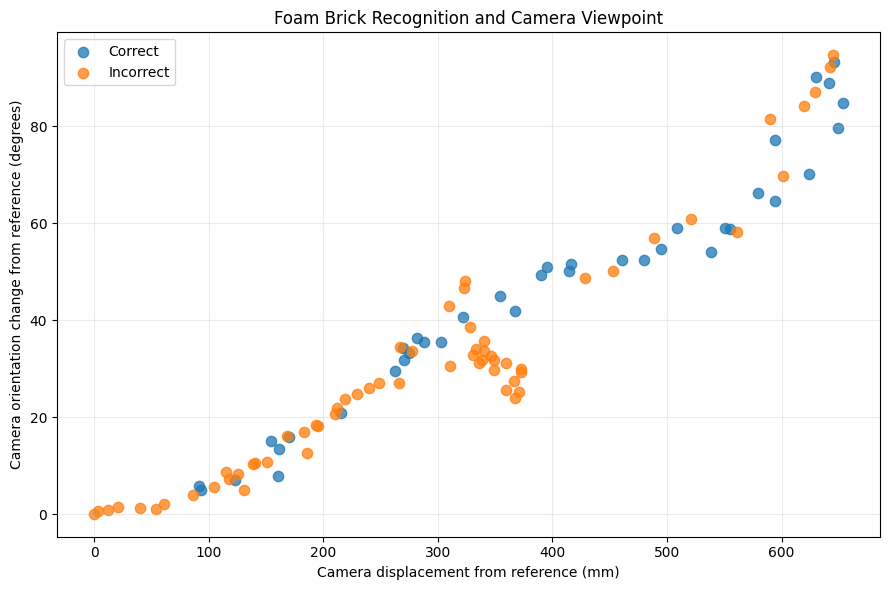

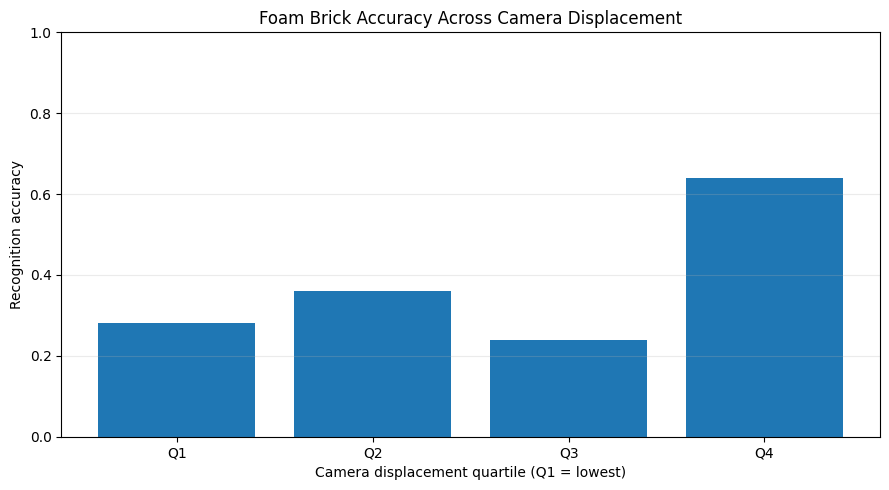

In [42]:
from scipy.stats import spearmanr

# Work on a copy
df = analysis_df.copy()

# Convert correctness to numeric
df["correct_numeric"] = df["correct"].astype(int)

# Correlations

variables = [
    "displacement_mm",
    "rotation_change_deg",
    "visibility",
    "image_id"
]

print("SPEARMAN CORRELATIONS WITH CLASSIFICATION CORRECTNESS")

for variable in variables:
    rho, p_value = spearmanr(
        df[variable],
        df["correct_numeric"]
    )

    print(
        f"{variable:25s} "
        f"rho = {rho: .3f}, "
        f"p-value = {p_value:.4f}"
    )

# Accuracy by camera displacement

df["displacement_group"] = pd.qcut(
    df["displacement_mm"],
    q=4,
    duplicates="drop"
)

displacement_summary = df.groupby(
    "displacement_group",
    observed=True
).agg(
    observations=("correct", "count"),
    correct=("correct", "sum"),
    accuracy=("correct_numeric", "mean"),
    mean_rotation=("rotation_change_deg", "mean"),
    mean_visibility=("visibility", "mean")
)

print("\nACCURACY BY CAMERA DISPLACEMENT")
display(displacement_summary.round(3))

# Accuracy by camera orientation change

df["rotation_group"] = pd.qcut(
    df["rotation_change_deg"],
    q=4,
    duplicates="drop"
)

rotation_summary = df.groupby(
    "rotation_group",
    observed=True
).agg(
    observations=("correct", "count"),
    correct=("correct", "sum"),
    accuracy=("correct_numeric", "mean"),
    mean_displacement=("displacement_mm", "mean"),
    mean_visibility=("visibility", "mean")
)

print("\nACCURACY BY CAMERA ORIENTATION CHANGE")
display(rotation_summary.round(3))

# Plot displacement against orientation change

plt.figure(figsize=(9, 6))

for outcome, label in [
    (True, "Correct"),
    (False, "Incorrect")
]:
    subset = df[df["correct"] == outcome]

    plt.scatter(
        subset["displacement_mm"],
        subset["rotation_change_deg"],
        label=label,
        alpha=0.75,
        s=55
    )

plt.xlabel("Camera displacement from reference (mm)")
plt.ylabel("Camera orientation change from reference (degrees)")
plt.title("Foam Brick Recognition and Camera Viewpoint")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Plot accuracy across displacement groups

plt.figure(figsize=(9, 5))

plt.bar(
    range(len(displacement_summary)),
    displacement_summary["accuracy"]
)

plt.xticks(
    range(len(displacement_summary)),
    [
        f"Q{i+1}"
        for i in range(len(displacement_summary))
    ]
)

plt.xlabel("Camera displacement quartile (Q1 = lowest)")
plt.ylabel("Recognition accuracy")
plt.ylim(0, 1)
plt.title("Foam Brick Accuracy Across Camera Displacement")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

In [43]:
# Separate viewpoint from visibility

from sklearn.metrics import accuracy_score, roc_auc_score

df = analysis_df.copy()

# Predictors
predictors = [
    "displacement_mm",
    "rotation_change_deg",
    "visibility",
    "image_id"
]

X = df[predictors]
y = df["correct"].astype(int)

# Examine correlations among predictors
print("CORRELATIONS BETWEEN PREDICTORS")
display(X.corr().round(3))

# Fit multivariable logistic regression
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=1.0,
        max_iter=3000,
        random_state=42
    )
)

model.fit(X, y)

# Extract standardized coefficients
coefficients = pd.DataFrame({
    "predictor": predictors,
    "standardized_coefficient": (
        model.named_steps["logisticregression"].coef_[0]
    )
})

coefficients["absolute_coefficient"] = (
    coefficients["standardized_coefficient"].abs()
)

coefficients = coefficients.sort_values(
    "absolute_coefficient",
    ascending=False
)

print("\nMULTIVARIABLE LOGISTIC REGRESSION")
display(coefficients.round(3))

# In-sample diagnostic only, not generalisation performance
probabilities = model.predict_proba(X)[:, 1]
predictions = model.predict(X)

print("\nIN-SAMPLE DIAGNOSTICS")
print("Accuracy:", round(accuracy_score(y, predictions), 3))
print("ROC-AUC:", round(roc_auc_score(y, probabilities), 3))

CORRELATIONS BETWEEN PREDICTORS


,displacement_mm,rotation_change_deg,visibility,image_id
displacement_mm,1.000,0.964,0.783,0.121
rotation_change_deg,0.964,1.000,0.810,0.014
visibility,0.783,0.810,1.000,-0.082
image_id,0.121,0.014,-0.082,1.000



MULTIVARIABLE LOGISTIC REGRESSION


,predictor,standardized_coefficient,absolute_coefficient
2,visibility,0.583,0.583
3,image_id,-0.522,0.522
0,displacement_mm,0.268,0.268
1,rotation_change_deg,-0.018,0.018



IN-SAMPLE DIAGNOSTICS
Accuracy: 0.71
ROC-AUC: 0.749


In [44]:
# Train and freeze final classifier

import joblib

# Load the real-image training features

feature_path = (
    "/content/drive/MyDrive/real_subset/"
    "binary_object_crops_no_margin/"
    "dinov2_binary_features_no_margin.npz"
)

features = np.load(feature_path, allow_pickle=True)

X_train = features["X"]
y_train = features["y"].astype(int)
scene_ids = features["scene_ids"]

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Classes:", np.unique(y_train, return_counts=True))
print("Training scenes:", np.unique(scene_ids))

# Train final classifier

final_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=0.001,
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    )
)

final_model.fit(X_train, y_train)

# Save frozen model

model_path = (
    "/content/drive/MyDrive/real_subset/"
    "binary_object_crops_no_margin/"
    "final_binary_classifier.joblib"
)

joblib.dump(final_model, model_path)

print("\nFinal classifier trained and saved.")
print("Model path:", model_path)

# Training performance is descriptive only.
train_predictions = final_model.predict(X_train)

print("\nTRAINING PERFORMANCE (NOT TEST PERFORMANCE)")
print(
    classification_report(
        y_train,
        train_predictions,
        target_names=["Extra Large Clamp", "Foam Brick"]
    )
)

Training features: (1200, 384)
Training labels: (1200,)
Classes: (array([20, 21]), array([600, 600]))
Training scenes: ['19' '36' '64' '66' '73' '81']

Final classifier trained and saved.
Model path: /content/drive/MyDrive/real_subset/binary_object_crops_no_margin/final_binary_classifier.joblib

TRAINING PERFORMANCE (NOT TEST PERFORMANCE)
                   precision    recall  f1-score   support

Extra Large Clamp       1.00      0.99      1.00       600
       Foam Brick       1.00      1.00      1.00       600

         accuracy                           1.00      1200
        macro avg       1.00      1.00      1.00      1200
     weighted avg       1.00      1.00      1.00      1200



In [45]:
import os

drive_root = "/content/drive/MyDrive"

matches = []

for root, dirs, files in os.walk(drive_root):
    # Avoid searching common large or irrelevant folders
    dirs[:] = [
        d for d in dirs
        if d not in {"node_modules", ".git", "__pycache__"}
    ]

    if (
        os.path.basename(root) == "000057"
        and "scene_gt.json" in files
        and "scene_camera.json" in files
    ):
        rgb_path = os.path.join(root, "rgb")

        matches.append({
            "scene_folder": root,
            "annotations": os.path.join(root, "scene_gt.json"),
            "camera": os.path.join(root, "scene_camera.json"),
            "rgb_folder": rgb_path,
            "rgb_exists": os.path.isdir(rgb_path),
            "rgb_count": len(os.listdir(rgb_path))
                if os.path.isdir(rgb_path) else 0
        })

print("Matching scene folders:", len(matches))

for item in matches:
    for key, value in item.items():
        print(f"{key}: {value}")
    print()

Matching scene folders: 0


In [46]:
# Download the YCB-V Dataset

import os

os.makedirs("/content/ycbv", exist_ok=True)

%cd /content/ycbv

# Dataset metadata
!wget -c https://huggingface.co/datasets/bop-benchmark/ycbv/resolve/main/ycbv_base.zip

# Selected test images
!wget -c https://huggingface.co/datasets/bop-benchmark/ycbv/resolve/main/ycbv_test_bop19.zip

/content/ycbv
--2026-11-18 11:59:16--  https://huggingface.co/datasets/bop-benchmark/ycbv/resolve/main/ycbv_base.zip
Resolving huggingface.co (huggingface.co)... 18.164.174.17, 18.164.174.118, 18.164.174.23, ...
Connecting to huggingface.co (huggingface.co)|18.164.174.17|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/679cbae3b7477d5bd98d2c7b/7da0c2d50e020426eb793d83272d210153cc1c1e8af99bd538ed794e721c4e53?xip=ARoz6j9tBDs&user_id=public&response-content-type=application%2Fzip&X-Xet-Cas-Uid=public&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27ycbv_base.zip%3B+filename%3D%22ycbv_base.zip%22%3B&Expires=1795006756&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjc5Y2JhZTNiNzQ3N2Q1YmQ5OGQyYzdiLzdkYTBjMmQ1MGUwMjA0MjZlYjc5M2Q4MzI3MmQyMTAxNTNjYzFjMWU4YWY5OWJkNTM4ZWQ3OTRlNzIxYzRlNTNcXD94aXA9QVJvejZqOXRCRHMmdXNlcl9pZD1wdWJsaWMmcmVzcG9uc2UtY29udGVudC10eXBlPSomWC1YZ

In [47]:
# Unzip files

!unzip -q ycbv_base.zip -d base
!unzip -q ycbv_test_bop19.zip -d test

In [48]:
import zipfile
import os

archive_path = "/content/ycbv/ycbv_test_bop19.zip"

print("Archive exists:", os.path.exists(archive_path))

if os.path.exists(archive_path):
    with zipfile.ZipFile(archive_path, "r") as z:
        names = z.namelist()

        print("Total files:", len(names))

        scene_files = [
            name for name in names
            if "000057" in name
        ]

        print("\nFiles containing scene 000057:")
        for name in scene_files[:30]:
            print(name)

        print("\nRelevant archive entries:")
        for name in names:
            if any(x in name for x in [
                "scene_gt.json",
                "scene_gt_info.json",
                "scene_camera.json"
            ]):
                print(name)

Archive exists: True
Total files: 10087

Files containing scene 000057:
test/000052/rgb/000057.png
test/000052/depth/000057.png
test/000052/mask/000057_000000.png
test/000052/mask_visib/000057_000000.png
test/000052/mask/000057_000001.png
test/000052/mask_visib/000057_000001.png
test/000052/mask/000057_000002.png
test/000052/mask_visib/000057_000002.png
test/000057/scene_camera.json
test/000057/scene_gt.json
test/000057/scene_gt_info.json
test/000057/rgb/000001.png
test/000057/depth/000001.png
test/000057/mask/000001_000000.png
test/000057/mask_visib/000001_000000.png
test/000057/mask/000001_000001.png
test/000057/mask_visib/000001_000001.png
test/000057/mask/000001_000002.png
test/000057/mask_visib/000001_000002.png
test/000057/mask/000001_000003.png
test/000057/mask_visib/000001_000003.png
test/000057/mask/000001_000004.png
test/000057/mask_visib/000001_000004.png
test/000057/rgb/001026.png
test/000057/depth/001026.png
test/000057/mask/001026_000000.png
test/000057/mask_visib/001026_

In [49]:
# Extract scene 000057

import zipfile
import os

archive_path = "/content/ycbv/ycbv_test_bop19.zip"
output_dir = "/content/ycbv"

with zipfile.ZipFile(archive_path, "r") as z:
    selected_files = [
        name for name in z.namelist()
        if name.startswith("test/000057/")
    ]

    print("Files to extract:", len(selected_files))

    for name in selected_files:
        z.extract(name, output_dir)

scene_dir = "/content/ycbv/test/000057"
rgb_dir = os.path.join(scene_dir, "rgb")

print("\nScene directory exists:", os.path.isdir(scene_dir))
print("RGB directory exists:", os.path.isdir(rgb_dir))
print("RGB images:", len(os.listdir(rgb_dir)))
print("Annotations:", [
    f for f in os.listdir(scene_dir)
    if f.endswith(".json")
])

Files to extract: 903

Scene directory exists: True
RGB directory exists: True
RGB images: 75
Annotations: ['scene_camera.json', 'scene_gt.json', 'scene_gt_info.json']


In [50]:
# Inspect the two target objects

import json
import pandas as pd
import os

scene_dir = "/content/ycbv/test/000057"

with open(os.path.join(scene_dir, "scene_gt.json")) as f:
    scene_gt = json.load(f)

with open(os.path.join(scene_dir, "scene_gt_info.json")) as f:
    scene_info = json.load(f)

records = []

for image_id, instances in scene_gt.items():
    info_instances = scene_info[image_id]

    for i, obj in enumerate(instances):
        if obj["obj_id"] not in [20, 21]:
            continue

        info = info_instances[i]

        records.append({
            "image_id": int(image_id),
            "obj_id": obj["obj_id"],
            "object": {
                20: "Extra Large Clamp",
                21: "Foam Brick"
            }[obj["obj_id"]],
            "visibility": info["visib_fract"],
            "bbox_obj": info["bbox_obj"],
            "bbox_visib": info["bbox_visib"]
        })

test_df = pd.DataFrame(records)

print("Total target observations:", len(test_df))
print("\nObservations per object:")
print(test_df.groupby(["obj_id", "object"]).size())

print("\nVisibility summary:")
print(
    test_df.groupby("object")["visibility"]
    .agg(["count", "mean", "min", "max"])
)

print("\nLowest visibility observations:")
display(
    test_df.sort_values("visibility")
    .groupby("object")
    .head(5)
    .sort_values(["object", "visibility"])
)

print("\nHighest visibility observations:")
display(
    test_df.sort_values("visibility", ascending=False)
    .groupby("object")
    .head(5)
    .sort_values(["object", "visibility"], ascending=False)
)

Total target observations: 150

Observations per object:
obj_id  object           
20      Extra Large Clamp    75
21      Foam Brick           75
dtype: int64

Visibility summary:
                   count      mean       min       max
object                                                
Extra Large Clamp     75  0.787837  0.434476  0.972502
Foam Brick            75  0.900610  0.351283  0.999519

Lowest visibility observations:


,image_id,obj_id,object,visibility,bbox_obj,bbox_visib
148,1827,20,Extra Large Clamp,0.434476,"[300, 123, 239, 109]","[300, 123, 239, 71]"
146,1712,20,Extra Large Clamp,0.592730,"[329, 101, 234, 103]","[329, 101, 234, 74]"
42,584,20,Extra Large Clamp,0.682770,"[76, 174, 217, 142]","[76, 174, 217, 142]"
30,541,20,Extra Large Clamp,0.684043,"[80, 197, 208, 138]","[80, 197, 208, 138]"
50,610,20,Extra Large Clamp,0.684529,"[76, 175, 221, 148]","[76, 175, 221, 148]"
149,1827,21,Foam Brick,0.351283,"[328, 202, 122, 117]","[328, 214, 53, 104]"
147,1712,21,Foam Brick,0.651312,"[379, 173, 117, 113]","[379, 173, 82, 113]"
141,1612,21,Foam Brick,0.767439,"[320, 229, 111, 111]","[320, 230, 88, 110]"
139,1602,21,Foam Brick,0.767681,"[299, 246, 110, 112]","[299, 246, 86, 112]"
137,1593,21,Foam Brick,0.774176,"[304, 252, 110, 112]","[304, 253, 89, 111]"



Highest visibility observations:


,image_id,obj_id,object,visibility,bbox_obj,bbox_visib
105,1108,21,Foam Brick,0.999519,"[333, 282, 77, 116]","[333, 282, 77, 116]"
111,1159,21,Foam Brick,0.973989,"[333, 293, 85, 119]","[333, 293, 85, 119]"
115,1440,21,Foam Brick,0.973544,"[249, 232, 105, 119]","[249, 235, 105, 116]"
107,1116,21,Foam Brick,0.972417,"[331, 284, 79, 116]","[331, 284, 79, 116]"
109,1118,21,Foam Brick,0.969561,"[332, 283, 79, 116]","[332, 283, 79, 116]"
114,1440,20,Extra Large Clamp,0.972502,"[127, 137, 243, 109]","[130, 137, 240, 109]"
2,24,20,Extra Large Clamp,0.970251,"[156, 164, 163, 149]","[156, 164, 163, 149]"
0,1,20,Extra Large Clamp,0.960643,"[156, 159, 163, 149]","[156, 159, 163, 149]"
10,74,20,Extra Large Clamp,0.959067,"[145, 194, 165, 148]","[145, 194, 165, 148]"
8,61,20,Extra Large Clamp,0.957625,"[147, 184, 164, 148]","[147, 184, 164, 148]"


In [51]:
# Find the repeat view control

camera_path = "/content/ycbv/test/000057/scene_camera.json"

with open(camera_path) as f:
    camera_data = json.load(f)

def camera_center(cam):
    R = np.array(cam["cam_R_w2c"]).reshape(3, 3)
    t = np.array(cam["cam_t_w2c"]).reshape(3)
    return -R.T @ t, R

def rotation_difference(R1, R2):
    relative_R = R2 @ R1.T
    cos_angle = (np.trace(relative_R) - 1) / 2
    cos_angle = np.clip(cos_angle, -1, 1)
    return np.degrees(np.arccos(cos_angle))

initial_id = "1827"

initial_center, initial_R = camera_center(camera_data[initial_id])

results = []

for image_id, cam in camera_data.items():
    if image_id == initial_id:
        continue

    center, R = camera_center(cam)

    translation_mm = np.linalg.norm(center - initial_center)
    rotation_deg = rotation_difference(initial_R, R)

    results.append({
        "image_id": int(image_id),
        "translation_mm": translation_mm,
        "rotation_deg": rotation_deg
    })

pose_df = pd.DataFrame(results)

# Add visibility annotations for both target objects
visibility_wide = test_df.pivot(
    index="image_id",
    columns="obj_id",
    values="visibility"
).rename(columns={
    20: "clamp_visibility",
    21: "foam_visibility"
})

pose_df = pose_df.merge(
    visibility_wide,
    left_on="image_id",
    right_index=True,
    how="left"
)

print("CLOSEST CAMERA POSITIONS BY TRANSLATION")
display(
    pose_df.sort_values("translation_mm").head(10).round(3)
)

print("\nCLOSEST CAMERA ORIENTATIONS")
display(
    pose_df.sort_values("rotation_deg").head(10).round(3)
)

print("\nPROPOSED CHANGED-VIEW FRAME: 1440")
display(
    pose_df[pose_df["image_id"] == 1440].round(3)
)

CLOSEST CAMERA POSITIONS BY TRANSLATION


,image_id,translation_mm,rotation_deg,clamp_visibility,foam_visibility
73,1712,100.544,4.672,0.593,0.651
69,1602,142.391,12.083,0.703,0.768
70,1612,142.678,10.533,0.689,0.767
68,1593,147.263,12.312,0.706,0.774
71,1621,150.266,8.752,0.693,0.783
67,1589,152.515,12.061,0.715,0.810
66,1585,156.662,11.922,0.733,0.817
72,1628,159.657,7.828,0.706,0.780
65,1570,160.429,12.987,0.743,0.824
64,1566,161.948,13.435,0.777,0.842



CLOSEST CAMERA ORIENTATIONS


,image_id,translation_mm,rotation_deg,clamp_visibility,foam_visibility
73,1712,100.544,4.672,0.593,0.651
72,1628,159.657,7.828,0.706,0.780
71,1621,150.266,8.752,0.693,0.783
70,1612,142.678,10.533,0.689,0.767
66,1585,156.662,11.922,0.733,0.817
67,1589,152.515,12.061,0.715,0.810
69,1602,142.391,12.083,0.703,0.768
68,1593,147.263,12.312,0.706,0.774
65,1570,160.429,12.987,0.743,0.824
64,1566,161.948,13.435,0.777,0.842



PROPOSED CHANGED-VIEW FRAME: 1440


,image_id,translation_mm,rotation_deg,clamp_visibility,foam_visibility
57,1440,281.055,27.631,0.973,0.974


In [52]:
# Evaluate the three conditions

# Paths and experiment conditions

scene_dir = "/content/ycbv/test/000057"
rgb_dir = os.path.join(scene_dir, "rgb")

model_path = (
    "/content/drive/MyDrive/real_subset/"
    "binary_object_crops_no_margin/"
    "final_binary_classifier.joblib"
)

crop_dir = os.path.join(scene_dir, "experiment_crops")
os.makedirs(crop_dir, exist_ok=True)

conditions = {
    "Initial occluded view": 1827,
    "Changed viewpoint": 1440,
    "Approximate repeat-view control": 1712
}

object_names = {
    20: "Extra Large Clamp",
    21: "Foam Brick"
}

# Load annotations and saved classifier

with open(os.path.join(scene_dir, "scene_gt.json")) as f:
    scene_gt = json.load(f)

with open(os.path.join(scene_dir, "scene_gt_info.json")) as f:
    scene_info = json.load(f)

classifier = joblib.load(model_path)

print("Classifier loaded.")
print("Classifier classes:", classifier.classes_)

# Load DINOv2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

model = torch.hub.load(
    "facebookresearch/dinov2",
    "dinov2_vits14"
)

model.to(device)
model.eval()

for parameter in model.parameters():
    parameter.requires_grad = False

# Match training preprocessing
IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406], dtype=np.float32
)

IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225], dtype=np.float32
)

def preprocess_dinov2(image, image_size=518):
    image = image.convert("RGB")

    width, height = image.size
    scale = image_size / max(width, height)

    new_width = round(width * scale)
    new_height = round(height * scale)

    image = image.resize(
        (new_width, new_height),
        Image.Resampling.BICUBIC
    )

    mean_pixel = tuple(
        int(round(v * 255)) for v in IMAGENET_MEAN
    )

    canvas = Image.new(
        "RGB", (image_size, image_size), mean_pixel
    )

    left = (image_size - new_width) // 2
    top = (image_size - new_height) // 2

    canvas.paste(image, (left, top))

    array = np.asarray(canvas).astype(np.float32) / 255.0
    array = (array - IMAGENET_MEAN) / IMAGENET_STD

    return torch.from_numpy(array).permute(2, 0, 1)

# Extract six zero-margin crops

observations = []

for condition, image_id in conditions.items():

    image_key = str(image_id)

    image_path = os.path.join(
        rgb_dir, f"{image_id:06d}.png"
    )

    if not os.path.exists(image_path):
        raise FileNotFoundError(
            f"Could not find image: {image_path}"
        )

    image = Image.open(image_path).convert("RGB")

    gt_instances = scene_gt[image_key]
    info_instances = scene_info[image_key]

    for index, instance in enumerate(gt_instances):

        obj_id = instance["obj_id"]

        if obj_id not in [20, 21]:
            continue

        info = info_instances[index]

        x, y, width, height = map(
            int, info["bbox_obj"]
        )

        crop = image.crop((
            x, y, x + width, y + height
        ))

        crop_path = os.path.join(
            crop_dir,
            f"{image_id}_{obj_id}.jpg"
        )

        crop.save(crop_path)

        observations.append({
            "condition": condition,
            "image_id": image_id,
            "obj_id": obj_id,
            "object": object_names[obj_id],
            "visibility": info["visib_fract"],
            "crop_path": crop_path,
            "crop": crop
        })

print("Crops extracted:", len(observations))

# Extract DINOv2 features

feature_tensors = []

for observation in observations:
    tensor = preprocess_dinov2(observation["crop"])
    feature_tensors.append(tensor)

batch = torch.stack(feature_tensors).to(device)

with torch.no_grad():
    outputs = model.forward_features(batch)
    features = outputs["x_norm_clstoken"].cpu().numpy()

print("Test feature shape:", features.shape)
print("NaN values:", np.isnan(features).sum())
print("Infinite values:", np.isinf(features).sum())

# Predict using the frozen classifier

predictions = classifier.predict(features)
probabilities = classifier.predict_proba(features)

results = []

for i, observation in enumerate(observations):

    predicted_id = int(predictions[i])
    confidence = float(probabilities[i].max())

    results.append({
        "condition": observation["condition"],
        "image_id": observation["image_id"],
        "true_object": observation["object"],
        "true_id": observation["obj_id"],
        "visibility": observation["visibility"],
        "predicted_object": object_names[predicted_id],
        "predicted_id": predicted_id,
        "correct": predicted_id == observation["obj_id"],
        "confidence": confidence
    })

results_df = pd.DataFrame(results)

print("\nHELD-OUT TEST RESULTS")
display(
    results_df.sort_values(
        ["true_id", "image_id"]
    ).round(4)
)

print("\nACCURACY BY CONDITION")
display(
    results_df.groupby("condition")["correct"]
    .agg(["sum", "count", "mean"])
    .rename(columns={"mean": "accuracy"})
)

print("\nRESULTS SAVED")
results_df.to_csv(
    os.path.join(scene_dir, "heldout_test_results.csv"),
    index=False
)

Classifier loaded.
Classifier classes: [20 21]
Device: cuda


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Crops extracted: 6
Test feature shape: (6, 384)
NaN values: 0
Infinite values: 0

HELD-OUT TEST RESULTS


,condition,image_id,true_object,true_id,visibility,predicted_object,predicted_id,correct,confidence
2,Changed viewpoint,1440,Extra Large Clamp,20,0.9725,Extra Large Clamp,20,True,0.9843
4,Approximate repeat-view control,1712,Extra Large Clamp,20,0.5927,Extra Large Clamp,20,True,0.8020
0,Initial occluded view,1827,Extra Large Clamp,20,0.4345,Extra Large Clamp,20,True,0.6933
3,Changed viewpoint,1440,Foam Brick,21,0.9735,Foam Brick,21,True,0.9677
5,Approximate repeat-view control,1712,Foam Brick,21,0.6513,Foam Brick,21,True,0.9541
1,Initial occluded view,1827,Foam Brick,21,0.3513,Foam Brick,21,True,0.9353



ACCURACY BY CONDITION


,sum,count,accuracy
condition,,,
Approximate repeat-view control,2,2,1.0
Changed viewpoint,2,2,1.0
Initial occluded view,2,2,1.0



RESULTS SAVED


In [53]:
# Evaluate all 150 observations

import os
import numpy as np
import pandas as pd
import torch

from PIL import Image

# Use the existing test_df, classifier, model,
# preprocess_dinov2, scene_dir and rgb_dir.

all_crops = []
all_metadata = []

for _, row in test_df.iterrows():

    image_id = int(row["image_id"])
    obj_id = int(row["obj_id"])

    image_path = os.path.join(
        rgb_dir, f"{image_id:06d}.png"
    )

    image = Image.open(image_path).convert("RGB")

    x, y, w, h = map(int, row["bbox_obj"])

    crop = image.crop((x, y, x + w, y + h))

    all_crops.append(preprocess_dinov2(crop))

    all_metadata.append({
        "image_id": image_id,
        "obj_id": obj_id,
        "object": row["object"],
        "visibility": float(row["visibility"])
    })

print("Total crops:", len(all_crops))

# Extract features in batches
feature_batches = []

for start in range(0, len(all_crops), 16):

    batch = torch.stack(
        all_crops[start:start + 16]
    ).to(device)

    with torch.no_grad():
        output = model.forward_features(batch)
        feature_batches.append(
            output["x_norm_clstoken"].cpu().numpy()
        )

all_features = np.concatenate(feature_batches, axis=0)

print("Feature matrix:", all_features.shape)

# Predict
all_predictions = classifier.predict(all_features)
all_probabilities = classifier.predict_proba(all_features)

evaluation = pd.DataFrame(all_metadata)

evaluation["predicted_id"] = all_predictions
evaluation["correct"] = (
    evaluation["obj_id"] == evaluation["predicted_id"]
)
evaluation["confidence"] = all_probabilities.max(axis=1)

evaluation["visibility_group"] = pd.cut(
    evaluation["visibility"],
    bins=[0, 0.4, 0.6, 0.8, 1.001],
    labels=["0-40%", "40-60%", "60-80%", "80-100%"],
    include_lowest=True
)

# Overall performance
print("\nOVERALL HELD-OUT PERFORMANCE")
print("Observations:", len(evaluation))
print("Accuracy:", round(evaluation["correct"].mean(), 4))
print("Correct:", int(evaluation["correct"].sum()))
print("Incorrect:", int((~evaluation["correct"]).sum()))

# Performance by visibility
print("\nPERFORMANCE BY VISIBILITY")
display(
    evaluation.groupby(
        "visibility_group", observed=False
    ).agg(
        observations=("correct", "size"),
        correct=("correct", "sum"),
        accuracy=("correct", "mean"),
        mean_confidence=("confidence", "mean"),
        mean_visibility=("visibility", "mean")
    ).round(4)
)

# Performance by object and visibility
print("\nPERFORMANCE BY OBJECT AND VISIBILITY")
display(
    evaluation.groupby(
        ["object", "visibility_group"],
        observed=False
    ).agg(
        observations=("correct", "size"),
        accuracy=("correct", "mean"),
        mean_confidence=("confidence", "mean")
    ).round(4)
)

# Save
output_path = os.path.join(
    scene_dir, "all_heldout_test_results.csv"
)

evaluation.to_csv(output_path, index=False)

print("\nSaved:", output_path)

Total crops: 150
Feature matrix: (150, 384)

OVERALL HELD-OUT PERFORMANCE
Observations: 150
Accuracy: 1.0
Correct: 150
Incorrect: 0

PERFORMANCE BY VISIBILITY


,observations,correct,accuracy,mean_confidence,mean_visibility
visibility_group,,,,,
0-40%,1,1,1.0,0.9353,0.3513
40-60%,2,2,1.0,0.7477,0.5136
60-80%,44,44,1.0,0.8978,0.7287
80-100%,103,103,1.0,0.9604,0.9048



PERFORMANCE BY OBJECT AND VISIBILITY


observations  accuracy  mean_confidence
object            visibility_group                                         
Extra Large Clamp 0-40%                        0       NaN              NaN
                  40-60%                       2       1.0           0.7477
                  60-80%                      38       1.0           0.8879
                  80-100%                     35       1.0           0.9471
Foam Brick        0-40%                        1       1.0           0.9353
                  40-60%                       0       NaN              NaN
                  60-80%                       6       1.0           0.9606
                  80-100%                     68       1.0           0.9672


Saved: /content/ycbv/test/000057/all_heldout_test_results.csv


In [54]:
# Quantify the confidence-visibility relationship

from scipy.stats import spearmanr, pearsonr

print("CONFIDENCE AND VISIBILITY ANALYSIS")

for object_name, group in evaluation.groupby("object"):

    rho, p_value = spearmanr(
        group["visibility"],
        group["confidence"]
    )

    print(f"\n{object_name}")
    print("Observations:", len(group))
    print("Spearman correlation:", round(rho, 4))
    print("P-value:", round(p_value, 6))
    print(
        "Mean confidence:",
        round(group["confidence"].mean(), 4)
    )

rho_all, p_all = spearmanr(
    evaluation["visibility"],
    evaluation["confidence"]
)

print("\nALL OBJECTS")
print("Spearman correlation:", round(rho_all, 4))
print("P-value:", round(p_all, 6))

CONFIDENCE AND VISIBILITY ANALYSIS

Extra Large Clamp
Observations: 75
Spearman correlation: 0.5313
P-value: 1e-06
Mean confidence: 0.9118

Foam Brick
Observations: 75
Spearman correlation: 0.0626
P-value: 0.593382
Mean confidence: 0.9662

ALL OBJECTS
Spearman correlation: 0.4224
P-value: 0.0


In [55]:
print("LOWEST-CONFIDENCE TEST OBSERVATIONS")

display(
    evaluation.sort_values("confidence")[
        [
            "image_id",
            "object",
            "visibility",
            "predicted_id",
            "correct",
            "confidence"
        ]
    ].head(15).round(4)
)

print("\nCONFIDENCE DISTRIBUTION BY OBJECT")

display(
    evaluation.groupby("object")["confidence"]
    .describe()
    .round(4)
)

print("\nLOW-VISIBILITY OBSERVATIONS")

display(
    evaluation.sort_values("visibility")[
        [
            "image_id",
            "object",
            "visibility",
            "confidence",
            "correct"
        ]
    ].head(10).round(4)
)

LOWEST-CONFIDENCE TEST OBSERVATIONS


,image_id,object,visibility,predicted_id,correct,confidence
148,1827,Extra Large Clamp,0.4345,20,True,0.6933
142,1621,Extra Large Clamp,0.6930,20,True,0.7461
126,1563,Extra Large Clamp,0.7647,20,True,0.7983
146,1712,Extra Large Clamp,0.5927,20,True,0.8020
140,1612,Extra Large Clamp,0.6888,20,True,0.8129
144,1628,Extra Large Clamp,0.7065,20,True,0.8192
28,537,Extra Large Clamp,0.7061,20,True,0.8259
22,518,Extra Large Clamp,0.7324,20,True,0.8296
136,1593,Extra Large Clamp,0.7063,20,True,0.8384
36,565,Extra Large Clamp,0.6854,20,True,0.8450



CONFIDENCE DISTRIBUTION BY OBJECT


,count,mean,std,min,25%,50%,75%,max
object,,,,,,,,
Extra Large Clamp,75.0,0.9118,0.0622,0.6933,0.8719,0.9133,0.9720,0.9843
Foam Brick,75.0,0.9662,0.0092,0.9353,0.9603,0.9687,0.9729,0.9814



LOW-VISIBILITY OBSERVATIONS


,image_id,object,visibility,confidence,correct
149,1827,Foam Brick,0.3513,0.9353,True
148,1827,Extra Large Clamp,0.4345,0.6933,True
146,1712,Extra Large Clamp,0.5927,0.8020,True
147,1712,Foam Brick,0.6513,0.9541,True
42,584,Extra Large Clamp,0.6828,0.9064,True
30,541,Extra Large Clamp,0.6840,0.8522,True
50,610,Extra Large Clamp,0.6845,0.9267,True
36,565,Extra Large Clamp,0.6854,0.8450,True
44,592,Extra Large Clamp,0.6861,0.8973,True
46,597,Extra Large Clamp,0.6862,0.8954,True


In [56]:
# Find matched viewpoints

from itertools import product

# LOAD RESULTS AND CAMERA POSES

results_path = (
    "/content/ycbv/test/000057/"
    "all_heldout_test_results.csv"
)

camera_path = (
    "/content/ycbv/test/000057/"
    "scene_camera.json"
)

df = pd.read_csv(results_path)

with open(camera_path, "r") as f:
    camera_data = json.load(f)

# CALCULATE CAMERA CENTRES AND ROTATION DISTANCES


camera_poses = {}

for image_id, data in camera_data.items():

    R = np.array(
        data["cam_R_w2c"]
    ).reshape(3, 3)

    t = np.array(
        data["cam_t_w2c"]
    ).reshape(3)

    # Camera centre in world coordinates
    camera_center = -R.T @ t

    camera_poses[int(image_id)] = {
        "R": R,
        "center": camera_center
    }


def pose_difference(image_a, image_b):

    pose_a = camera_poses[int(image_a)]
    pose_b = camera_poses[int(image_b)]

    R_a = pose_a["R"]
    R_b = pose_b["R"]

    relative_R = R_a @ R_b.T

    cos_angle = (
        np.trace(relative_R) - 1
    ) / 2

    angle = np.degrees(
        np.arccos(np.clip(cos_angle, -1, 1))
    )

    translation = np.linalg.norm(
        pose_a["center"] - pose_b["center"]
    )

    return angle, translation

# DEFINE INITIAL OBSERVATIONS

initial_frames = {}

for obj_id, group in df.groupby("obj_id"):

    threshold = group["visibility"].quantile(0.25)

    selected = group[
        group["visibility"] <= threshold
    ].copy()

    initial_frames[obj_id] = selected

    print(
        f"\nObject: {group['object'].iloc[0]}"
    )
    print(f"Visibility threshold: {threshold:.3f}")
    print(f"Initial observations: {len(selected)}")

# FIND MATCHED REPEAT AND CHANGED VIEWS

matches = []

VISIBILITY_TOLERANCE = 0.10

for obj_id, initial_group in initial_frames.items():

    object_data = df[df["obj_id"] == obj_id]

    for _, initial in initial_group.iterrows():

        initial_id = int(initial["image_id"])

        repeat_candidates = []
        changed_candidates = []

        for _, candidate in object_data.iterrows():

            candidate_id = int(candidate["image_id"])

            if candidate_id == initial_id:
                continue

            visibility_difference = abs(
                candidate["visibility"] -
                initial["visibility"]
            )

            if visibility_difference > VISIBILITY_TOLERANCE:
                continue

            angle, translation = pose_difference(
                initial_id,
                candidate_id
            )

            record = {
                "image_id": candidate_id,
                "visibility": candidate["visibility"],
                "correct": candidate["correct"],
                "confidence": candidate["confidence"],
                "rotation_difference": angle,
                "translation_difference": translation,
                "visibility_difference": visibility_difference
            }

            # Approximate repeat viewpoint
            if angle <= 10 and translation <= 75:
                repeat_candidates.append(record)

            # Substantially changed viewpoint
            elif angle >= 20 and translation >= 100:
                changed_candidates.append(record)

        # Select the visibility-matched candidate
        # with the smallest visibility difference.

        repeat_candidates.sort(
            key=lambda x: (
                x["visibility_difference"],
                x["rotation_difference"],
                x["translation_difference"]
            )
        )

        changed_candidates.sort(
            key=lambda x: (
                x["visibility_difference"],
                -x["rotation_difference"],
                -x["translation_difference"]
            )
        )

        if repeat_candidates and changed_candidates:

            repeat = repeat_candidates[0]
            changed = changed_candidates[0]

            matches.append({
                "obj_id": obj_id,
                "object": initial["object"],
                "initial_image": initial_id,
                "initial_visibility": initial["visibility"],
                "initial_correct": initial["correct"],
                "initial_confidence": initial["confidence"],

                "repeat_image": repeat["image_id"],
                "repeat_visibility": repeat["visibility"],
                "repeat_correct": repeat["correct"],
                "repeat_confidence": repeat["confidence"],

                "repeat_rotation": repeat["rotation_difference"],
                "repeat_translation": repeat["translation_difference"],

                "changed_image": changed["image_id"],
                "changed_visibility": changed["visibility"],
                "changed_correct": changed["correct"],
                "changed_confidence": changed["confidence"],

                "changed_rotation": changed["rotation_difference"],
                "changed_translation": changed["translation_difference"]
            })

# DISPLAY MATCHING RESULTS

matches_df = pd.DataFrame(matches)

print("\n")
print("MATCHING SUMMARY")
print("\n")

print("Valid matched comparisons:", len(matches_df))

if len(matches_df) > 0:

    print("\nComparisons per object:")
    print(matches_df.groupby("object").size())

    display(matches_df)

else:

    print(
        "No valid matched comparisons found "
        "under the current matching criteria."
    )

# Save the results
output_path = (
    "/content/ycbv/test/000057/"
    "matched_viewpoint_comparisons.csv"
)

matches_df.to_csv(output_path, index=False)

print("\nSaved to:", output_path)



Object: Extra Large Clamp
Visibility threshold: 0.710
Initial observations: 19

Object: Foam Brick
Visibility threshold: 0.890
Initial observations: 19


MATCHING SUMMARY


Valid matched comparisons: 32

Comparisons per object:
object
Extra Large Clamp    16
Foam Brick           16
dtype: int64


,obj_id,object,initial_image,initial_visibility,initial_correct,initial_confidence,repeat_image,repeat_visibility,repeat_correct,repeat_confidence,repeat_rotation,repeat_translation,changed_image,changed_visibility,changed_correct,changed_confidence,changed_rotation,changed_translation
0,20,Extra Large Clamp,526,0.694931,True,0.871665,597,0.686248,True,0.895398,2.808466,54.525080,1621,0.692959,True,0.746079,74.762564,892.261679
1,20,Extra Large Clamp,537,0.706096,True,0.825892,613,0.706555,True,0.921966,3.521909,63.651254,1593,0.706288,True,0.838373,70.106037,874.481337
2,20,Extra Large Clamp,541,0.684043,True,0.852185,610,0.684529,True,0.926732,3.179905,59.595317,1612,0.688848,True,0.812912,72.001588,880.157769
3,20,Extra Large Clamp,554,0.709322,True,0.872133,575,0.709792,True,0.896505,1.241037,19.707377,1628,0.706457,True,0.819248,75.058829,870.158846
4,20,Extra Large Clamp,565,0.685406,True,0.844989,592,0.686086,True,0.897348,1.366573,29.169617,1612,0.688848,True,0.812912,71.354723,861.679761
5,20,Extra Large Clamp,584,0.682770,True,0.906382,541,0.684043,True,0.852185,2.337898,37.157630,1612,0.688848,True,0.812912,70.553804,847.400051
6,20,Extra Large Clamp,592,0.686086,True,0.897348,597,0.686248,True,0.895398,0.162406,2.338738,1612,0.688848,True,0.812912,70.501270,842.773288
7,20,Extra Large Clamp,597,0.686248,True,0.895398,592,0.686086,True,0.897348,0.162406,2.338738,1612,0.688848,True,0.812912,70.336112,841.416461
8,20,Extra Large Clamp,610,0.684529,True,0.926732,541,0.684043,True,0.852185,3.179905,59.595317,1612,0.688848,True,0.812912,70.000812,832.544840
9,20,Extra Large Clamp,613,0.706555,True,0.921966,537,0.706096,True,0.825892,3.521909,63.651254,1628,0.706457,True,0.819248,73.457051,832.586497



Saved to: /content/ycbv/test/000057/matched_viewpoint_comparisons.csv


In [57]:
# Quantify the viewpoint advantage

path = (
    "/content/ycbv/test/000057/"
    "matched_viewpoint_comparisons.csv"
)

m = pd.read_csv(path)

# Calculate confidence changes relative to initial observation
m["repeat_gain"] = (
    m["repeat_confidence"] - m["initial_confidence"]
)

m["changed_gain"] = (
    m["changed_confidence"] - m["initial_confidence"]
)

# Paired difference: positive favours changed viewpoint
m["viewpoint_advantage"] = (
    m["changed_gain"] - m["repeat_gain"]
)

print("\n")
print("PAIRED CONFIDENCE COMPARISON")
print("\n")

for obj, g in m.groupby("object"):

    print(f"\n{obj}")
    print("\n")

    print("Number of matched comparisons:", len(g))

    print(
        "Mean repeat confidence gain:",
        round(g["repeat_gain"].mean(), 4)
    )

    print(
        "Mean changed-view confidence gain:",
        round(g["changed_gain"].mean(), 4)
    )

    print(
        "Mean viewpoint advantage:",
        round(g["viewpoint_advantage"].mean(), 4)
    )

    print(
        "Median viewpoint advantage:",
        round(g["viewpoint_advantage"].median(), 4)
    )

    print(
        "Changed viewpoint wins:",
        int((g["viewpoint_advantage"] > 0).sum()),
        "/",
        len(g)
    )

    print(
        "Repeat viewpoint wins:",
        int((g["viewpoint_advantage"] < 0).sum()),
        "/",
        len(g)
    )

    print(
        "Ties:",
        int((g["viewpoint_advantage"] == 0).sum())
    )


print("\n")
print("COMBINED RESULTS")
print("\n")

print("Total comparisons:", len(m))

print(
    "Mean repeat gain:",
    round(m["repeat_gain"].mean(), 4)
)

print(
    "Mean changed-view gain:",
    round(m["changed_gain"].mean(), 4)
)

print(
    "Mean viewpoint advantage:",
    round(m["viewpoint_advantage"].mean(), 4)
)

print(
    "Changed-view wins:",
    int((m["viewpoint_advantage"] > 0).sum())
)

print(
    "Repeat-view wins:",
    int((m["viewpoint_advantage"] < 0).sum())
)


print("\n")
print("IMAGE REUSE AND CORRECTNESS")
print("\n")

print(
    "Unique initial images:",
    m["initial_image"].nunique()
)

print(
    "Unique repeat images:",
    m["repeat_image"].nunique()
)

print(
    "Unique changed-view images:",
    m["changed_image"].nunique()
)

print("\nMost reused changed-view images:")
print(m["changed_image"].value_counts().head(10))

print("\nCorrect predictions across matched observations:")
print(
    "Initial:",
    m["initial_correct"].mean()
)

print(
    "Repeat:",
    m["repeat_correct"].mean()
)

print(
    "Changed:",
    m["changed_correct"].mean()
)

print("\nDetailed paired results:")
display(
    m[[
        "object",
        "initial_image",
        "repeat_image",
        "changed_image",
        "repeat_gain",
        "changed_gain",
        "viewpoint_advantage"
    ]].round(4)
)




PAIRED CONFIDENCE COMPARISON



Extra Large Clamp


Number of matched comparisons: 16
Mean repeat confidence gain: 0.0012
Mean changed-view confidence gain: -0.015
Mean viewpoint advantage: -0.0162
Median viewpoint advantage: -0.0393
Changed viewpoint wins: 5 / 16
Repeat viewpoint wins: 11 / 16
Ties: 0

Foam Brick


Number of matched comparisons: 16
Mean repeat confidence gain: 0.0003
Mean changed-view confidence gain: 0.0111
Mean viewpoint advantage: 0.0108
Median viewpoint advantage: 0.0174
Changed viewpoint wins: 13 / 16
Repeat viewpoint wins: 3 / 16
Ties: 0


COMBINED RESULTS


Total comparisons: 32
Mean repeat gain: 0.0007
Mean changed-view gain: -0.0019
Mean viewpoint advantage: -0.0027
Changed-view wins: 18
Repeat-view wins: 14


IMAGE REUSE AND CORRECTNESS


Unique initial images: 27
Unique repeat images: 21
Unique changed-view images: 13

Most reused changed-view images:
changed_image
81      11
1612     6
537      2
1538     2
1628     2
246      2
1621     1
1593     1
790

,object,initial_image,repeat_image,changed_image,repeat_gain,changed_gain,viewpoint_advantage
0,Extra Large Clamp,526,597,1621,0.0237,-0.1256,-0.1493
1,Extra Large Clamp,537,613,1593,0.0961,0.0125,-0.0836
2,Extra Large Clamp,541,610,1612,0.0745,-0.0393,-0.1138
3,Extra Large Clamp,554,575,1628,0.0244,-0.0529,-0.0773
4,Extra Large Clamp,565,592,1612,0.0524,-0.0321,-0.0844
5,Extra Large Clamp,584,541,1612,-0.0542,-0.0935,-0.0393
6,Extra Large Clamp,592,597,1612,-0.0020,-0.0844,-0.0825
7,Extra Large Clamp,597,592,1612,0.0020,-0.0825,-0.0844
8,Extra Large Clamp,610,541,1612,-0.0745,-0.1138,-0.0393
9,Extra Large Clamp,613,537,1628,-0.0961,-0.1027,-0.0066


In [58]:
path = (
    "/content/ycbv/test/000057/"
    "matched_viewpoint_comparisons.csv"
)

m = pd.read_csv(path)

m["repeat_gain"] = (
    m["repeat_confidence"] -
    m["initial_confidence"]
)

m["changed_gain"] = (
    m["changed_confidence"] -
    m["initial_confidence"]
)

m["advantage"] = (
    m["changed_gain"] -
    m["repeat_gain"]
)

# Give every distinct changed-view image equal weight.
# First average comparisons that use the same changed image.

image_level = (
    m.groupby(["obj_id", "object", "changed_image"])
    .agg(
        mean_advantage=("advantage", "mean"),
        comparisons=("advantage", "size")
    )
    .reset_index()
)

print("RESULTS WITH EQUAL WEIGHT PER CHANGED IMAGE")
print("\n")

for obj, g in image_level.groupby("object"):

    print(f"\n{obj}")
    print("Distinct changed-view images:", len(g))
    print(
        "Mean image-level advantage:",
        round(g["mean_advantage"].mean(), 4)
    )
    print(
        "Median image-level advantage:",
        round(g["mean_advantage"].median(), 4)
    )
    print(
        "Images favouring changed viewpoint:",
        int((g["mean_advantage"] > 0).sum()),
        "/",
        len(g)
    )

    display(g.sort_values("changed_image"))

# Save
image_level.to_csv(
    "/content/ycbv/test/000057/"
    "image_level_viewpoint_results.csv",
    index=False
)


RESULTS WITH EQUAL WEIGHT PER CHANGED IMAGE



Extra Large Clamp
Distinct changed-view images: 9
Mean image-level advantage: 0.0173
Median image-level advantage: -0.0029
Images favouring changed viewpoint: 4 / 9


,obj_id,object,changed_image,mean_advantage,comparisons
0,20,Extra Large Clamp,537,-0.002919,2
1,20,Extra Large Clamp,584,0.093470,1
2,20,Extra Large Clamp,613,0.083594,1
3,20,Extra Large Clamp,790,0.186464,1
4,20,Extra Large Clamp,844,0.144115,1
5,20,Extra Large Clamp,1593,-0.083594,1
6,20,Extra Large Clamp,1612,-0.073955,6
7,20,Extra Large Clamp,1621,-0.149318,1
8,20,Extra Large Clamp,1628,-0.041950,2



Foam Brick
Distinct changed-view images: 4
Mean image-level advantage: -0.0009
Median image-level advantage: 0.0041
Images favouring changed viewpoint: 2 / 4


,obj_id,object,changed_image,mean_advantage,comparisons
9,21,Foam Brick,81,0.019426,11
10,21,Foam Brick,246,0.014041,2
11,21,Foam Brick,1538,-0.031178,2
12,21,Foam Brick,1560,-0.005813,1


In [59]:
import pandas as pd

path = "/content/ycbv/test/000057/matched_viewpoint_comparisons.csv"
df = pd.read_csv(path)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Shape: (32, 18)

Columns:
['obj_id', 'object', 'initial_image', 'initial_visibility', 'initial_correct', 'initial_confidence', 'repeat_image', 'repeat_visibility', 'repeat_correct', 'repeat_confidence', 'repeat_rotation', 'repeat_translation', 'changed_image', 'changed_visibility', 'changed_correct', 'changed_confidence', 'changed_rotation', 'changed_translation']

First 5 rows:


,obj_id,object,initial_image,initial_visibility,initial_correct,initial_confidence,repeat_image,repeat_visibility,repeat_correct,repeat_confidence,repeat_rotation,repeat_translation,changed_image,changed_visibility,changed_correct,changed_confidence,changed_rotation,changed_translation
0,20,Extra Large Clamp,526,0.694931,True,0.871665,597,0.686248,True,0.895398,2.808466,54.525080,1621,0.692959,True,0.746079,74.762564,892.261679
1,20,Extra Large Clamp,537,0.706096,True,0.825892,613,0.706555,True,0.921966,3.521909,63.651254,1593,0.706288,True,0.838373,70.106037,874.481337
2,20,Extra Large Clamp,541,0.684043,True,0.852185,610,0.684529,True,0.926732,3.179905,59.595317,1612,0.688848,True,0.812912,72.001588,880.157769
3,20,Extra Large Clamp,554,0.709322,True,0.872133,575,0.709792,True,0.896505,1.241037,19.707377,1628,0.706457,True,0.819248,75.058829,870.158846
4,20,Extra Large Clamp,565,0.685406,True,0.844989,592,0.686086,True,0.897348,1.366573,29.169617,1612,0.688848,True,0.812912,71.354723,861.679761


In [60]:
path = "/content/ycbv/test/000057/matched_viewpoint_comparisons.csv"
df = pd.read_csv(path)

# Calculate visibility mismatch

df = df.copy()

df["repeat_visibility_diff"] = (
    df["repeat_visibility"] - df["initial_visibility"]
).abs()

df["changed_visibility_diff"] = (
    df["changed_visibility"] - df["initial_visibility"]
).abs()

df["visibility_mismatch"] = (
    df["repeat_visibility_diff"] +
    df["changed_visibility_diff"]
)

# Select non-reused comparisons

selected = []

for obj_id, group in df.groupby("obj_id"):

    # Sort without looking at correctness or confidence.
    # Better visibility matches are considered first.
    group = group.sort_values(
        ["visibility_mismatch", "initial_image"],
        ascending=True
    )

    used_images = set()
    chosen = []

    for _, row in group.iterrows():

        images = {
            int(row["initial_image"]),
            int(row["repeat_image"]),
            int(row["changed_image"])
        }

        # Reject duplicate image IDs within a comparison
        if len(images) != 3:
            continue

        # Reject any image already used in another comparison
        if images.intersection(used_images):
            continue

        chosen.append(row)
        used_images.update(images)

    if chosen:
        selected.extend(chosen)

    print(
        f"{group.iloc[0]['object']}: "
        f"{len(chosen)} non-reused comparisons"
    )

matched = pd.DataFrame(selected).reset_index(drop=True)

print("\nTotal selected comparisons:", len(matched))

# Calculate confidence gains

matched["repeat_gain"] = (
    matched["repeat_confidence"] -
    matched["initial_confidence"]
)

matched["changed_gain"] = (
    matched["changed_confidence"] -
    matched["initial_confidence"]
)

matched["viewpoint_advantage"] = (
    matched["changed_gain"] -
    matched["repeat_gain"]
)

# Positive = changed viewpoint has a larger gain
# Negative = approximate repeat view has a larger gain

# Summarise results by object

summary = matched.groupby("object").agg(
    comparisons=("initial_image", "count"),
    initial_accuracy=("initial_correct", "mean"),
    repeat_accuracy=("repeat_correct", "mean"),
    changed_accuracy=("changed_correct", "mean"),
    mean_repeat_gain=("repeat_gain", "mean"),
    mean_changed_gain=("changed_gain", "mean"),
    mean_viewpoint_advantage=("viewpoint_advantage", "mean"),
    median_viewpoint_advantage=("viewpoint_advantage", "median"),
    changed_view_wins=(
        "viewpoint_advantage",
        lambda x: (x > 0).sum()
    ),
    repeat_view_wins=(
        "viewpoint_advantage",
        lambda x: (x < 0).sum()
    ),
    ties=(
        "viewpoint_advantage",
        lambda x: (x == 0).sum()
    )
).reset_index()

print("\nNON-REUSED MATCHED RESULTS")
display(summary.round(4))

# Overall descriptive summary

print("\nOVERALL")

print("Comparisons:", len(matched))

if len(matched) > 0:
    print(
        "Mean repeat-view confidence gain:",
        round(matched["repeat_gain"].mean(), 4)
    )

    print(
        "Mean changed-view confidence gain:",
        round(matched["changed_gain"].mean(), 4)
    )

    print(
        "Mean viewpoint advantage:",
        round(matched["viewpoint_advantage"].mean(), 4)
    )

    print(
        "Changed-view wins:",
        (matched["viewpoint_advantage"] > 0).sum()
    )

    print(
        "Repeat-view wins:",
        (matched["viewpoint_advantage"] < 0).sum()
    )

    print(
        "Ties:",
        (matched["viewpoint_advantage"] == 0).sum()
    )

    print(
        "All conditions correct:",
        (
            matched[
                ["initial_correct", "repeat_correct", "changed_correct"]
            ].all(axis=1)
        ).sum(),
        "/",
        len(matched)
    )

# Check that no image was reused within each object

print("\nIMAGE REUSE CHECK")

for obj_id, group in matched.groupby("obj_id"):

    image_ids = pd.concat([
        group["initial_image"],
        group["repeat_image"],
        group["changed_image"]
    ])

    print(
        group.iloc[0]["object"],
        "| Total image appearances:", len(image_ids),
        "| Unique image IDs:", image_ids.nunique(),
        "| No reuse:", image_ids.nunique() == len(image_ids)
    )

# Save results

output_path = (
    "/content/ycbv/test/000057/"
    "final_non_reused_viewpoint_comparisons.csv"
)

matched.to_csv(output_path, index=False)

print("\nSaved:", output_path)

Extra Large Clamp: 2 non-reused comparisons
Foam Brick: 2 non-reused comparisons

Total selected comparisons: 4

NON-REUSED MATCHED RESULTS


,object,comparisons,initial_accuracy,repeat_accuracy,changed_accuracy,mean_repeat_gain,mean_changed_gain,mean_viewpoint_advantage,median_viewpoint_advantage,changed_view_wins,repeat_view_wins,ties
0,Extra Large Clamp,2,1.0,1.0,1.0,0.0105,0.0101,-0.0004,-0.0004,1,1,0
1,Foam Brick,2,1.0,1.0,1.0,-0.0102,-0.0118,-0.0016,-0.0016,1,1,0



OVERALL
Comparisons: 4
Mean repeat-view confidence gain: 0.0002
Mean changed-view confidence gain: -0.0009
Mean viewpoint advantage: -0.001
Changed-view wins: 2
Repeat-view wins: 2
Ties: 0
All conditions correct: 4 / 4

IMAGE REUSE CHECK
Extra Large Clamp | Total image appearances: 6 | Unique image IDs: 6 | No reuse: True
Foam Brick | Total image appearances: 6 | Unique image IDs: 6 | No reuse: True

Saved: /content/ycbv/test/000057/final_non_reused_viewpoint_comparisons.csv


In [61]:
import os
from pathlib import Path

root = Path("/content/drive/MyDrive/real_subset")

print("Files and folders:")
for path in root.rglob("*"):
    if path.is_file() and path.suffix.lower() in [
        ".csv", ".npy", ".npz", ".json", ".joblib", ".parquet"
    ]:
        print(path, "|", round(path.stat().st_size / 1024, 1), "KB")

Files and folders:
/content/drive/MyDrive/real_subset/real_subset/splits.json | 14.6 KB
/content/drive/MyDrive/real_subset/real_dinov2_features/val_real_features.npz | 4073.5 KB
/content/drive/MyDrive/real_subset/real_dinov2_features/train_real_features.npz | 5154.9 KB
/content/drive/MyDrive/real_subset/binary_object_crops/binary_crop_metadata.csv | 170.3 KB
/content/drive/MyDrive/real_subset/binary_object_crops/loso_predictions.csv | 33.2 KB
/content/drive/MyDrive/real_subset/binary_object_crops/dinov2_binary_features.npz | 1676.9 KB
/content/drive/MyDrive/real_subset/binary_object_crops_no_margin/binary_crop_metadata_no_margin.csv | 186.3 KB
/content/drive/MyDrive/real_subset/binary_object_crops_no_margin/loso_predictions_no_margin.csv | 16.5 KB
/content/drive/MyDrive/real_subset/binary_object_crops_no_margin/dinov2_binary_features_no_margin.npz | 1681.3 KB
/content/drive/MyDrive/real_subset/binary_object_crops_no_margin/final_binary_classifier.joblib | 13.3 KB
/content/drive/MyDrive

In [62]:
root = Path("/content/drive/MyDrive/real_subset")

files = {
    "metadata": root / "binary_object_crops_no_margin" /
                "binary_crop_metadata_no_margin.csv",
    "predictions": root / "binary_object_crops_no_margin" /
                   "loso_predictions_no_margin.csv",
    "features": root / "binary_object_crops_no_margin" /
                "dinov2_binary_features_no_margin.npz",
    "splits": root / "real_subset" / "splits.json"
}

# Metadata
metadata = pd.read_csv(files["metadata"])
print("METADATA")
print("Shape:", metadata.shape)
print("Columns:", metadata.columns.tolist())

for col in metadata.columns:
    if "scene" in col.lower():
        print("\nScene distribution:", col)
        print(metadata[col].value_counts().sort_index())

# LOSO predictions
pred = pd.read_csv(files["predictions"])
print("\n\nLOSO PREDICTIONS")
print("Shape:", pred.shape)
print("Columns:", pred.columns.tolist())

for col in pred.columns:
    if "scene" in col.lower():
        print("\nScene distribution:", col)
        print(pred[col].value_counts().sort_index())

# Saved features
print("\n\nFEATURE ARCHIVE")
features = np.load(files["features"], allow_pickle=True)
for key in features.files:
    arr = features[key]
    print(key, arr.shape, arr.dtype)

# Dataset split definition
print("\n\nSPLITS.JSON")
with open(files["splits"]) as f:
    splits = json.load(f)

print(json.dumps(splits, indent=2)[:5000])

# Camera annotation availability
print("\n\nAVAILABLE SCENE ANNOTATIONS")

scene_root = root / "real_subset" / "train_real"

for scene in sorted(scene_root.iterdir()):
    if scene.is_dir():
        print(
            scene.name,
            "camera:", (scene / "scene_camera.json").exists(),
            "gt:", (scene / "scene_gt.json").exists(),
            "gt_info:", (scene / "scene_gt_info.json").exists()
        )

METADATA
Shape: (1200, 9)
Columns: ['crop_path', 'scene_id', 'image_id', 'object_id', 'object_name', 'visibility', 'bbox_obj', 'crop_width', 'crop_height']

Scene distribution: scene_id
scene_id
19    200
36    200
64    200
66    200
73    200
81    200
Name: count, dtype: int64


LOSO PREDICTIONS
Shape: (1200, 4)
Columns: ['scene_id', 'actual', 'predicted', 'correct']

Scene distribution: scene_id
scene_id
19    200
36    200
64    200
66    200
73    200
81    200
Name: count, dtype: int64


FEATURE ARCHIVE
X (1200, 384) float32
y (1200,) int64
visibility (1200,) float64
scene_ids (1200,) object
image_ids (1200,) int64


SPLITS.JSON
{
  "train": {
    "000087": [
      1,
      11,
      20,
      30,
      39,
      49,
      58,
      68,
      77,
      87,
      97,
      106,
      116,
      125,
      135,
      144,
      154,
      163,
      173,
      183,
      192,
      202,
      211,
      221,
      230,
      240,
      249,
      259,
      269,
      278,
      2

In [63]:
root = Path("/content/drive/MyDrive/real_subset")

metadata_path = (
    root / "binary_object_crops_no_margin" /
    "binary_crop_metadata_no_margin.csv"
)

pred_path = (
    root / "binary_object_crops_no_margin" /
    "loso_predictions_no_margin.csv"
)

features_path = (
    root / "binary_object_crops_no_margin" /
    "dinov2_binary_features_no_margin.npz"
)

metadata = pd.read_csv(metadata_path)
pred = pd.read_csv(pred_path)
features = np.load(features_path, allow_pickle=True)


# Verify row alignment
print("ROW ALIGNMENT")

print("Metadata rows:", len(metadata))
print("Prediction rows:", len(pred))
print("Feature rows:", len(features["X"]))

print(
    "Metadata scene IDs match feature scene IDs:",
    np.array_equal(
        metadata["scene_id"].astype(str).values,
        features["scene_ids"].astype(str)
    )
)

print(
    "Metadata image IDs match feature image IDs:",
    np.array_equal(
        metadata["image_id"].values,
        features["image_ids"]
    )
)

print(
    "Prediction correctness matches metadata labels:",
    np.array_equal(
        pred["correct"].astype(bool).values,
        pred["actual"].values == pred["predicted"].values
    )
)

# Check annotation folders
annotation_root = root / "real_subset" / "train_real"

available = {
    int(p.name)
    for p in annotation_root.iterdir()
    if p.is_dir() and p.name.isdigit()
}

required = {19, 36, 64, 66, 73, 81}

print("\nANNOTATION COVERAGE")
print("Required scenes:", sorted(required))
print("Available scenes:", sorted(available))
print("Missing required scenes:", sorted(required - available))

# Search for other copies of required scene annotations
print("\nOTHER ANNOTATION COPIES")

for scene in sorted(required):
    matches = list(
        Path("/content/drive/MyDrive").rglob(
            f"{scene:06d}/scene_camera.json"
        )
    )
    print(f"Scene {scene:06d}:", matches[:5])

# Find existing dataset archives
print("\nDATASET ARCHIVES")

for base in [
    Path("/content"),
    Path("/content/drive/MyDrive")
]:
    for p in base.glob("**/*"):
        if p.is_file() and p.suffix.lower() in [".zip", ".7z"]:
            if any(x in p.name.lower() for x in ["ycb", "train"]):
                print(p, round(p.stat().st_size / 1e9, 2), "GB")

# Inspect prediction errors by scene and object
print("\nEXISTING LOSO ERRORS")

combined = metadata.copy()
combined["correct"] = pred["correct"].astype(bool).values
combined["actual"] = pred["actual"].values
combined["predicted"] = pred["predicted"].values

errors = combined[~combined["correct"]]

print("Total errors:", len(errors))
print("\nErrors by scene and object:")

print(
    errors.groupby(["scene_id", "object_name"])
    .size()
    .unstack(fill_value=0)
)

print("\nLowest visibility errors:")
display(
    errors.sort_values("visibility")
    [["scene_id", "image_id", "object_id",
      "object_name", "visibility", "actual", "predicted"]]
    .head(15)
)

ROW ALIGNMENT
Metadata rows: 1200
Prediction rows: 1200
Feature rows: 1200
Metadata scene IDs match feature scene IDs: True
Metadata image IDs match feature image IDs: True
Prediction correctness matches metadata labels: True

ANNOTATION COVERAGE
Required scenes: [19, 36, 64, 66, 73, 81]
Available scenes: [11, 14, 26, 27, 28, 33, 35, 38, 40, 70, 86, 87]
Missing required scenes: [19, 36, 64, 66, 73, 81]

OTHER ANNOTATION COPIES
Scene 000019: []
Scene 000036: []
Scene 000064: []
Scene 000066: []
Scene 000073: []
Scene 000081: []

DATASET ARCHIVES
/content/ycbv/ycbv_base.zip 0.0 GB
/content/ycbv/ycbv_test_bop19.zip 0.66 GB
/content/drive/MyDrive/ycbv_pbr_subset.zip 0.05 GB
/content/drive/MyDrive/ycbv/ycbv_base.zip 0.0 GB
/content/drive/MyDrive/ycbv/ycbv_models.zip 0.52 GB
/content/drive/MyDrive/ycbv_pbr_subset.zip 0.05 GB
/content/drive/MyDrive/ycbv/ycbv_base.zip 0.0 GB
/content/drive/MyDrive/ycbv/ycbv_models.zip 0.52 GB

EXISTING LOSO ERRORS
Total errors: 66

Errors by scene and object:


,scene_id,image_id,object_id,object_name,visibility,actual,predicted
593,64,646,20,Extra Large Clamp,0.252864,20,21
591,64,640,20,Extra Large Clamp,0.284661,20,21
489,64,297,20,Extra Large Clamp,0.344357,20,21
932,73,479,21,Foam Brick,0.751019,21,20
802,73,8,21,Foam Brick,0.761365,21,20
800,73,1,21,Foam Brick,0.761952,21,20
940,73,507,21,Foam Brick,0.768448,21,20
806,73,22,21,Foam Brick,0.770849,21,20
938,73,500,21,Foam Brick,0.771792,21,20
808,73,29,21,Foam Brick,0.774678,21,20


In [64]:
import json
import pandas as pd
from pathlib import Path

root = Path("/content/drive/MyDrive/real_subset")
annotation_root = Path("/content/drive/MyDrive/real_annotations/train_real")

metadata = pd.read_csv(
    root / "binary_object_crops_no_margin" /
    "binary_crop_metadata_no_margin.csv"
)

predictions = pd.read_csv(
    root / "binary_object_crops_no_margin" /
    "loso_predictions_no_margin.csv"
)

combined = metadata.copy()
combined["correct"] = predictions["correct"].astype(bool)
combined["actual"] = predictions["actual"]
combined["predicted"] = predictions["predicted"]

error_rows = combined[~combined["correct"]]

for scene_id in [64, 73]:

    scene = f"{scene_id:06d}"
    folder = annotation_root / scene

    print(f"\nScene {scene}")

    with open(folder / "scene_camera.json") as f:
        camera = json.load(f)

    with open(folder / "scene_gt.json") as f:
        ground_truth = json.load(f)

    with open(folder / "scene_gt_info.json") as f:
        gt_info = json.load(f)

    print("Camera frames:", len(camera))
    print("Ground-truth frames:", len(ground_truth))
    print("Visibility frames:", len(gt_info))

    first_camera_id = next(iter(camera))
    first_gt_id = next(iter(ground_truth))

    print("\nCamera annotation keys:")
    print(list(camera[first_camera_id].keys()))

    print("\nGround-truth example:")
    print(ground_truth[first_gt_id][:2])

    print("\nVisibility example:")
    print(gt_info[first_gt_id][:2])

    scene_metadata = combined[
        combined["scene_id"] == scene_id
    ]

    print("\nMetadata image IDs:", len(scene_metadata))
    print("Unique metadata image IDs:",
          scene_metadata["image_id"].nunique())

    camera_ids = set(map(int, camera.keys()))
    metadata_ids = set(scene_metadata["image_id"].astype(int))

    print("Metadata images with camera poses:",
          len(metadata_ids & camera_ids))

    scene_errors = error_rows[
        error_rows["scene_id"] == scene_id
    ]

    print("\nInitial errors:")
    display(
        scene_errors[
            ["image_id", "object_id", "object_name", "visibility",
             "actual", "predicted"]
        ].head(8)
    )


Scene 000064
Camera frames: 667
Ground-truth frames: 667
Visibility frames: 667

Camera annotation keys:
['cam_K', 'cam_R_w2c', 'cam_t_w2c', 'depth_scale']

Ground-truth example:
[{'cam_R_m2c': [0.5196842048623737, -0.8345994708441334, 0.18267891723775487, -0.6643229996545973, -0.529194144385871, -0.5278519881084744, 0.5372180669112082, 0.15295803822809584, -0.8294580514757646], 'cam_t_m2c': [-164.11194644979207, 4.493149099147441, 725.6856203113888], 'obj_id': 17}, {'cam_R_m2c': [-0.42554914633916036, -0.886137307340857, 0.18348819764575613, -0.8137083856600228, 0.2859810927767928, -0.5060555438782802, 0.39596012408817194, -0.3646582467456851, -0.8427573207019574], 'cam_t_m2c': [-19.284370764399092, -24.814080572915774, 752.8786385984686], 'obj_id': 21}]

Visibility example:
[{'bbox_obj': [6, 168, 212, 227], 'bbox_visib': [6, 168, 212, 227], 'px_count_all': 11253, 'px_count_valid': 10529, 'px_count_visib': 11253, 'visib_fract': 1.0}, {'bbox_obj': [230, 184, 137, 122], 'bbox_visib': [

,image_id,object_id,object_name,visibility,actual,predicted
489,297,20,Extra Large Clamp,0.344357,20,21
535,451,20,Extra Large Clamp,0.888153,20,21
591,640,20,Extra Large Clamp,0.284661,20,21
593,646,20,Extra Large Clamp,0.252864,20,21



Scene 000073
Camera frames: 718
Ground-truth frames: 718
Visibility frames: 718

Camera annotation keys:
['cam_K', 'cam_R_w2c', 'cam_t_w2c', 'depth_scale']

Ground-truth example:
[{'cam_R_m2c': [-0.9781810776378563, 0.2039571660087705, 0.03953738738866893, 0.11060415647490392, 0.6723440290413204, -0.7319290741275214, -0.17586511946477135, -0.7115863526164047, -0.680232484964847], 'cam_t_m2c': [-90.50772104639468, -107.72138262355003, 734.0417200549748], 'obj_id': 9}, {'cam_R_m2c': [-0.0277693776844052, 0.856814481404789, 0.5148761989200024, 0.7334247341123183, -0.33251090619884305, 0.5928949644803359, 0.6792028848537195, 0.39408693011038737, -0.6191757628494219], 'cam_t_m2c': [3.5690499467956993, -89.18217121329113, 744.7131130175871], 'obj_id': 21}]

Visibility example:
[{'bbox_obj': [108, 42, 159, 155], 'bbox_visib': [108, 42, 159, 155], 'px_count_all': 20708, 'px_count_valid': 18559, 'px_count_visib': 19202, 'visib_fract': 0.9272744832914815}, {'bbox_obj': [264, 88, 130, 125], 'bbo

,image_id,object_id,object_name,visibility,actual,predicted
800,1,21,Foam Brick,0.761952,21,20
802,8,21,Foam Brick,0.761365,21,20
804,15,21,Foam Brick,0.777601,21,20
806,22,21,Foam Brick,0.770849,21,20
808,29,21,Foam Brick,0.774678,21,20
810,37,21,Foam Brick,0.782253,21,20
812,44,21,Foam Brick,0.789858,21,20
814,51,21,Foam Brick,0.791604,21,20


In [65]:
# Establish whether genuine repeat and changed viewpoint exists

root = Path("/content/drive/MyDrive/real_subset")
annotation_root = Path("/content/drive/MyDrive/real_annotations/train_real")

metadata = pd.read_csv(
    root / "binary_object_crops_no_margin" /
    "binary_crop_metadata_no_margin.csv"
)

predictions = pd.read_csv(
    root / "binary_object_crops_no_margin" /
    "loso_predictions_no_margin.csv"
)

data = metadata.copy()
data["correct"] = predictions["correct"].astype(bool).values
data["actual"] = predictions["actual"].values
data["predicted"] = predictions["predicted"].values

def camera_pose(camera_entry):
    rotation = np.array(
        camera_entry["cam_R_w2c"], dtype=float
    ).reshape(3, 3)

    translation = np.array(
        camera_entry["cam_t_w2c"], dtype=float
    ).reshape(3)

    # Convert world-to-camera pose into camera-to-world pose.
    camera_rotation = rotation.T
    camera_position = -rotation.T @ translation

    return camera_position, camera_rotation


def pose_difference(position_a, rotation_a,
                    position_b, rotation_b):

    translation_distance = np.linalg.norm(
        position_a - position_b
    )

    relative_rotation = rotation_a.T @ rotation_b

    cosine = (
        np.trace(relative_rotation) - 1
    ) / 2

    cosine = np.clip(cosine, -1.0, 1.0)

    rotation_angle = np.degrees(
        np.arccos(cosine)
    )

    return rotation_angle, translation_distance


observations = []

for scene_id in [64, 73]:

    scene = f"{scene_id:06d}"
    folder = annotation_root / scene

    with open(folder / "scene_camera.json") as f:
        camera = json.load(f)

    with open(folder / "scene_gt.json") as f:
        ground_truth = json.load(f)

    with open(folder / "scene_gt_info.json") as f:
        gt_info = json.load(f)

    scene_data = data[data["scene_id"] == scene_id]

    for _, row in scene_data.iterrows():

        image_id = int(row["image_id"])
        object_id = int(row["object_id"])
        image_key = str(image_id)

        if image_key not in camera:
            continue

        gt_entries = ground_truth[image_key]
        info_entries = gt_info[image_key]

        matching_indices = [
            i for i, entry in enumerate(gt_entries)
            if int(entry["obj_id"]) == object_id
        ]

        if not matching_indices:
            continue

        # Match the target object in the ground-truth annotations.
        object_index = matching_indices[0]

        annotation_visibility = float(
            info_entries[object_index]["visib_fract"]
        )

        position, rotation = camera_pose(
            camera[image_key]
        )

        observations.append({
            "scene_id": scene_id,
            "image_id": image_id,
            "object_id": object_id,
            "object_name": row["object_name"],
            "visibility": float(row["visibility"]),
            "annotation_visibility": annotation_visibility,
            "correct": bool(row["correct"]),
            "actual": int(row["actual"]),
            "predicted": int(row["predicted"]),
            "camera_position": position,
            "camera_rotation": rotation
        })

obs = pd.DataFrame(observations)

print("Observations reconstructed:", len(obs))
print("Expected observations:", len(data[data["scene_id"].isin([64, 73])]))

print("\nVisibility consistency:")
print(
    "Maximum absolute difference:",
    np.max(
        np.abs(
            obs["visibility"].values -
            obs["annotation_visibility"].values
        )
    )
)

# Find candidate views for every initial classification error.
results = []

for _, initial in obs[~obs["correct"]].iterrows():

    candidates = obs[
        (obs["scene_id"] == initial["scene_id"]) &
        (obs["object_id"] == initial["object_id"]) &
        (obs["image_id"] != initial["image_id"])
    ]

    candidate_records = []

    for _, candidate in candidates.iterrows():

        angle, distance = pose_difference(
            initial["camera_position"],
            initial["camera_rotation"],
            candidate["camera_position"],
            candidate["camera_rotation"]
        )

        visibility_difference = abs(
            initial["visibility"] -
            candidate["visibility"]
        )

        candidate_records.append({
            "candidate_image": int(candidate["image_id"]),
            "candidate_visibility": candidate["visibility"],
            "visibility_difference": visibility_difference,
            "rotation_difference": angle,
            "translation_difference": distance,
            "candidate_correct": candidate["correct"],
            "candidate_prediction": candidate["predicted"]
        })

    candidate_df = pd.DataFrame(candidate_records)

    if len(candidate_df) == 0:
        continue

    visibility_matched = candidate_df[
        candidate_df["visibility_difference"] <= 0.10
    ]

    repeat = visibility_matched[
        (visibility_matched["rotation_difference"] <= 10) &
        (visibility_matched["translation_difference"] <= 75)
    ]

    changed = visibility_matched[
        (visibility_matched["rotation_difference"] >= 20) &
        (visibility_matched["translation_difference"] >= 100)
    ]

    results.append({
        "scene_id": int(initial["scene_id"]),
        "object_id": int(initial["object_id"]),
        "object_name": initial["object_name"],
        "initial_image": int(initial["image_id"]),
        "initial_visibility": initial["visibility"],
        "repeat_candidates": len(repeat),
        "changed_candidates": len(changed),
        "repeat_correct_candidates": int(repeat["candidate_correct"].sum()),
        "changed_correct_candidates": int(changed["candidate_correct"].sum())
    })

results = pd.DataFrame(results)

print("\nCandidate availability for initial errors:")
display(results.to_string(index=False))

print("\nSummary by scene and object:")
summary = results.groupby(
    ["scene_id", "object_name"]
).agg(
    initial_errors=("initial_image", "count"),
    errors_with_repeat=("repeat_candidates", lambda x: (x > 0).sum()),
    errors_with_changed=("changed_candidates", lambda x: (x > 0).sum()),
    errors_with_both=(
        "repeat_candidates",
        lambda x: 0
    )
).reset_index()

both = results.assign(
    has_both=(
        (results["repeat_candidates"] > 0) &
        (results["changed_candidates"] > 0)
    )
).groupby(["scene_id", "object_name"])["has_both"].sum().values

summary["errors_with_both"] = both

display(summary)

Observations reconstructed: 400
Expected observations: 400

Visibility consistency:
Maximum absolute difference: 1.1102230246251565e-16

Candidate availability for initial errors:


' scene_id  object_id       object_name  initial_image  initial_visibility  repeat_candidates  changed_candidates  repeat_correct_candidates  changed_correct_candidates\n       64         20 Extra Large Clamp            297            0.344357                  1                   2                          1                           0\n       64         20 Extra Large Clamp            451            0.888153                  8                  63                          8                          63\n       64         20 Extra Large Clamp            640            0.284661                  1                   1                          0                           0\n       64         20 Extra Large Clamp            646            0.252864                  1                   1                          0                           0\n       73         21        Foam Brick              1            0.761952                  6                  70                          0               


Summary by scene and object:


,scene_id,object_name,initial_errors,errors_with_repeat,errors_with_changed,errors_with_both
0,64,Extra Large Clamp,4,4,4,4
1,73,Foam Brick,62,62,62,62


In [66]:
# Check correction rate for repeat view and changed view

def safe_pose_difference(rotation_a, position_a, rotation_b, position_b):
    rotation_a = np.asarray(rotation_a, dtype=float).reshape(3, 3)
    rotation_b = np.asarray(rotation_b, dtype=float).reshape(3, 3)

    position_a = np.asarray(position_a, dtype=float).reshape(3)
    position_b = np.asarray(position_b, dtype=float).reshape(3)

    relative_rotation = rotation_a.T @ rotation_b

    cosine = (np.trace(relative_rotation) - 1) / 2
    angle = np.degrees(np.arccos(np.clip(cosine, -1, 1)))

    distance = np.linalg.norm(position_a - position_b)

    return angle, distance


selected = []

for _, initial in obs[obs["correct"] == False].iterrows():

    candidates = obs[
        (obs["scene_id"] == initial["scene_id"]) &
        (obs["object_id"] == initial["object_id"]) &
        (obs["image_id"] != initial["image_id"])
    ].copy()

    repeat = []
    changed = []

    for _, candidate in candidates.iterrows():

        angle, distance = safe_pose_difference(
            initial["camera_rotation"],
            initial["camera_position"],
            candidate["camera_rotation"],
            candidate["camera_position"]
        )

        visibility_difference = abs(
            initial["visibility"] - candidate["visibility"]
        )

        if visibility_difference > 0.10:
            continue

        record = {
            "scene_id": initial["scene_id"],
            "object_id": initial["object_id"],
            "object_name": initial["object_name"],
            "initial_image": initial["image_id"],
            "initial_visibility": initial["visibility"],
            "candidate_image": candidate["image_id"],
            "candidate_visibility": candidate["visibility"],
            "visibility_difference": visibility_difference,
            "rotation_difference": angle,
            "translation_difference_mm": distance,
            "candidate_correct": bool(candidate["correct"])
        }

        if angle <= 10 and distance <= 75:
            repeat.append(record)

        elif angle >= 20 and distance >= 100:
            changed.append(record)

    repeat.sort(key=lambda x: (
        x["visibility_difference"],
        x["rotation_difference"],
        x["translation_difference_mm"]
    ))

    changed.sort(key=lambda x: (
        x["visibility_difference"],
        -x["rotation_difference"],
        -x["translation_difference_mm"]
    ))

    for condition, pool in [
        ("repeat", repeat),
        ("changed", changed)
    ]:
        if pool:
            result = pool[0].copy()
            result["condition"] = condition
            selected.append(result)


results = pd.DataFrame(selected)

print("Selected observations:", len(results))
print("Initial errors:", obs["correct"].eq(False).sum())

if not results.empty:

    print("\nSelected observations")
    display(results.to_string(index=False))

    print("\nCorrection summary")

    summary = results.groupby(
        ["scene_id", "object_name", "condition"]
    ).agg(
        selected_observations=("candidate_image", "count"),
        corrected_errors=("candidate_correct", "sum"),
        correction_rate=("candidate_correct", "mean"),
        unique_candidate_images=("candidate_image", "nunique"),
        mean_visibility_difference=("visibility_difference", "mean"),
        mean_rotation_difference=("rotation_difference", "mean")
    ).reset_index()

    display(summary)

    print("\nCandidate image reuse")

    reuse = results.groupby(
        ["scene_id", "object_name", "condition", "candidate_image"]
    ).size().reset_index(name="reuse_count")

    print("Distinct candidate images:", reuse["candidate_image"].nunique())
    print("Images reused more than once:", (reuse["reuse_count"] > 1).sum())

    display(
        reuse[reuse["reuse_count"] > 1].sort_values(
            "reuse_count", ascending=False
        )
    )

else:
    print("No candidates met the matching criteria.")

Selected observations: 132
Initial errors: 66

Selected observations


' scene_id  object_id       object_name  initial_image  initial_visibility  candidate_image  candidate_visibility  visibility_difference  rotation_difference  translation_difference_mm  candidate_correct condition\n       64         20 Extra Large Clamp            297            0.344357              290              0.438245               0.093888             1.471645                  14.234091               True    repeat\n       64         20 Extra Large Clamp            297            0.344357              640              0.284661               0.059696            57.338354                 144.943110              False   changed\n       64         20 Extra Large Clamp            451            0.888153              431              0.885760               0.002393             3.990340                  41.022762               True    repeat\n       64         20 Extra Large Clamp            451            0.888153              330              0.880778               0.007375        


Correction summary


,scene_id,object_name,condition,selected_observations,corrected_errors,correction_rate,unique_candidate_images,mean_visibility_difference,mean_rotation_difference
0,64,Extra Large Clamp,changed,4,1,0.250000,3,0.054565,50.788469
1,64,Extra Large Clamp,repeat,4,2,0.500000,4,0.039969,2.883742
2,73,Foam Brick,changed,62,17,0.274194,38,0.003481,37.485141
3,73,Foam Brick,repeat,62,17,0.274194,48,0.003597,4.568426



Candidate image reuse
Distinct candidate images: 73
Images reused more than once: 24


,scene_id,object_name,condition,candidate_image,reuse_count
41,73,Foam Brick,changed,674,7
33,73,Foam Brick,changed,565,6
14,73,Foam Brick,changed,116,4
92,73,Foam Brick,repeat,703,4
79,73,Foam Brick,repeat,580,3
12,73,Foam Brick,changed,102,3
8,73,Foam Brick,changed,51,2
0,64,Extra Large Clamp,changed,297,2
30,73,Foam Brick,changed,529,2
27,73,Foam Brick,changed,435,2


In [67]:
# Global one-to-one matching

from scipy.optimize import linear_sum_assignment

def safe_pose_difference(rotation_a, position_a, rotation_b, position_b):
    rotation_a = np.asarray(rotation_a, dtype=float).reshape(3, 3)
    rotation_b = np.asarray(rotation_b, dtype=float).reshape(3, 3)

    position_a = np.asarray(position_a, dtype=float).reshape(3)
    position_b = np.asarray(position_b, dtype=float).reshape(3)

    relative_rotation = rotation_a.T @ rotation_b
    cosine = (np.trace(relative_rotation) - 1) / 2

    angle = np.degrees(np.arccos(np.clip(cosine, -1, 1)))
    distance = np.linalg.norm(position_a - position_b)

    return angle, distance


initial_errors = obs[obs["correct"] == False].copy()

# Keep all observations as potential candidates, including incorrect ones.
candidates = obs.drop_duplicates(
    subset=["scene_id", "object_id", "image_id"]
).reset_index(drop=True)

slots = []

for error_index, initial in initial_errors.iterrows():
    for condition in ["repeat", "changed"]:
        slots.append({
            "error_index": error_index,
            "initial": initial,
            "condition": condition
        })

n_slots = len(slots)
n_candidates = len(candidates)

unmatched_cost = 100.0
invalid_cost = 1e6

cost_matrix = np.full(
    (n_slots, n_candidates + n_slots),
    invalid_cost,
    dtype=float
)

cost_matrix[:, n_candidates:] = unmatched_cost

edge_details = {}

for slot_index, slot in enumerate(slots):

    initial = slot["initial"]
    condition = slot["condition"]

    for candidate_index, candidate in candidates.iterrows():

        if (
            candidate["scene_id"] != initial["scene_id"] or
            candidate["object_id"] != initial["object_id"] or
            candidate["image_id"] == initial["image_id"]
        ):
            continue

        visibility_difference = abs(
            initial["visibility"] - candidate["visibility"]
        )

        if visibility_difference > 0.10:
            continue

        angle, distance = safe_pose_difference(
            initial["camera_rotation"],
            initial["camera_position"],
            candidate["camera_rotation"],
            candidate["camera_position"]
        )

        if condition == "repeat":

            if angle > 10 or distance > 75:
                continue

            pose_tiebreaker = (
                angle / 10 + distance / 75
            ) / 2

        else:

            if angle < 20 or distance < 100:
                continue

            # Prefer a more distinct viewpoint when visibility is similar.
            pose_tiebreaker = 1 - min(angle / 180, 1)

        # Visibility similarity is the main matching criterion.
        # The small pose term breaks near-ties without using predictions.
        cost = visibility_difference + 0.001 * pose_tiebreaker

        cost_matrix[slot_index, candidate_index] = cost

        edge_details[(slot_index, candidate_index)] = {
            "visibility_difference": visibility_difference,
            "rotation_difference": angle,
            "translation_difference_mm": distance
        }


# Assign candidate images globally, without reuse.
assigned_rows, assigned_columns = linear_sum_assignment(cost_matrix)

selected = []

for slot_index, candidate_index in zip(
    assigned_rows, assigned_columns
):

    if candidate_index >= n_candidates:
        continue

    if cost_matrix[slot_index, candidate_index] >= unmatched_cost:
        continue

    slot = slots[slot_index]
    initial = slot["initial"]
    candidate = candidates.iloc[candidate_index]

    details = edge_details[(slot_index, candidate_index)]

    selected.append({
        "scene_id": initial["scene_id"],
        "object_id": initial["object_id"],
        "object_name": initial["object_name"],
        "initial_image": initial["image_id"],
        "initial_visibility": initial["visibility"],
        "condition": slot["condition"],
        "candidate_image": candidate["image_id"],
        "candidate_visibility": candidate["visibility"],
        "visibility_difference": details["visibility_difference"],
        "rotation_difference": details["rotation_difference"],
        "translation_difference_mm": details["translation_difference_mm"],
        "candidate_correct": bool(candidate["correct"])
    })


matched = pd.DataFrame(selected)

print("Initial errors:", len(initial_errors))
print("Matching slots:", n_slots)
print("Successfully matched:", len(matched))
print("Unmatched:", n_slots - len(matched))

if not matched.empty:

    print("\nCorrection summary")

    summary = matched.groupby(
        ["scene_id", "object_name", "condition"]
    ).agg(
        matched_observations=("candidate_image", "count"),
        corrected_errors=("candidate_correct", "sum"),
        correction_rate=("candidate_correct", "mean"),
        mean_visibility_difference=("visibility_difference", "mean"),
        mean_rotation_difference=("rotation_difference", "mean")
    ).reset_index()

    display(summary)

    print("\nOverall results")

    overall = matched.groupby("condition").agg(
        matched_observations=("candidate_image", "count"),
        corrected_errors=("candidate_correct", "sum"),
        correction_rate=("candidate_correct", "mean")
    ).reset_index()

    display(overall)

    print("\nImage reuse verification")

    reuse = matched.groupby(
        ["scene_id", "object_id", "candidate_image"]
    ).size()

    print("Unique candidate images:", len(reuse))
    print("Reused candidate images:", int((reuse > 1).sum()))

    print("\nCandidate correctness distribution")
    display(
        matched.groupby(
            ["scene_id", "object_name", "condition", "candidate_correct"]
        ).size().rename("count").reset_index()
    )

Initial errors: 66
Matching slots: 132
Successfully matched: 106
Unmatched: 26

Correction summary


,scene_id,object_name,condition,matched_observations,corrected_errors,correction_rate,mean_visibility_difference,mean_rotation_difference
0,64,Extra Large Clamp,changed,2,1,0.50,0.033535,44.528593
1,64,Extra Large Clamp,repeat,4,2,0.50,0.039969,2.883742
2,73,Foam Brick,changed,52,26,0.50,0.005003,40.276655
3,73,Foam Brick,repeat,48,12,0.25,0.004739,4.191477



Overall results


,condition,matched_observations,corrected_errors,correction_rate
0,changed,54,27,0.500000
1,repeat,52,14,0.269231



Image reuse verification
Unique candidate images: 106
Reused candidate images: 0

Candidate correctness distribution


,scene_id,object_name,condition,candidate_correct,count
0,64,Extra Large Clamp,changed,False,1
1,64,Extra Large Clamp,changed,True,1
2,64,Extra Large Clamp,repeat,False,2
3,64,Extra Large Clamp,repeat,True,2
4,73,Foam Brick,changed,False,26
5,73,Foam Brick,changed,True,26
6,73,Foam Brick,repeat,False,36
7,73,Foam Brick,repeat,True,12


In [68]:
# Compare only intial errors that received both a repeat and changed-view match

from scipy.stats import binomtest

# Pair repeat and changed observations belonging to the same initial error.
paired = matched.pivot_table(
    index=["scene_id", "object_id", "initial_image"],
    columns="condition",
    values="candidate_correct",
    aggfunc="first"
).dropna(subset=["repeat", "changed"]).copy()

paired["repeat"] = paired["repeat"].astype(bool)
paired["changed"] = paired["changed"].astype(bool)

print("Initial errors with both conditions:", len(paired))

# Count paired outcomes.
both_correct = (
    paired["changed"] & paired["repeat"]
).sum()

both_incorrect = (
    ~paired["changed"] & ~paired["repeat"]
).sum()

changed_only = (
    paired["changed"] & ~paired["repeat"]
).sum()

repeat_only = (
    ~paired["changed"] & paired["repeat"]
).sum()

print("\nPaired outcomes")
print("Both conditions correct:", both_correct)
print("Both conditions incorrect:", both_incorrect)
print("Changed correct, repeat incorrect:", changed_only)
print("Repeat correct, changed incorrect:", repeat_only)

print("\nPaired correction rates")
print("Changed:", paired["changed"].mean())
print("Repeat:", paired["repeat"].mean())
print(
    "Difference (percentage points):",
    100 * (paired["changed"].mean() - paired["repeat"].mean())
)

# Exact McNemar test using the discordant pairs.
discordant = changed_only + repeat_only

if discordant > 0:
    test = binomtest(
        changed_only,
        n=discordant,
        p=0.5,
        alternative="two-sided"
    )

    print("\nExact paired significance test")
    print("Discordant pairs:", discordant)
    print("Two-sided p-value:", test.pvalue)
else:
    print("\nNo discordant pairs. Paired test is not informative.")

# Examine each scene separately.
print("\nPaired results by scene")

scene_summary = paired.groupby("scene_id").agg(
    paired_errors=("changed", "size"),
    changed_corrections=("changed", "sum"),
    repeat_corrections=("repeat", "sum")
).reset_index()

scene_summary["changed_rate"] = (
    scene_summary["changed_corrections"] /
    scene_summary["paired_errors"]
)

scene_summary["repeat_rate"] = (
    scene_summary["repeat_corrections"] /
    scene_summary["paired_errors"]
)

scene_summary["difference"] = (
    scene_summary["changed_rate"] -
    scene_summary["repeat_rate"]
)

display(scene_summary)

Initial errors with both conditions: 40

Paired outcomes
Both conditions correct: 8
Both conditions incorrect: 13
Changed correct, repeat incorrect: 15
Repeat correct, changed incorrect: 4

Paired correction rates
Changed: 0.575
Repeat: 0.3
Difference (percentage points): 27.499999999999996

Exact paired significance test
Discordant pairs: 19
Two-sided p-value: 0.0192108154296875

Paired results by scene


,scene_id,paired_errors,changed_corrections,repeat_corrections,changed_rate,repeat_rate,difference
0,64,2,1,1,0.500000,0.500000,0.000000
1,73,38,22,11,0.578947,0.289474,0.289474


In [69]:
# Result validation

# Keep only initial errors that have both a repeat and changed observation.
paired = matched.pivot_table(
    index=[
        "scene_id",
        "object_id",
        "initial_image",
        "initial_visibility"
    ],
    columns="condition",
    values=[
        "candidate_image",
        "candidate_correct",
        "candidate_visibility",
        "visibility_difference",
        "rotation_difference",
        "translation_difference_mm"
    ],
    aggfunc="first"
)

paired = paired.dropna(
    subset=[
        ("candidate_correct", "repeat"),
        ("candidate_correct", "changed")
    ]
).reset_index()

paired.columns = [
    "_".join(str(x) for x in col if str(x) != "")
    if isinstance(col, tuple) else col
    for col in paired.columns
]

paired["repeat_correct"] = paired["candidate_correct_repeat"].astype(bool)
paired["changed_correct"] = paired["candidate_correct_changed"].astype(bool)

paired["changed_wins"] = (
    paired["changed_correct"] & ~paired["repeat_correct"]
)

paired["repeat_wins"] = (
    paired["repeat_correct"] & ~paired["changed_correct"]
)

paired["both_correct"] = (
    paired["changed_correct"] & paired["repeat_correct"]
)

paired["both_incorrect"] = (
    ~paired["changed_correct"] & ~paired["repeat_correct"]
)

print("Paired comparisons:", len(paired))
print("Unique initial images:", paired["initial_image"].nunique())
print("Unique candidate images, repeat:",
      paired["candidate_image_repeat"].nunique())
print("Unique candidate images, changed:",
      paired["candidate_image_changed"].nunique())

# Check that candidate images do not overlap between conditions.
repeat_images = set(paired["candidate_image_repeat"])
changed_images = set(paired["candidate_image_changed"])

print("Candidate image overlap between conditions:",
      len(repeat_images & changed_images))

print("\nPaired outcomes")
print("Both correct:", paired["both_correct"].sum())
print("Both incorrect:", paired["both_incorrect"].sum())
print("Changed wins:", paired["changed_wins"].sum())
print("Repeat wins:", paired["repeat_wins"].sum())

print("\nPaired comparisons by scene")
display(
    paired.groupby("scene_id").agg(
        paired_errors=("initial_image", "count"),
        changed_corrections=("changed_correct", "sum"),
        repeat_corrections=("repeat_correct", "sum"),
        changed_wins=("changed_wins", "sum"),
        repeat_wins=("repeat_wins", "sum")
    ).reset_index()
)

# Inspect the distribution of initial error images.
print("\nInitial error image distribution")
for scene_id, group in paired.groupby("scene_id"):
    image_ids = sorted(group["initial_image"].astype(int).tolist())

    print(
        f"Scene {scene_id}: "
        f"{len(image_ids)} paired errors, "
        f"{len(set(image_ids))} distinct initial images, "
        f"range {min(image_ids)}–{max(image_ids)}"
    )

# Check how close the two candidate visibility values are to the initial view.
paired["repeat_visibility_difference"] = (
    paired["visibility_difference_repeat"]
)

paired["changed_visibility_difference"] = (
    paired["visibility_difference_changed"]
)

print("\nVisibility matching")
display(
    paired[[
        "scene_id",
        "initial_image",
        "repeat_visibility_difference",
        "changed_visibility_difference"
    ]].describe()
)

# Check whether each pair's two candidate images are distinct.
same_candidate = (
    paired["candidate_image_repeat"] ==
    paired["candidate_image_changed"]
)

print("\nPairs using the same image for both conditions:", same_candidate.sum())

display(paired.head(10))

Paired comparisons: 40
Unique initial images: 40
Unique candidate images, repeat: 40
Unique candidate images, changed: 39
Candidate image overlap between conditions: 0

Paired outcomes
Both correct: 8
Both incorrect: 13
Changed wins: 15
Repeat wins: 4

Paired comparisons by scene


,scene_id,paired_errors,changed_corrections,repeat_corrections,changed_wins,repeat_wins
0,64,2,1,1,0,0
1,73,38,22,11,15,4



Initial error image distribution
Scene 64: 2 paired errors, 2 distinct initial images, range 451–640
Scene 73: 38 paired errors, 38 distinct initial images, range 37–718

Visibility matching


,scene_id,initial_image,repeat_visibility_difference,changed_visibility_difference
count,40.000000,40.000000,40.000000,40.000000
mean,72.550000,405.125000,0.004891,0.006834
std,1.986493,232.354083,0.006055,0.010464
min,64.000000,37.000000,0.000102,0.000259
25%,73.000000,209.000000,0.001906,0.001321
50%,73.000000,410.500000,0.003294,0.002843
75%,73.000000,625.000000,0.004741,0.010321
max,73.000000,718.000000,0.031797,0.059696



Pairs using the same image for both conditions: 0


,scene_id,object_id,initial_image,initial_visibility,candidate_correct_changed,candidate_correct_repeat,candidate_image_changed,candidate_image_repeat,candidate_visibility_changed,candidate_visibility_repeat,...,visibility_difference_changed,visibility_difference_repeat,repeat_correct,changed_correct,changed_wins,repeat_wins,both_correct,both_incorrect,repeat_visibility_difference,changed_visibility_difference
0,64,20,451,0.888153,True,True,330.0,431.0,0.880778,0.885760,...,0.007375,0.002393,True,True,False,False,True,False,0.002393,0.007375
1,64,20,640,0.284661,False,False,297.0,646.0,0.344357,0.252864,...,0.059696,0.031797,False,False,False,False,False,True,0.031797,0.059696
2,73,21,37,0.782253,False,False,565.0,15.0,0.783581,0.777601,...,0.001328,0.004652,False,False,False,False,False,True,0.004652,0.001328
3,73,21,51,0.791604,False,False,609.0,44.0,0.791862,0.789858,...,0.000259,0.001746,False,False,False,False,False,True,0.001746,0.000259
4,73,21,66,0.798854,True,True,515.0,73.0,0.798297,0.802043,...,0.000558,0.003189,True,True,False,False,True,False,0.003189,0.000558
5,73,21,87,0.809880,False,False,681.0,102.0,0.811182,0.812895,...,0.001302,0.003015,False,False,False,False,False,True,0.003015,0.001302
6,73,21,95,0.806154,False,False,652.0,87.0,0.807670,0.809880,...,0.001515,0.003725,False,False,False,False,False,True,0.003725,0.001515
7,73,21,102,0.812895,False,False,268.0,109.0,0.816672,0.818061,...,0.003777,0.005166,False,False,False,False,False,True,0.005166,0.003777
8,73,21,109,0.818061,False,True,240.0,138.0,0.829266,0.819369,...,0.011205,0.001308,True,False,False,True,False,False,0.001308,0.011205
9,73,21,131,0.835422,True,True,341.0,145.0,0.837504,0.829893,...,0.002082,0.005529,True,True,False,False,True,False,0.005529,0.002082


In [70]:
base = "/content/drive/MyDrive/real_subset/binary_object_crops_no_margin"

metadata = pd.read_csv(
    os.path.join(base, "binary_crop_metadata_no_margin.csv")
)

features = np.load(
    os.path.join(base, "dinov2_binary_features_no_margin.npz"),
    allow_pickle=True
)

X = features["X"]
y = features["y"]
scene_ids = features["scene_ids"]
image_ids = features["image_ids"]
visibility = features["visibility"]

print("Feature matrix:", X.shape)
print("Labels:", y.shape)
print("Scenes:", np.unique(scene_ids))
print("Metadata:", metadata.shape)

print("\nFeature and metadata alignment:")
print("Scene IDs:", np.array_equal(
    scene_ids.astype(str),
    metadata["scene_id"].astype(str).values
))

print("Image IDs:", np.array_equal(
    image_ids,
    metadata["image_id"].values
))

print("Visibility:", np.allclose(
    visibility,
    metadata["visibility"].values
))

Feature matrix: (1200, 384)
Labels: (1200,)
Scenes: ['19' '36' '64' '66' '73' '81']
Metadata: (1200, 9)

Feature and metadata alignment:
Scene IDs: True
Image IDs: True
Visibility: True


In [71]:
# Reconstruct out-of-fold probabilities

from sklearn.pipeline import Pipeline

logo = LeaveOneGroupOut()

oof_probabilities = np.zeros((len(y), len(np.unique(y))))
oof_predictions = np.zeros(len(y), dtype=y.dtype)

classes = np.unique(y)

for fold, (train_idx, test_idx) in enumerate(
    logo.split(X, y, groups=scene_ids), start=1
):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            C=0.001,
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    model.fit(X[train_idx], y[train_idx])

    probabilities = model.predict_proba(X[test_idx])
    predictions = model.predict(X[test_idx])

    for j, class_label in enumerate(model.named_steps["classifier"].classes_):
        class_position = np.where(classes == class_label)[0][0]
        oof_probabilities[test_idx, class_position] = probabilities[:, j]

    oof_predictions[test_idx] = predictions

    print(
        f"Scene {scene_ids[test_idx][0]} | "
        f"Accuracy: {accuracy_score(y[test_idx], predictions):.4f}"
    )

# Calculate predictive entropy
clipped_probabilities = np.clip(oof_probabilities, 1e-12, 1.0)

entropy = -np.sum(
    clipped_probabilities * np.log(clipped_probabilities),
    axis=1
)

# Normalise binary entropy to the range [0, 1]
normalised_entropy = entropy / np.log(2)

confidence = np.max(oof_probabilities, axis=1)
errors = (oof_predictions != y).astype(int)

# Assemble the evaluation data
uncertainty_results = metadata.copy()

uncertainty_results["actual"] = y
uncertainty_results["predicted"] = oof_predictions
uncertainty_results["correct"] = 1 - errors
uncertainty_results["confidence"] = confidence
uncertainty_results["entropy"] = normalised_entropy
uncertainty_results["error"] = errors

print("\nOverall results")
print("Observations:", len(uncertainty_results))
print("Errors:", errors.sum())
print("Accuracy:", accuracy_score(y, oof_predictions))

print("\nError counts by scene")
print(
    uncertainty_results.groupby("scene_id")["error"]
    .agg(["sum", "count"])
)

output_path = os.path.join(base, "loso_uncertainty_results.csv")
uncertainty_results.to_csv(output_path, index=False)

print("\nSaved:", output_path)

Scene 19 | Accuracy: 1.0000
Scene 36 | Accuracy: 1.0000
Scene 64 | Accuracy: 0.9800
Scene 66 | Accuracy: 1.0000
Scene 73 | Accuracy: 0.6900
Scene 81 | Accuracy: 1.0000

Overall results
Observations: 1200
Errors: 66
Accuracy: 0.945

Error counts by scene
          sum  count
scene_id            
19          0    200
36          0    200
64          4    200
66          0    200
73         62    200
81          0    200

Saved: /content/drive/MyDrive/real_subset/binary_object_crops_no_margin/loso_uncertainty_results.csv


In [72]:
# Compare entropy against visibility

from sklearn.metrics import roc_auc_score, average_precision_score

results = uncertainty_results.copy()

# Higher scores should indicate greater risk of an incorrect prediction
results["visibility_risk"] = 1 - results["visibility"]

# Object identity baseline
# Foam Brick is assigned a higher risk score than Extra Large Clamp.
results["object_risk"] = (
    results["object_id"] == 21
).astype(int)

scores = {
    "Visibility only": results["visibility_risk"],
    "Predictive entropy only": results["entropy"],
    "Object identity only": results["object_risk"]
}

print("OVERALL ERROR-DETECTION PERFORMANCE")

for name, score in scores.items():
    auc = roc_auc_score(results["error"], score)
    ap = average_precision_score(results["error"], score)

    print(f"\n{name}")
    print(f"AUROC: {auc:.4f}")
    print(f"Average precision: {ap:.4f}")

print("\nSCENE-LEVEL ENTROPY RESULTS")

for scene, group in results.groupby("scene_id"):
    if group["error"].nunique() < 2:
        print(f"Scene {scene}: AUROC not defined (only one outcome class)")
        continue

    auc = roc_auc_score(group["error"], group["entropy"])
    print(f"Scene {scene}: AUROC = {auc:.4f}")

OVERALL ERROR-DETECTION PERFORMANCE

Visibility only
AUROC: 0.8962
Average precision: 0.2260

Predictive entropy only
AUROC: 0.9730
Average precision: 0.5685

Object identity only
AUROC: 0.7325
Average precision: 0.1004

SCENE-LEVEL ENTROPY RESULTS
Scene 19: AUROC not defined (only one outcome class)
Scene 36: AUROC not defined (only one outcome class)
Scene 64: AUROC = 0.9401
Scene 66: AUROC not defined (only one outcome class)
Scene 73: AUROC = 0.8505
Scene 81: AUROC not defined (only one outcome class)


In [73]:
# Test if entropy adds information beyond both baselines

results = uncertainty_results.copy()

# Construct the two feature sets
X_baseline = results[["visibility", "object_id"]].astype(float)

X_extended = results[
    ["visibility", "object_id", "entropy"]
].astype(float)

target = results["error"].values
groups = results["scene_id"].values

logo = LeaveOneGroupOut()

baseline_scores = np.zeros(len(results))
extended_scores = np.zeros(len(results))

for train_idx, test_idx in logo.split(X_baseline, target, groups):

    baseline_model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    extended_model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    baseline_model.fit(
        X_baseline.iloc[train_idx],
        target[train_idx]
    )

    extended_model.fit(
        X_extended.iloc[train_idx],
        target[train_idx]
    )

    baseline_scores[test_idx] = baseline_model.predict_proba(
        X_baseline.iloc[test_idx]
    )[:, 1]

    extended_scores[test_idx] = extended_model.predict_proba(
        X_extended.iloc[test_idx]
    )[:, 1]


print("GROUPED OUT-OF-SCENE ERROR PREDICTION")

for name, score in [
    ("Visibility + object identity", baseline_scores),
    ("Visibility + object identity + entropy", extended_scores)
]:
    print(f"\n{name}")
    print(f"AUROC: {roc_auc_score(target, score):.4f}")
    print(f"Average precision: {average_precision_score(target, score):.4f}")

print("\nImprovement from adding entropy")
print(
    "AUROC difference:",
    round(
        roc_auc_score(target, extended_scores)
        - roc_auc_score(target, baseline_scores),
        4
    )
)

print(
    "Average precision difference:",
    round(
        average_precision_score(target, extended_scores)
        - average_precision_score(target, baseline_scores),
        4
    )
)

GROUPED OUT-OF-SCENE ERROR PREDICTION

Visibility + object identity
AUROC: 0.1980
Average precision: 0.0370

Visibility + object identity + entropy
AUROC: 0.9077
Average precision: 0.2302

Improvement from adding entropy
AUROC difference: 0.7097
Average precision difference: 0.1933


In [74]:
# Standardise scene IDs to strings
scene_labels = results["scene_id"].astype(str).values

print("BASELINE SCORE DIRECTION")

for scene in ["64", "73"]:
    mask = scene_labels == scene

    scene_target = target[mask]

    print(f"\nScene {scene}")
    print("Observations:", mask.sum())
    print("Errors:", scene_target.sum())

    if len(np.unique(scene_target)) < 2:
        print("AUROC: Not defined (only one outcome class)")
        continue

    print(
        "Baseline AUROC:",
        round(roc_auc_score(scene_target, baseline_scores[mask]), 4)
    )

    print(
        "Extended AUROC:",
        round(roc_auc_score(scene_target, extended_scores[mask]), 4)
    )

print("\nBASELINE SCORE MEANS")

print(
    "Correct predictions:",
    round(baseline_scores[target == 0].mean(), 4)
)

print(
    "Incorrect predictions:",
    round(baseline_scores[target == 1].mean(), 4)
)

print("\nEXTENDED MODEL SCORE MEANS")

print(
    "Correct predictions:",
    round(extended_scores[target == 0].mean(), 4)
)

print(
    "Incorrect predictions:",
    round(extended_scores[target == 1].mean(), 4)
)

BASELINE SCORE DIRECTION

Scene 64
Observations: 200
Errors: 4
Baseline AUROC: 0.8393
Extended AUROC: 0.8278

Scene 73
Observations: 200
Errors: 62
Baseline AUROC: 0.2004
Extended AUROC: 0.8982

BASELINE SCORE MEANS
Correct predictions: 0.1976
Incorrect predictions: 0.0486

EXTENDED MODEL SCORE MEANS
Correct predictions: 0.0433
Incorrect predictions: 0.1583
